# PHISH-GLOBE

### A Leakage-Controlled, Multilingual, LLM-Aware Framework for Phishing Detection under Generative Distribution Shift

This notebook implements **50 numbered components (1–50)**, each closing a stated limitation of the
reviewed literature. Every novelty produces a table or figure that can be cited directly in the paper.

| Part | Components | Theme |
|---|---|---|
| I | 1–10 | Corpus integrity, leakage control, provenance |
| II | 11–17 | Language-agnostic representation |
| III | 18–26 | Detection models (classical, neural, transformer) |
| IV | 27–33 | Generative distribution shift |
| V | 34–38 | Adversarial and obfuscation robustness |
| VI | 39–43 | Calibration, cost, deployment operating points |
| VII | 44–47 | Explainability and cross-lingual fairness |
| VIII | 48–50 | Statistical rigour, efficiency, reproducibility |

**Run order:** execute cells top to bottom. Set `FAST_MODE = False` in the configuration cell for the
full-scale run used in the paper.

> **Camera-ready revision.** See the revision log in the next cell. All outputs were cleared: re-run top to bottom to regenerate every table and figure used in the paper.


## Revision log (camera-ready, responding to the NSysS'26 reviews)

Every change below is marked in the notebook with **`Revision (R#-k)`** in the section header, where
R1/R2/R3 are the reviewers and *k* is the comment number in R1's list (R2's comments are unnumbered and
cited by topic). Numbers in the paper must be regenerated from this version: several changes alter the
evaluation sets, so the old tables are **not** reproducible from it by design.

| Reviewer concern | What changed | Where |
|---|---|---|
| R1-13, R2 (main): flagged generated source inside the headline LLM set | `LLM_Unattributed` is kept **out** of the headline external set (`CFG["EXCLUDE_UNATTRIBUTED"]`); it is evaluated separately as a diagnostic, with a label-inversion check and a CSV-integrity check | 1b, 9, 37b |
| R2: per-source and per-language results for generated mail | Per-language results for every detector on the headline generated set | 27b, 37b |
| Own audit: translation grouping overwrote MinHash groups for the SMS set | Final leakage group = connected component of near-duplicate and translation groups, so both relations are kept | 4 |
| R1-12: attribution of the gap to leakage control is untested | Controlled ablation: same model and data with each leakage control switched on in turn | 9b |
| R1-8, R2: CFLI meaning / "upper bound" / medium & language confound | CFLI is now group-aware, fitted inside each fold, reported for all / human-only / English-email-only, plus a *label-from-corpus-only* baseline | 6, 8b |
| R2: A-distance only shows the LLM set is "a different corpus" | Matched-medium control: English human email vs English generated email, human-vs-human PADs, and held-out human email corpora vs generated mail under the same detector | 29b |
| R2: adaptation hold-out may contain near-duplicates of injected samples | Pool/hold split of the generated set is **group-disjoint** (MinHash groups) and asserted | 9, 30 |
| R2 / own audit: importance weighting fitted on the evaluation set | Domain classifier now fitted on the adaptation **pool** only; results also reported on the disjoint hold-out | 22 |
| R2: generator-holdout uses a source with inverted labels | Generator holdout kept only as a labelled diagnostic; replaced as a result by language-holdout within the headline generator | 31 |
| R2: LOLO keeps translation siblings of the held-out language in training | All groups that contain a held-out-language message are removed from training; scaler refit per fold | 32 |
| R2: Table 6 Bangla discrepancy / which model per experiment | LOCO and LOLO both report word-only **and** fused LR; cross-corpus near-duplicate groups removed; single-class corpora listed explicitly | 32, 33 |
| R1-11, R2: Table 4 ranking may be noise | 95% bootstrap CIs on generated-set AUC for every block | 17 |
| R1-14, R2: zero-width stripping vs attack results | Preprocessing order made explicit in a table; normalisation is **only** the defended condition; tokenizer behaviour on U+200B shown directly | 15, 26 |
| R1-15: mBERT vs DistilBERT naming | Detector renamed `mDistilBERT_finetuned` (checkpoint `distilbert-base-multilingual-cased`) | 26 |
| R1-4: training settings missing | Hyperparameter table for every detector; transformer now seeded | 26b |
| R1-3, R1-5, R1-9: lexicon, descriptors, hashing undefined | Exported term list + matching rule; definition and language scope of all 56 descriptors; character-channel configuration | 11, 13, 14 |
| R1-6, R1-10: folds, sizes, composition | Partition protocol table; class × language composition of every split | 9 |
| R1-7: hashes | Per-record SHA-256 on UTF-8 text, split hash = SHA-256 of sorted record hashes (pandas-independent), verification instructions written to the release folder | 10, 50 |
| R1-16: "six languages" | Language × source × origin table makes explicit which languages occur in human vs generated data | 8 |
| R1-17, R2: fifteen detectors but 11–12 in tables, negative MCC not shown | Consolidated Table 3 / Table 5 for **all** detectors with MCC and CIs | 37b |
| R2: per-language audit on tiny groups | Bootstrap 95% CIs for TPR/FPR/F1; stricter language identification | 8, 45 |
| R2 / own audit: cost and fixed-FPR thresholds chosen on test | Thresholds chosen on validation, applied to test (oracle test threshold reported only for reference) | 41, 42 |
| "Headline figures repeated over three seeds" | Multi-seed now covers all six classical detectors; intervals use Student-t | 48 |
| R1-2, R1-13, R2: labels and class balance per source | Raw-label → binary mapping table and per-source class counts | 1 |


## Setup

In [1]:
import os, re, gc, io, sys, json, time, math, glob, shutil, zipfile, hashlib, platform, warnings, unicodedata, resource
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import norm

from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             matthews_corrcoef, balanced_accuracy_score, brier_score_loss,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3, "savefig.bbox": "tight"})

In [2]:
FAST_MODE = True

CFG = dict(
    CAP_PER_FILE      = 2500 if FAST_MODE else None,
    MAX_DOC_CHARS     = 8000,
    SEEDS             = [42, 202, 777],
    N_PERM            = 48,
    LSH_BANDS         = 12,
    MAX_WORD_FEATS    = 60000  if FAST_MODE else 200000,
    MAX_CHAR_FEATS    = 2 ** 17 if FAST_MODE else 2 ** 19,
    NEURAL_EPOCHS     = 8      if FAST_MODE else 16,
    ADV_SAMPLE        = 2000   if FAST_MODE else 8000,
    EPS_GRID          = [0.05, 0.10, 0.20, 0.40],
    COST_FN           = 10.0,
    COST_FP           = 1.0,
    # Revision (R1-13, R2): the unattributed generated source failed the label audit
    # (AUC well below 0.5 when held out), so it is excluded from the headline external set
    # and reported separately as a data-quality diagnostic.
    EXCLUDE_UNATTRIBUTED = True,
    N_BOOT            = 1000,      # bootstrap resamples for all confidence intervals
    OUTDIR            = "phishglobe_artifacts",
)

SEED = CFG["SEEDS"][0]
np.random.seed(SEED)
os.makedirs(CFG["OUTDIR"], exist_ok=True)
os.makedirs(os.path.join(CFG["OUTDIR"], "figures"), exist_ok=True)
os.makedirs(os.path.join(CFG["OUTDIR"], "tables"), exist_ok=True)

T0 = time.time()
TABLES, FIGURES, TIMING = {}, {}, {}


def stamp(msg):
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0
    print("[%7.1fs | %5.0f MB] %s" % (time.time() - T0, rss, msg), flush=True)


def register(key, obj):
    TABLES[key] = obj
    obj.to_csv(os.path.join(CFG["OUTDIR"], "tables", key + ".csv"))
    return obj


def savefig(key):
    p = os.path.join(CFG["OUTDIR"], "figures", key + ".png")
    plt.savefig(p)
    FIGURES[key] = p
    plt.show()


def boot_ci(metric, y, p, n=None, seed=SEED, alpha=0.05):
    """Percentile bootstrap CI of metric(y, p) over test rows. Resamples with a single class are skipped."""
    n = n or CFG["N_BOOT"]
    y, p = np.asarray(y), np.asarray(p)
    rs = np.random.RandomState(seed)
    vals = []
    for _ in range(n):
        i = rs.randint(0, len(y), len(y))
        if len(np.unique(y[i])) < 2:
            continue
        vals.append(metric(y[i], p[i]))
    if not vals:
        return (np.nan, np.nan)
    lo, hi = np.percentile(vals, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)


auc_m = lambda y, p: roc_auc_score(y, p)
f1_m = lambda y, p: f1_score(y, p >= .5, zero_division=0)
mcc_m = lambda y, p: matthews_corrcoef(y, p >= .5)

stamp("configuration loaded | FAST_MODE=%s" % FAST_MODE)


[    0.0s |   253 MB] configuration loaded | FAST_MODE=True


Locate the dataset. The cell mounts Google Drive when running in Colab, then searches
recursively for the folder holding the dataset CSVs. Folder naming and nesting do not matter —
`NS DATASET`, `NS Dataset` and `Network Security/NS Dataset` all resolve. If automatic detection
fails, set `DATA_ROOT` by hand in the next cell.

In [3]:
MARKERS = ("_clean_unique.csv", "clean_dataset.csv", "clean_separate.csv", "master_dataset.csv")


def _mount_drive():
    try:
        from google.colab import drive
    except Exception:
        return
    if not os.path.isdir("/content/drive/MyDrive"):
        try:
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive mount skipped:", e)


def _score(path):
    try:
        names = [n.lower() for n in os.listdir(path)]
    except OSError:
        return 0
    return sum(1 for n in names if n.endswith(MARKERS))


def _walk(root, max_depth=5):
    root = os.path.abspath(root)
    base = root.rstrip(os.sep).count(os.sep)
    out = []
    for cur, dirs, _ in os.walk(root):
        if cur.count(os.sep) - base >= max_depth:
            dirs[:] = []
        dirs[:] = [d for d in dirs if not d.startswith((".", "__")) and d != "node_modules"]
        n = _score(cur)
        if n:
            out.append((n, cur))
    return out


def locate_dataset(extra=()):
    _mount_drive()
    roots = list(extra) + ["/content/drive/MyDrive", "/content", ".", "data_raw",
                           "/mnt/user-data/uploads", os.path.expanduser("~")]
    hits = {}
    for r in roots:
        if os.path.isdir(r):
            for n, p in _walk(r):
                hits[os.path.realpath(p)] = n
    if not hits:
        for z in glob.glob("**/Network_Security_Dataset.zip", recursive=True) + \
                 ["/content/Network_Security_Dataset.zip"]:
            if os.path.exists(z):
                dest = "/content/nsdata" if os.path.isdir("/content") else "nsdata"
                zipfile.ZipFile(z).extractall(dest)
                for n, p in _walk(dest):
                    hits[os.path.realpath(p)] = n
                break
    if not hits:
        return None, []
    ranked = sorted(hits.items(), key=lambda kv: -kv[1])
    return ranked[0][0], ranked


DATA_ROOT, CANDIDATES = locate_dataset()

if len(CANDIDATES) > 1:
    print("Candidate folders found:")
    for pth, n in CANDIDATES:
        print("   %2d dataset files  %s" % (n, pth))
    print()

assert DATA_ROOT, ("Dataset not found. Set DATA_ROOT manually, e.g.\n"
                   "  DATA_ROOT = '/content/drive/MyDrive/Network Security/NS Dataset'")

print("DATA_ROOT =", DATA_ROOT)
found = sorted(os.path.basename(x) for x in glob.glob(os.path.join(DATA_ROOT, "*.csv")))
print("%d CSV files:" % len(found))
for f in found:
    print("   ", f)

Mounted at /content/drive
DATA_ROOT = /content/drive/MyDrive/Network Security/NS Dataset
12 CSV files:
    AI_MULTILINGUAL_CLEAN_DATASET.csv
    BangalaBarta_Clean_Unique.csv
    CEAS_08_Clean_Unique.csv
    Enron_Clean_Unique.csv
    LLM_GENERATED_CLEAN_SEPARATE.csv
    Ling_Clean_Unique.csv
    Multilingual_EN_HI_DE_FR_Clean_Unique.csv
    Nazario_Clean_Unique.csv
    Nigerian_Fraud_Clean_Unique.csv
    Phishing_Email_Clean_Unique.csv
    REAL_DATA_MASTER_DATASET.csv
    SpamAssasin_Clean_Unique.csv


Reading 150 MB of CSVs directly from mounted Drive is slow and the connection can drop
mid-run. This cell copies the folder to local Colab storage once, which takes about a minute and
makes every subsequent read fast. It is skipped automatically outside Colab.

In [4]:
if DATA_ROOT.startswith("/content/drive"):
    LOCAL = "/content/ns_local"
    if not (os.path.isdir(LOCAL) and _score(LOCAL) >= _score(DATA_ROOT)):
        os.makedirs(LOCAL, exist_ok=True)
        t = time.time()
        for f in glob.glob(os.path.join(DATA_ROOT, "*")):
            if os.path.isfile(f):
                shutil.copy2(f, LOCAL)
        print("copied to local storage in %.1fs" % (time.time() - t))
    DATA_ROOT = LOCAL
    print("DATA_ROOT =", DATA_ROOT)
else:
    print("not on Drive; using DATA_ROOT as-is:", DATA_ROOT)

copied to local storage in 23.2s
DATA_ROOT = /content/ns_local


## Part I: Corpus Integrity, Leakage Control and Provenance (1–10)

### 1. Provenance-tracked unified multilingual corpus

**Closes:** All 18 reviewed works evaluate on a single corpus with no per-record provenance, so corpus-specific artefacts cannot be separated from genuine phishing signal.

**Revision (R1-1, R1-2, R1-13, R2):** the raw label of every record is kept in `label_raw`, and a
label-policy table shows exactly how each source's labels were mapped to the binary target
(phishing, spam and smishing → 1; legitimate, ham and normal → 0). Per-source class counts and the
size of the original file before the random `CAP_PER_FILE` sample are also reported.


In [5]:
HUMAN_FILES = {
    "CEAS_08_Clean_Unique.csv":                  ("CEAS_08",          "email", "Kaggle/Al-Subaiey"),
    "Enron_Clean_Unique.csv":                    ("Enron",            "email", "Kaggle/Al-Subaiey"),
    "Ling_Clean_Unique.csv":                     ("Ling",             "email", "Kaggle/Al-Subaiey"),
    "Nazario_Clean_Unique.csv":                  ("Nazario",          "email", "Kaggle/Al-Subaiey"),
    "Nigerian_Fraud_Clean_Unique.csv":           ("Nigerian_Fraud",   "email", "Kaggle/Al-Subaiey"),
    "SpamAssasin_Clean_Unique.csv":              ("SpamAssassin",     "email", "Kaggle/Al-Subaiey"),
    "BangalaBarta_Clean_Unique.csv":             ("BangalaBarta",     "sms",   "Mendeley 10.17632/jfkfbw3gzh.2"),
    "Multilingual_EN_HI_DE_FR_Clean_Unique.csv": ("Multilingual_SMS", "sms",   "Kaggle/Patel (UCI SMS)"),
}
LLM_FILES = {
    "AI_MULTILINGUAL_CLEAN_DATASET.csv":  ("E-PhishLLM",       "email", "E-PhishGEN arXiv:2509.01791"),
    "LLM_GENERATED_CLEAN_SEPARATE.csv":   ("LLM_Unattributed", "email", "unattributed"),
}
SUPERSET_FILE = "Phishing_Email_Clean_Unique.csv"

POS = {"phishing": 1.0, "spam": 1.0, "smishing": 1.0}
NEG = {"legitimate": 0.0, "ham": 0.0, "normal": 0.0}


def _text_of(df):
    if "text" in df.columns:
        return df["text"].astype(str)
    s = df["subject"].astype(str) if "subject" in df.columns else None
    b = df["body"].astype(str) if "body" in df.columns else None
    if s is not None and b is not None:
        return s + " \n " + b
    return b if b is not None else s


def _label_col(df):
    for c in ["standard_label", "label"]:
        if c in df.columns:
            return c
    return None


def _label_of(df):
    for c in ["standard_label", "label"]:
        if c not in df.columns:
            continue
        s = df[c]
        if pd.api.types.is_numeric_dtype(s):
            return pd.to_numeric(s, errors="coerce").astype(float)
        m = s.astype("object").astype(str).str.strip().str.lower()
        out = m.map({**POS, **NEG}).astype(float)
        if out.notna().any():
            return out
        n = pd.to_numeric(m, errors="coerce")
        if n.notna().any():
            return n.astype(float)
    return pd.Series(np.nan, index=df.index, dtype=float)


FILE_ROWS = {}


def load_corpus(root, cap=None):
    frames = []
    for fn, (src, ch, prov) in list(HUMAN_FILES.items()) + list(LLM_FILES.items()):
        p = os.path.join(root, fn)
        if not os.path.exists(p):
            continue
        df = pd.read_csv(p, encoding="utf-8-sig", low_memory=False)
        FILE_ROWS[src] = len(df)
        if cap and len(df) > cap:
            df = df.sample(cap, random_state=SEED)
        lc = _label_col(df)
        frames.append(pd.DataFrame({
            "text": _text_of(df),
            "y": _label_of(df),
            "label_raw": df[lc].astype(str).str.strip() if lc else "missing",
            "source": src,
            "channel": ch,
            "provenance": prov,
            "origin": "LLM" if fn in LLM_FILES else "HUMAN",
            "lang_declared": df["language"].astype(str) if "language" in df.columns else "unknown",
        }))
    c = pd.concat(frames, ignore_index=True)
    c = c[c["y"].notna()].copy()
    c["y"] = c["y"].astype(int)
    c["text"] = c["text"].astype(str).str.strip().str.slice(0, CFG["MAX_DOC_CHARS"])
    return c[c["text"].str.len() >= 3].reset_index(drop=True)


stamp("loading corpus")
corpus = load_corpus(DATA_ROOT, CFG["CAP_PER_FILE"])

T1 = (corpus.groupby(["origin", "channel", "source", "provenance"])
        .agg(records=("y", "size"), positives=("y", "sum"), phishing_rate=("y", "mean"))
        .round(4).reset_index())
T1["negatives"] = T1["records"] - T1["positives"]
T1["rows_in_original_file"] = T1["source"].map(FILE_ROWS)
T1["sampled"] = np.where(T1["rows_in_original_file"] > T1["records"],
                         "random %d (seed %d)" % (CFG["CAP_PER_FILE"] or 0, SEED), "all")
T1.loc[len(T1)] = {"origin": "TOTAL", "channel": "", "source": "", "provenance": "",
                   "records": len(corpus), "positives": int(corpus["y"].sum()),
                   "phishing_rate": round(corpus["y"].mean(), 4),
                   "negatives": int((1 - corpus["y"]).sum()), "rows_in_original_file": np.nan, "sampled": ""}
register("corpus_provenance", T1)
display(T1)

# Revision (R1-2, R1-13, R2): explicit label policy, per source
T1b = (corpus.assign(label_raw=corpus["label_raw"].str.lower())
             .groupby(["origin", "source", "label_raw", "y"]).size()
             .rename("records").reset_index())
register("label_policy", T1b)
print("Label policy: raw label -> binary target (1 = phishing / spam / smishing, 0 = legitimate / ham)")
display(T1b)


[   67.9s |   253 MB] loading corpus


,origin,channel,source,provenance,records,positives,phishing_rate,negatives,rows_in_original_file,sampled
0,HUMAN,email,CEAS_08,Kaggle/Al-Subaiey,2500,1368,0.5472,1132,38359.0,random 2500 (seed 42)
1,HUMAN,email,Enron,Kaggle/Al-Subaiey,2500,1228,0.4912,1272,29360.0,random 2500 (seed 42)
2,HUMAN,email,Ling,Kaggle/Al-Subaiey,2500,405,0.1620,2095,2859.0,random 2500 (seed 42)
3,HUMAN,email,Nazario,Kaggle/Al-Subaiey,1526,1526,1.0000,0,1526.0,all
4,HUMAN,email,Nigerian_Fraud,Kaggle/Al-Subaiey,2500,2500,1.0000,0,3270.0,random 2500 (seed 42)
5,HUMAN,email,SpamAssassin,Kaggle/Al-Subaiey,2500,716,0.2864,1784,5784.0,random 2500 (seed 42)
6,HUMAN,sms,BangalaBarta,Mendeley 10.17632/jfkfbw3gzh.2,959,520,0.5422,439,1200.0,random 2500 (seed 42)
7,HUMAN,sms,Multilingual_SMS,Kaggle/Patel (UCI SMS),2500,330,0.1320,2170,20502.0,random 2500 (seed 42)
8,LLM,email,E-PhishLLM,E-PhishGEN arXiv:2509.01791,2500,1220,0.4880,1280,16616.0,random 2500 (seed 42)
9,LLM,email,LLM_Unattributed,unattributed,1161,163,0.1404,998,1161.0,all


Label policy: raw label -> binary target (1 = phishing / spam / smishing, 0 = legitimate / ham)


,origin,source,label_raw,y,records
0,HUMAN,BangalaBarta,legitimate,0,439
1,HUMAN,BangalaBarta,phishing,1,520
2,HUMAN,CEAS_08,legitimate,0,1132
3,HUMAN,CEAS_08,phishing,1,1368
4,HUMAN,Enron,legitimate,0,1272
5,HUMAN,Enron,phishing,1,1228
6,HUMAN,Ling,legitimate,0,2095
7,HUMAN,Ling,phishing,1,405
8,HUMAN,Multilingual_SMS,legitimate,0,2170
9,HUMAN,Multilingual_SMS,phishing,1,330


### 1b. Integrity check of the unattributed generated file

**Revision (R1-2, R1-13, R2):** the label audit (item 7) and the generator holdout (item 31) both flag
`LLM_Unattributed`. Before treating that as label inversion, this cell checks for the commonest cause of
misaligned labels in CSV data: multi-line text cells that were split into several rows, which leaves
short fragments (signatures, names, closing lines) carrying another row's label. A high share of very
short records, especially among one class, points to a parsing problem rather than a generator property.


In [6]:
stamp("unattributed-file integrity check")
u = corpus[corpus["source"] == "LLM_Unattributed"].copy()
if len(u):
    u["n_chars"] = u["text"].str.len()
    u["n_words"] = u["text"].str.split().str.len()
    u["fragment_lt_40_chars"] = u["n_chars"] < 40
    T1c = u.groupby("y").agg(records=("text", "size"), median_chars=("n_chars", "median"),
                             fragment_share=("fragment_lt_40_chars", "mean"),
                             has_url=("text", lambda s: s.str.contains(r"https?://|www\.", regex=True).mean())).round(3)
    ref = corpus[corpus["source"] == "E-PhishLLM"]
    T1c.loc["E-PhishLLM (reference)"] = [len(ref), ref["text"].str.len().median(),
                                         (ref["text"].str.len() < 40).mean(),
                                         ref["text"].str.contains(r"https?://|www\.", regex=True).mean()]
    register("unattributed_integrity", T1c.round(3))
    display(T1c.round(3))
    print("Shortest records (label, text):")
    for _, r in u.nsmallest(8, "n_chars").iterrows():
        print("  [y=%d] %r" % (r["y"], r["text"][:80]))
    raw = os.path.join(DATA_ROOT, "LLM_GENERATED_CLEAN_SEPARATE.csv")
    with open(raw, encoding="utf-8-sig", errors="replace") as fh:
        n_lines = sum(1 for _ in fh)
    print("\nphysical lines in file: %d | parsed rows: %d | rows in sample: %d"
          % (n_lines, FILE_ROWS.get("LLM_Unattributed", 0), len(u)))
    print("Many more physical lines than rows means multi-line cells; inspect the raw file before reuse.")
else:
    print("LLM_Unattributed not present.")


[   73.7s |   401 MB] unattributed-file integrity check


,records,median_chars,fragment_share,has_url
y,,,,
0,998.0,594.0,0.000,0.936
1,163.0,17.0,0.699,0.000
E-PhishLLM (reference),2500.0,585.0,0.000,0.028


Shortest records (label, text):
  [y=1] 'Ben'
  [y=1] 'Joe'
  [y=1] 'ebay'
  [y=1] 'Donald'
  [y=1] 'Albert'
  [y=1] 'PayPal'
  [y=1] 'Francis'
  [y=1] 'John Smith'

physical lines in file: 1162 | parsed rows: 1161 | rows in sample: 1161
Many more physical lines than rows means multi-line cells; inspect the raw file before reuse.


### 2. Detection and removal of the superset-redundancy trap

**Closes:** `phishing_email.csv` in the Kaggle collection is the concatenation of the other six subsets. Studies that combine it with its own components silently duplicate every record and inflate results.

In [7]:
stamp("superset redundancy audit")

def csv_rows(path):
    n = 0
    for ch in pd.read_csv(path, encoding="utf-8-sig", usecols=[0], chunksize=200000, low_memory=False):
        n += len(ch)
    return n


parts = [f for f in HUMAN_FILES if HUMAN_FILES[f][2].startswith("Kaggle/Al-Subaiey")]
rows, total = [], 0
for f in parts:
    p = os.path.join(DATA_ROOT, f)
    if os.path.exists(p):
        n = csv_rows(p)
        rows.append({"file": f.replace("_Clean_Unique.csv", ""), "rows": n})
        total += n

sup_path = os.path.join(DATA_ROOT, SUPERSET_FILE)
sup_n = csv_rows(sup_path) if os.path.exists(sup_path) else 0

T2 = pd.DataFrame(rows)
T2.loc[len(T2)] = {"file": "SUM OF COMPONENTS", "rows": total}
T2.loc[len(T2)] = {"file": "phishing_email (superset)", "rows": sup_n}
T2.loc[len(T2)] = {"file": "REDUNDANCY OVERLAP %",
                       "rows": round(100 * min(total, sup_n) / max(total, sup_n, 1), 2)}
register("superset_redundancy", T2)
display(T2)
print("\nEXCLUDED from all experiments:", SUPERSET_FILE)

[   73.9s |   401 MB] superset redundancy audit


,file,rows
0,CEAS_08,38359.00
1,Enron,29360.00
2,Ling,2859.00
3,Nazario,1526.00
4,Nigerian_Fraud,3270.00
5,SpamAssasin,5784.00
6,SUM OF COMPONENTS,81158.00
7,phishing_email (superset),82077.00
8,REDUNDANCY OVERLAP %,98.88



EXCLUDED from all experiments: Phishing_Email_Clean_Unique.csv


### 3. Near-duplicate suppression via MinHash-LSH and the NDCI

**Closes:** Every reviewed study deduplicates by exact string match only. Forwarded, quoted and templated messages survive as near-duplicates and leak across the train/test boundary.

In [8]:
stamp("near-duplicate LSH")

def _shingles(t, k=5):
    t = re.sub(r"\s+", " ", t.lower())[:3000]
    return {t} if len(t) <= k else {t[i:i + k] for i in range(0, len(t) - k + 1, 2)}


def _signature(t, perms, k=5):
    sh = _shingles(t, k)
    if not sh:
        return np.full(perms.shape[0], np.iinfo(np.int64).max, dtype=np.int64)
    h = np.fromiter((int(hashlib.blake2b(s.encode("utf8"), digest_size=8).hexdigest(), 16) & 0x7FFFFFFF
                     for s in sh), dtype=np.int64, count=len(sh))
    return ((perms[:, 0][:, None] * h[None, :] + perms[:, 1][:, None]) % 2147483647).min(axis=1)


def near_duplicate_groups(texts, n_perm, bands, seed=SEED):
    rs = np.random.RandomState(seed)
    perms = np.stack([rs.randint(1, 2147483646, n_perm), rs.randint(0, 2147483646, n_perm)], axis=1)
    sigs = np.vstack([_signature(t, perms) for t in texts])
    parent = np.arange(len(texts))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    rowsz = n_perm // bands
    for bi in range(bands):
        buckets = defaultdict(list)
        blk = sigs[:, bi * rowsz:(bi + 1) * rowsz]
        for i in range(len(texts)):
            buckets[blk[i].tobytes()].append(i)
        for idxs in buckets.values():
            if len(idxs) > 1:
                r0 = find(idxs[0])
                for j in idxs[1:]:
                    rj = find(j)
                    if r0 != rj:
                        parent[max(r0, rj)] = min(r0, rj)
                        r0 = min(r0, rj)
    return np.array([find(i) for i in range(len(texts))])


corpus["dupgroup"] = near_duplicate_groups(corpus["text"].tolist(), CFG["N_PERM"], CFG["LSH_BANDS"])
n_rec, n_grp = len(corpus), corpus["dupgroup"].nunique()
NDCI = 100.0 * (1 - n_grp / n_rec)

T3 = pd.DataFrame({"metric": ["records", "distinct near-duplicate groups",
                                "collapsed records", "NDCI (%)"],
                     "value": [n_rec, n_grp, n_rec - n_grp, round(NDCI, 3)]})
register("near_duplicate_index", T3)
display(T3)
display(corpus.groupby("source")["dupgroup"].agg(
    records="size", groups="nunique").assign(
    NDCI_pct=lambda d: (100 * (1 - d.groups / d.records)).round(2)).sort_values("NDCI_pct", ascending=False))
# Revision (R1-12): keep the pure MinHash grouping before translation groups overwrite it,
# so the leakage-control ablation (9b) can switch each control on separately.
corpus["lsh_group"] = corpus["dupgroup"].astype(int).copy()

# Revision (R1-6): MinHash-LSH settings, as used
register("lsh_parameters", pd.DataFrame({
    "parameter": ["shingle", "shingle stride", "text used", "hash", "permutations", "bands",
                  "rows per band", "approx. Jaccard threshold (1/b)^(1/r)", "grouping"],
    "value": ["character 5-grams of lower-cased, whitespace-collapsed text", "2",
              "first 3,000 characters", "blake2b (64-bit) masked to 31 bits, universal hashing mod 2^31-1",
              CFG["N_PERM"], CFG["LSH_BANDS"], CFG["N_PERM"] // CFG["LSH_BANDS"],
              round((1 / CFG["LSH_BANDS"]) ** (1 / (CFG["N_PERM"] // CFG["LSH_BANDS"])), 3),
              "union-find over any shared band bucket"]}))
display(TABLES["lsh_parameters"])


[   79.1s |   524 MB] near-duplicate LSH


,metric,value
0,records,21146.000
1,distinct near-duplicate groups,17751.000
2,collapsed records,3395.000
3,NDCI (%),16.055


,records,groups,NDCI_pct
source,,,
Nigerian_Fraud,2500,1604,35.84
LLM_Unattributed,1161,827,28.77
BangalaBarta,959,718,25.13
Nazario,1526,1191,21.95
CEAS_08,2500,1983,20.68
SpamAssassin,2500,2197,12.12
Enron,2500,2269,9.24
E-PhishLLM,2500,2295,8.20
Ling,2500,2358,5.68


,parameter,value
0,shingle,"character 5-grams of lower-cased, whitespace-c..."
1,shingle stride,2
2,text used,"first 3,000 characters"
3,hash,"blake2b (64-bit) masked to 31 bits, universal ..."
4,permutations,48
5,bands,12
6,rows per band,4
7,approx. Jaccard threshold (1/b)^(1/r),0.537
8,grouping,union-find over any shared band bucket


### 4. Translation-group leakage barrier

**Closes:** The EN/HI/DE/FR subset was produced by machine-translating one English corpus, so each message appears up to four times with no shared identifier and no shared surface form across scripts. A random split places translations of the same message on both sides of the boundary.

In [9]:
stamp("translation-group barrier")
mask = (corpus["source"] == "Multilingual_SMS").values


def _digits(t):
    return tuple(sorted(set(re.findall(r"\d{4,}", str(t)))))


def align_translations(df, ref_lang="English", lookahead=6):
    d = df.copy()
    d["_dig"] = d["text"].map(_digits)
    d["_lab"] = d["y"].astype(str)
    langs = d["lang_declared"].astype(str)
    d["_lg"] = np.where(langs.isin(["English", "Hindi", "German", "French"]), langs, "Other")
    ref = d[d["_lg"] == ref_lang]
    if len(ref) == 0:
        return pd.factorize(d["text"].str.slice(0, 24))[0]

    gid = pd.Series(-1, index=d.index, dtype=int)
    gid.loc[ref.index] = np.arange(len(ref))
    rlab, rdig = ref["_lab"].values, ref["_dig"].values

    for lg in [x for x in d["_lg"].unique() if x != ref_lang]:
        blk = d[d["_lg"] == lg]
        i = 0
        for j, idx in enumerate(blk.index):
            lab, dg = blk["_lab"].iat[j], blk["_dig"].iat[j]
            best = None
            for k in range(i, min(i + lookahead, len(ref))):
                sc = (1 if rlab[k] == lab else 0) + (3 if dg and rdig[k] == dg else 0)
                if sc > 0 and (best is None or sc > best[0]):
                    best = (sc, k)
                if sc == 4:
                    break
            k = best[1] if best else min(i, len(ref) - 1)
            gid.iat[d.index.get_loc(idx)] = k
            i = k + 1
    return gid.values


if mask.any():
    sub = corpus.loc[mask]
    tg = align_translations(sub)
    corpus.loc[mask, "dupgroup"] = corpus["dupgroup"].max() + 1 + tg

corpus["group"] = corpus["dupgroup"].astype(int)

# Revision: a record's final leakage group is the connected component joining its MinHash
# near-duplicate group and its translation group, so neither relation is lost when they overlap.
from scipy.sparse.csgraph import connected_components
_n = len(corpus)
_a = pd.factorize(corpus["lsh_group"])[0]
_tid = np.full(_n, -1)
if mask.any():
    _tid[mask] = pd.factorize(pd.Series(tg))[0]
_rows = np.r_[np.arange(_n), np.flatnonzero(_tid >= 0)]
_cols = np.r_[_n + _a, _n + _a.max() + 1 + _tid[_tid >= 0]]
_G = sparse.coo_matrix((np.ones(len(_rows)), (_rows, _cols)), shape=(_n + _a.max() + 2 + max(_tid.max(), 0),) * 2)
_, _cc = connected_components(_G, directed=False)
corpus["group"] = pd.factorize(_cc[:_n])[0].astype(int)
corpus["trans_group"] = _tid

if mask.any():
    chk = corpus.loc[mask].groupby("group")["y"].nunique()
    naive = corpus.loc[mask].copy()
    naive["_pos"] = naive.groupby("lang_declared").cumcount()
    nb = naive.groupby("_pos")["y"].nunique()
    T4 = pd.DataFrame({
        "metric": ["translated records", "aligned translation groups",
                   "mean translations per group", "groups spanning all 4 languages",
                   "label-consistent groups (%)", "naive positional baseline (%)",
                   "final leakage groups (whole corpus)"],
        "value": [int(mask.sum()), int(chk.size),
                  round(mask.sum() / max(chk.size, 1), 2),
                  int((corpus.loc[mask].groupby("group")["lang_declared"].nunique() == 4).sum()),
                  round(100 * (chk == 1).mean(), 1),
                  round(100 * (nb == 1).mean(), 1),
                  int(corpus["group"].nunique())]})
else:
    T4 = pd.DataFrame({"metric": ["translated records"], "value": [0]})

register("translation_barrier", T4)
display(T4)
print("Alignment uses preserved numeric anchors plus label agreement with bounded lookahead,")
print("because translations share no surface form across Latin, Devanagari and Bengali scripts.")

[  130.2s |   524 MB] translation-group barrier


,metric,value
0,translated records,2500.00
1,aligned translation groups,617.00
2,mean translations per group,4.05
3,groups spanning all 4 languages,363.00
4,label-consistent groups (%),87.80
5,naive positional baseline (%),58.40
6,final leakage groups (whole corpus),15892.00


Alignment uses preserved numeric anchors plus label agreement with bounded lookahead,
because translations share no surface form across Latin, Devanagari and Bengali scripts.


### 5. Mail-transport boilerplate scrubbing

**Closes:** Raw mbox headers survive in the Nazario and SpamAssassin subsets. `Received:`, `Return-Path:` and `X-*` lines are perfectly correlated with the source corpus and give a model a free shortcut.

In [10]:
stamp("boilerplate scrubbing")
HDR = re.compile(r"(?im)^\s*(received|return-path|delivered-to|x-[\w-]+|message-id|mime-version|"
                 r"content-type|content-transfer-encoding|dkim-signature|authentication-results|"
                 r"arc-[\w-]+|list-[\w-]+|precedence|user-agent|in-reply-to|references|"
                 r"resent-[\w-]+|envelope-to|domainkey-signature)\s*:.*$")
MBOX = re.compile(r"(?m)^From\s+\S+@\S+\s+\w{3}\s+\w{3}\s+\d+.*$")
BND = re.compile(r"--[-_=]{2,}[A-Za-z0-9_=.]{6,}")
NOISE = re.compile(r"(?i)(don'?t delete this message\s*--\s*folder internal data|"
                   r"this text is part of the internal format of your mail folder)")


def scrub(t):
    t = MBOX.sub(" ", t)
    t = HDR.sub(" ", t)
    t = BND.sub(" ", t)
    t = NOISE.sub(" ", t)
    t = re.sub(r"=\r?\n", "", t)
    t = re.sub(r"=[0-9A-F]{2}", " ", t)
    t = re.sub(r"<[^>]{1,400}>", " ", t)
    t = re.sub(r"&[a-z]{2,8};", " ", t)
    return re.sub(r"\s+", " ", t).strip()


# Revision (R1-12): keep the unscrubbed text for the leakage-control ablation (item 9b)
corpus["text_raw"] = corpus["text"]
before = corpus.groupby("source")["text"].apply(lambda s: s.str.len().mean())
corpus["text"] = [scrub(t) for t in corpus["text"]]
corpus = corpus[corpus["text"].str.len() >= 3].reset_index(drop=True)
after = corpus.groupby("source")["text"].apply(lambda s: s.str.len().mean())

T5 = pd.DataFrame({"mean_chars_before": before, "mean_chars_after": after})
T5["removed_pct"] = (100 * (1 - T5.mean_chars_after / T5.mean_chars_before)).round(2)
register("boilerplate_scrub", T5.round(1))
display(T5.round(1).sort_values("removed_pct", ascending=False))

[  130.6s |   524 MB] boilerplate scrubbing


,mean_chars_before,mean_chars_after,removed_pct
source,,,
Nazario,1174.2,1082.2,7.8
SpamAssassin,1777.2,1671.4,6.0
CEAS_08,1416.7,1349.7,4.7
Enron,1344.5,1320.0,1.8
Nigerian_Fraud,2604.7,2559.6,1.7
E-PhishLLM,623.3,614.4,1.4
Multilingual_SMS,83.6,83.2,0.5
Ling,2866.8,2857.8,0.3
BangalaBarta,79.2,79.1,0.1


### 6. Corpus Fingerprint Leakage Index (CFLI)

**Closes:** No reviewed study measures how much of its accuracy comes from recognising which corpus a message was drawn from rather than whether it is phishing.

**Revision (R1-8, R2).** Three changes. (i) Folds are now **group-disjoint** (near-duplicate and
translation groups never straddle folds) and the vectoriser is fitted inside each fold, so the probe
cannot score by recognising near-twins. (ii) CFLI is reported for all ten sources, for the eight human
sources only, and (in item 8b, after language identification) for **English human email only**, which
removes the language and SMS-vs-email signal. (iii) A **label-from-corpus baseline** is added: each
message's phishing score is just the training-fold phishing rate of the corpus the probe predicts for it.
Its F1/AUC is the share of the phishing task that corpus identity alone can solve on pooled data.
CFLI is a multi-class, chance-corrected separability measure; proxy A-distance (item 29) is the binary
analogue. For two balanced domains PAD = 2·CFLI, so CFLI adds the multi-corpus generalisation and the
label-from-corpus baseline, not a new upper bound.


In [11]:
stamp("corpus fingerprint leakage index (group-aware)")


def cfli(frame, n_splits=3, seed=SEED, with_label_baseline=True):
    frame = frame.reset_index(drop=True)
    codes, names = pd.factorize(frame["source"])
    if len(names) < 2:
        return None
    oof = np.full(len(frame), -1)
    score = np.full(len(frame), np.nan)
    accs, bases = [], []
    splitter = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
    for tr, te in splitter.split(frame, codes, groups=frame["group"].values):
        v = TfidfVectorizer(max_features=40000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        A = v.fit_transform(frame["text"].iloc[tr])
        B = v.transform(frame["text"].iloc[te])
        m = LogisticRegression(max_iter=400).fit(A, codes[tr])
        oof[te] = m.predict(B)
        accs.append(accuracy_score(codes[te], oof[te]))
        bases.append(pd.Series(codes[te]).value_counts(normalize=True).max())
        rate = pd.Series(frame["y"].values[tr]).groupby(codes[tr]).mean()
        score[te] = pd.Series(oof[te]).map(rate).fillna(frame["y"].values[tr].mean()).values
    a, b = float(np.mean(accs)), float(np.mean(bases))
    out = {"records": len(frame), "corpora": len(names), "corpus_id_accuracy": a,
           "majority_baseline": b, "CFLI": (a - b) / (1 - b)}
    if with_label_baseline and frame["y"].nunique() == 2:
        out["label_F1_from_corpus_only"] = f1_score(frame["y"], score >= .5)
        out["label_AUC_from_corpus_only"] = roc_auc_score(frame["y"], score)
    return out


CFLI_ROWS = []
r_all = cfli(corpus, with_label_baseline=False)
CFLI_ROWS.append({"scope": "all 10 sources (human + generated)", **r_all})
r_hum = cfli(corpus[corpus["origin"] == "HUMAN"])
CFLI_ROWS.append({"scope": "human sources only", **r_hum})
CFLI = r_all["CFLI"]

T6 = register("corpus_fingerprint_leakage", pd.DataFrame(CFLI_ROWS).round(4))
display(T6)
print("CFLI (all sources, group-aware) = %.4f" % CFLI)
print("label_*_from_corpus_only: phishing detection achieved by recognising the corpus and nothing else.")
gc.collect()


[  140.7s |   524 MB] corpus fingerprint leakage index (group-aware)


,scope,records,corpora,corpus_id_accuracy,majority_baseline,CFLI,label_F1_from_corpus_only,label_AUC_from_corpus_only
0,all 10 sources (human + generated),21146,10,0.9228,0.1336,0.9109,NaN,NaN
1,human sources only,17485,8,0.9147,0.1755,0.8966,0.7548,0.8456


CFLI (all sources, group-aware) = 0.9109
label_*_from_corpus_only: phishing detection achieved by recognising the corpus and nothing else.


29

### 7. Out-of-fold confident-learning label audit

**Closes:** Reviewed studies treat published labels as ground truth. The unattributed LLM subset in this dataset contains account-verification phishing text labelled *legitimate*; unaudited noise caps achievable recall.

In [12]:
stamp("label audit")
audit_vec = TfidfVectorizer(max_features=40000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xa = audit_vec.fit_transform(corpus["text"])
ya = corpus["y"].values
oof = np.zeros(len(corpus))
# Revision: group-disjoint folds, so a near-duplicate cannot vouch for its own label
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(Xa, ya, groups=corpus["group"].values):
    oof[te] = LogisticRegression(max_iter=400, C=4.0).fit(Xa[tr], ya[tr]).predict_proba(Xa[te])[:, 1]

corpus["label_risk"] = np.where(ya == 1, 1 - oof, oof)
thr = np.quantile(corpus["label_risk"], 0.99)
corpus["label_suspect"] = corpus["label_risk"] >= thr

T7 = (corpus.groupby("source")
        .agg(records=("y", "size"), suspect=("label_suspect", "sum"),
             mean_label_risk=("label_risk", "mean"))
        .assign(suspect_rate_pct=lambda d: (100 * d.suspect / d.records).round(2))
        .sort_values("suspect_rate_pct", ascending=False).round(4))
register("label_audit", T7)
display(T7)
print("\nHighest-risk examples:")
for _, r in corpus.nlargest(4, "label_risk")[["source", "y", "text"]].iterrows():
    print("  [%s | label=%d] %s..." % (r["source"], r["y"], r["text"][:110]))
del Xa, audit_vec
gc.collect()


[  304.9s |   741 MB] label audit


,records,suspect,mean_label_risk,suspect_rate_pct
source,,,,
Multilingual_SMS,2500,52,0.1718,2.08
BangalaBarta,959,18,0.1803,1.88
Enron,2500,37,0.1290,1.48
CEAS_08,2500,35,0.1106,1.40
LLM_Unattributed,1161,14,0.1147,1.21
E-PhishLLM,2500,28,0.1362,1.12
SpamAssassin,2500,18,0.0750,0.72
Nazario,1526,4,0.0594,0.26
Nigerian_Fraud,2500,4,0.0252,0.16



Highest-risk examples:
  [E-PhishLLM | label=1] Urgent: Marketing Report for Upcoming Event Dear Olivia, I hope this email finds you well. I am reaching out t...
  [CEAS_08 | label=0] CNN Alerts: bush CNN Alerts: bush Alert Name: bush Self-deportation program kicks off with few takers 08/06/08...
  [BangalaBarta | label=0] আপনার একাউন্ট থেকে ১০০০/- টাকা প্রদান করা হয়েছে, অভিযোগ করতে কল করুন।...
  [SpamAssassin | label=1] .. kennst mich noch ? nehrb Hallo, Wir haben uns schon ziemlich lange nicht mehr gesehen, a ich ja nur noh Zei...


145

### 8. Deterministic Unicode-block language re-identification

**Closes:** The shipped `language` column was produced by a statistical detector and reports 10 languages for a 3-language corpus. Per-language reporting (item 45) requires labels that are actually correct.

**Revision (R1-16, R2).** The Latin-script decision is stricter: a non-English language is assigned only
when its stopword evidence clearly beats English (at least 2 hits and 1.5× the English count, or any hit
when there is no English evidence). The previous rule labelled English emails as French whenever a
single French stopword such as *de* or *la* appeared, which is why French looked as if it came from seven
corpora. A language × source × origin table now states which languages occur in the human data and
which only in generated mail.


In [13]:
stamp("language re-identification")
BLOCKS = [("Bengali", 0x0980, 0x09FF), ("Devanagari", 0x0900, 0x097F), ("Arabic", 0x0600, 0x06FF),
          ("Cyrillic", 0x0400, 0x04FF), ("CJK", 0x4E00, 0x9FFF), ("Greek", 0x0370, 0x03FF),
          ("Hangul", 0xAC00, 0xD7AF), ("Thai", 0x0E00, 0x0E7F), ("Hebrew", 0x0590, 0x05FF)]
STOP = {
 "English": {"the","and","you","for","that","with","your","this","have","from","not","are","will"},
 "German":  {"der","die","das","und","ist","nicht","sie","mit","für","ein","eine","auch","wir"},
 "French":  {"le","la","les","de","et","est","une","pour","vous","dans","que","des","nous"},
 "Italian": {"il","la","di","che","per","non","una","con","sono","come","nostro","questo","alla"},
 "Spanish": {"el","la","de","que","los","para","con","una","por","como","más","este","son"},
}
WORD = re.compile(r"[a-zà-öø-ÿ]+")


def script_profile(t, cap=4000):
    counts = defaultdict(int)
    for ch in t[:cap]:
        o = ord(ch)
        for name, lo, hi in BLOCKS:
            if lo <= o <= hi:
                counts[name] += 1
                break
        else:
            if 0x41 <= o <= 0x5A or 0x61 <= o <= 0x7A or 0xC0 <= o <= 0x24F:
                counts["Latin"] += 1
    return counts


def identify_language(t):
    c = script_profile(t)
    tot = sum(c.values()) or 1
    for name in [b[0] for b in BLOCKS]:
        if c.get(name, 0) / tot > 0.20:
            return {"Bengali": "Bangla", "Devanagari": "Hindi"}.get(name, name)
    toks = set(WORD.findall(t.lower()[:4000]))
    if not toks:
        return "Unknown"
    scores = {lg: len(toks & sw) for lg, sw in STOP.items()}
    en = scores.pop("English")
    best = max(scores, key=scores.get)
    s = scores[best]
    # Revision: require clear evidence before overriding English
    if (s >= 2 and s >= 1.5 * en) or (en == 0 and s >= 1):
        return best
    return "English"


corpus["lang"] = [identify_language(t) for t in corpus["text"]]
T8 = pd.crosstab(corpus["lang_declared"].astype(str).str.slice(0, 16), corpus["lang"])
register("language_reidentification", T8)
display(T8)

# Revision (R1-16, R2): language composition by origin and source
T8b = pd.crosstab([corpus["origin"], corpus["source"]], corpus["lang"], margins=True)
register("language_by_source", T8b)
display(T8b)
T8c = (corpus.groupby(["origin", "lang"]).agg(records=("y", "size"), phishing_rate=("y", "mean"))
             .round(3).reset_index().sort_values(["origin", "records"], ascending=[True, False]))
register("language_by_origin", T8c)
display(T8c)
hl = set(T8c[(T8c.origin == "HUMAN") & (T8c.records >= 50)].lang)
gl = set(T8c[(T8c.origin == "LLM") & (T8c.records >= 50)].lang)
print("languages with >=50 records | human: %s | generated: %s | generated only: %s"
      % (sorted(hl), sorted(gl), sorted(gl - hl)))


[  327.9s |   792 MB] language re-identification


lang,Arabic,Bangla,CJK,Cyrillic,English,French,German,Greek,Hangul,Hebrew,Hindi,Italian,Spanish,Unknown
lang_declared,,,,,,,,,,,,,,
Bangla,0,954,0,0,4,1,0,0,0,0,0,0,0,0
English,2,0,31,4,15618,84,29,1,3,2,0,15,37,1
French,0,0,0,0,119,479,0,0,0,0,0,15,0,0
German,0,0,0,0,169,1,426,0,0,0,0,0,0,0
Hindi,0,0,0,0,4,0,0,0,0,0,647,0,0,0
de,0,0,0,0,0,0,343,0,0,0,0,0,0,0
en,0,0,0,0,1753,0,0,0,0,0,0,0,0,0
es,0,0,0,0,0,0,0,0,0,0,0,0,6,0
fr,0,0,0,0,0,3,0,0,0,0,0,0,0,0


lang                     Arabic  Bangla  CJK  Cyrillic  English  French  German  Greek  Hangul  Hebrew  Hindi  Italian  Spanish  Unknown    All
origin source                                                                                                                                  
HUMAN  BangalaBarta           0     954    0         0        4       1       0      0       0       0      0        0        0        0    959
       CEAS_08                0       0    0         2     2493       4       0      0       0       0      0        1        0        0   2500
       Enron                  0       0    0         0     2470       5       4      0       0       0      0        1       19        1   2500
       Ling                   0       0    0         0     2454      25      14      0       0       0      0        2        5        0   2500
       Multilingual_SMS       0       0    0         0      919     482     428      0       0       0    647       24        0        0   2500
       Nazario                2       0   31         2     1453      12       7      1       3       2      0        0       13        0   1526
       Nigerian_Fraud         0       0    0         0     2470      29       0      0       0       0      0        1        0        0   2500
       SpamAssassin           0       0    0         0     2490       7       2      0       0       0      0        1        0        0   2500
LLM    E-PhishLLM             0       0    1         0     1754       4     343      0       0       0      0      392        6        0   2500
       LLM_Unattributed       0       0    0         0     1161       0       0      0       0       0      0        0        0        0   1161
All                           2     954   32         4    17668     569     798      1       3       2    647      422       43        1  21146

,origin,lang,records,phishing_rate
4,HUMAN,English,14753,0.522
1,HUMAN,Bangla,954,0.540
10,HUMAN,Hindi,647,0.114
5,HUMAN,French,565,0.242
6,HUMAN,German,455,0.178
12,HUMAN,Spanish,37,0.865
2,HUMAN,CJK,31,1.000
11,HUMAN,Italian,30,0.167
3,HUMAN,Cyrillic,4,1.000
8,HUMAN,Hangul,3,1.000


languages with >=50 records | human: ['Bangla', 'English', 'French', 'German', 'Hindi'] | generated: ['English', 'German', 'Italian'] | generated only: ['Italian']


### 8b. CFLI within one language and medium

**Revision (R2).** Reviewer 2 noted that most of a pooled CFLI could come from language and medium
(SMS vs email) alone. Restricting the probe to **English, human-written email** removes both. If CFLI
stays high here, corpus fingerprints are a property of the collections themselves; the label-from-corpus
baseline shows how much of the phishing task they would solve.


In [14]:
stamp("CFLI within English human email")
sub_e = corpus[(corpus["origin"] == "HUMAN") & (corpus["channel"] == "email") & (corpus["lang"] == "English")]
r_en = cfli(sub_e)
if r_en is not None:
    CFLI_ROWS.append({"scope": "human, email, English only", **r_en})
sub_s = corpus[(corpus["origin"] == "HUMAN") & (corpus["channel"] == "sms")]
r_sms = cfli(sub_s)
if r_sms is not None:
    CFLI_ROWS.append({"scope": "human, SMS only", **r_sms})
T6 = register("corpus_fingerprint_leakage", pd.DataFrame(CFLI_ROWS).round(4))
display(T6)


[  346.9s |   792 MB] CFLI within English human email


,scope,records,corpora,corpus_id_accuracy,majority_baseline,CFLI,label_F1_from_corpus_only,label_AUC_from_corpus_only
0,all 10 sources (human + generated),21146,10,0.9228,0.1336,0.9109,NaN,NaN
1,human sources only,17485,8,0.9147,0.1755,0.8966,0.7548,0.8456
2,"human, email, English only",13830,6,0.9181,0.2065,0.8968,0.7660,0.8567
3,"human, SMS only",3459,2,0.9616,0.7216,0.8619,0.6050,0.7292


### 9. Group-stratified train / validation / test partition

**Closes:** Random splitting is used throughout the reviewed literature. Here the split is stratified jointly on label x language x corpus and constrained so no near-duplicate or translation group is ever split.

**Revision (R1-6, R1-10, R1-13, R2).** (i) The partition protocol (fold counts, which fold is used, sizes)
is written to a table. (ii) The class × language composition of every split is reported. (iii) The
headline external set excludes `LLM_Unattributed` (kept as `unattr` for diagnostics). (iv) The external
set is divided once, here, into a **group-disjoint** adaptation pool and hold-out, used by importance
weighting (22), the exposure curve (30) and the consolidated results (37b). (v) Any MinHash group shared
between the human training data and the generated set is counted.


In [15]:
stamp("group-stratified split")
from sklearn.model_selection import GroupShuffleSplit

human = corpus[corpus["origin"] == "HUMAN"].reset_index(drop=True)
llm_all = corpus[corpus["origin"] == "LLM"].reset_index(drop=True)
if CFG["EXCLUDE_UNATTRIBUTED"]:
    llm = llm_all[llm_all["source"] != "LLM_Unattributed"].reset_index(drop=True)
else:
    llm = llm_all.copy()
unattr = llm_all[llm_all["source"] == "LLM_Unattributed"].reset_index(drop=True)

strat = human["y"].astype(str) + "|" + human["lang"] + "|" + human["source"]
strat = strat.where(strat.map(strat.value_counts()) >= 6, "rare")

OUTER_K, INNER_K = 5, 8
outer = StratifiedGroupKFold(OUTER_K, shuffle=True, random_state=SEED)
rest_i, test_i = next(iter(outer.split(human, strat, groups=human["group"])))
sub, sub_s = human.iloc[rest_i].reset_index(drop=True), strat.iloc[rest_i].reset_index(drop=True)
inner = StratifiedGroupKFold(INNER_K, shuffle=True, random_state=SEED)
tr_i, va_i = next(iter(inner.split(sub, sub_s, groups=sub["group"])))

train = sub.iloc[tr_i].reset_index(drop=True)
val   = sub.iloc[va_i].reset_index(drop=True)
test  = human.iloc[test_i].reset_index(drop=True)

for a_, b_ in [("train", "test"), ("train", "val"), ("val", "test")]:
    A = {"train": train, "val": val, "test": test}[a_]
    B = {"train": train, "val": val, "test": test}[b_]
    assert not (set(A["group"]) & set(B["group"])), "group leakage between %s and %s" % (a_, b_)

# group-disjoint adaptation pool / hold-out inside the external generated set
_p, _h = next(GroupShuffleSplit(1, test_size=0.5, random_state=SEED).split(llm, groups=llm["group"]))
LLM_POOL = np.random.RandomState(SEED).permutation(_p)
LLM_HOLD = np.sort(_h)
assert not (set(llm["group"].iloc[LLM_POOL]) & set(llm["group"].iloc[LLM_HOLD])), "pool/hold group leakage"

y_tr, y_va, y_te, y_llm = (d["y"].values for d in (train, val, test, llm))
y_un = unattr["y"].values

T9 = pd.DataFrame([{"split": k, "records": len(d), "positives": int(d["y"].sum()),
                    "phishing_rate": round(d["y"].mean(), 4) if len(d) else np.nan,
                    "languages": d["lang"].nunique(), "corpora": d["source"].nunique(),
                    "leakage_groups": d["group"].nunique()}
                   for k, d in [("train", train), ("validation", val), ("test (human)", test),
                                ("external (generated, headline)", llm),
                                ("  adaptation pool", llm.iloc[LLM_POOL]),
                                ("  adaptation hold-out", llm.iloc[LLM_HOLD]),
                                ("diagnostic (LLM_Unattributed)", unattr)]])
register("splits", T9)
display(T9)

T9b = pd.DataFrame({
    "item": ["outer splitter", "test partition", "inner splitter", "validation partition",
             "stratification key", "group key", "rare strata (<6 records)", "seed",
             "generated set split", "MinHash groups shared by human-train and generated set"],
    "value": ["StratifiedGroupKFold(k=%d, shuffle)" % OUTER_K, "first outer fold (~1/%d of human data)" % OUTER_K,
              "StratifiedGroupKFold(k=%d) on the remaining folds" % INNER_K,
              "first inner fold (~1/%d of the remainder)" % INNER_K, "label | language | corpus",
              "near-duplicate group, merged with translation group", "pooled into one stratum", SEED,
              "GroupShuffleSplit 50/50 on MinHash groups -> pool / hold-out",
              len(set(train["group"]) & set(llm["group"]))]})
register("partition_protocol", T9b)
display(T9b)

# Revision (R1-10): class x language composition of every evaluation set
comp = pd.concat([d.assign(split=k) for k, d in [("train", train), ("validation", val), ("test", test),
                                                 ("generated", llm), ("unattributed", unattr)]], ignore_index=True)
T9c = pd.crosstab([comp["split"], comp["lang"]], comp["y"].map({0: "legitimate", 1: "phishing"}), margins=True)
register("split_composition", T9c)
display(T9c)
print("Group-disjointness verified across all three human splits and across the generated pool / hold-out.")


[  410.3s |   792 MB] group-stratified split


,split,records,positives,phishing_rate,languages,corpora,leakage_groups
0,train,12016,5973,0.4971,12,8,8980
1,validation,1768,911,0.5153,9,8,1314
2,test (human),3701,1709,0.4618,9,8,2523
3,"external (generated, headline)",2500,1220,0.4880,6,1,2295
4,adaptation pool,1292,654,0.5062,6,1,1147
5,adaptation hold-out,1208,566,0.4685,5,1,1148
6,diagnostic (LLM_Unattributed),1161,163,0.1404,1,1,827


,item,value
0,outer splitter,"StratifiedGroupKFold(k=5, shuffle)"
1,test partition,first outer fold (~1/5 of human data)
2,inner splitter,StratifiedGroupKFold(k=8) on the remaining folds
3,validation partition,first inner fold (~1/8 of the remainder)
4,stratification key,label | language | corpus
5,group key,"near-duplicate group, merged with translation ..."
6,rare strata (<6 records),pooled into one stratum
7,seed,42
8,generated set split,GroupShuffleSplit 50/50 on MinHash groups -> p...
9,MinHash groups shared by human-train and gener...,14


y                      legitimate  phishing    All
split        lang                                 
generated    CJK                1         0      1
             English          863       891   1754
             French             2         2      4
             German           174       169    343
             Italian          235       157    392
             Spanish            5         1      6
test         Bangla            86       102    188
             CJK                0         7      7
             English         1413      1471   2884
             French           152        50    202
             German           124        31    155
             Hindi            211        35    246
             Italian            6         1      7
             Spanish            0        11     11
             Unknown            0         1      1
train        Arabic             0         2      2
             Bangla           305       354    659
             CJK                0        22     22
             Cyrillic           0         4      4
             English         4937      5412  10349
             French           234        77    311
             German           229        41    270
             Hangul             0         3      3
             Hebrew             0         2      2
             Hindi            317        34    351
             Italian           17         3     20
             Spanish            4        19     23
unattributed English          998       163   1161
validation   Bangla            48        59    107
             CJK                0         2      2
             English          698       822   1520
             French            42        10     52
             German            21         9     30
             Greek              0         1      1
             Hindi             45         5     50
             Italian            2         1      3
             Spanish            1         2      3
All                         11170      9976  21146

Group-disjointness verified across all three human splits and across the generated pool / hold-out.


### 10. Cryptographic reproducibility manifest

**Closes:** None of the 18 works publish split-level hashes or an environment capture, so their partitions cannot be reconstructed by a third party.

**Revision (R1-7).** Hashes are now pandas-independent. Each record gets `record_sha256` = SHA-256 of its
final (scrubbed) text encoded as UTF-8. A split's hash is SHA-256 of its sorted record hashes joined by
newlines, so the split can be verified from the released record list without re-running the notebook.
Item 50 writes the record lists and a verification script.


In [16]:
stamp("reproducibility manifest")


def rec_sha(t):
    return hashlib.sha256(t.encode("utf-8")).hexdigest()


for d in (train, val, test, llm, unattr, llm_all, human):
    d["record_sha256"] = d["text"].map(rec_sha)


def split_sha(df):
    return hashlib.sha256("\n".join(sorted(df["record_sha256"])).encode("utf-8")).hexdigest()


MANIFEST = {
    "config": {k: str(v) for k, v in CFG.items()},
    "environment": {"python": sys.version.split()[0], "numpy": np.__version__,
                    "pandas": pd.__version__, "platform": platform.platform()},
    "excluded_files": [SUPERSET_FILE],
    "excluded_from_headline": ["LLM_Unattributed"] if CFG["EXCLUDE_UNATTRIBUTED"] else [],
    "hash_scheme": {"record": "sha256(utf-8 text after scrubbing)",
                    "split": "sha256('\\n'.join(sorted(record hashes)))"},
    "splits": {k: {"n": len(d), "sha256": split_sha(d)}
               for k, d in [("train", train), ("val", val), ("test", test), ("llm_external", llm),
                            ("llm_pool", llm.iloc[LLM_POOL]), ("llm_hold", llm.iloc[LLM_HOLD]),
                            ("llm_unattributed", unattr)]},
}
MANIFEST["config_hash"] = hashlib.sha256(
    json.dumps(MANIFEST["config"], sort_keys=True).encode()).hexdigest()[:16]

with open(os.path.join(CFG["OUTDIR"], "manifest.json"), "w") as f:
    json.dump(MANIFEST, f, indent=2)

T10 = pd.DataFrame([{"split": k, "n": v["n"], "sha256_prefix": v["sha256"][:24]}
                      for k, v in MANIFEST["splits"].items()])
register("manifest", T10)
display(T10)
print("config_hash =", MANIFEST["config_hash"])


[  420.8s |   792 MB] reproducibility manifest


,split,n,sha256_prefix
0,train,12016,f3065f4c2354213e7a50cf5a
1,val,1768,9d1459f09fc925ca5c3873db
2,test,3701,fd9acbc5344594939e32080b
3,llm_external,2500,29c8b1e3109bcf5c2da328a9
4,llm_pool,1292,4a9be8eef41b6853c7ff0491
5,llm_hold,1208,d1d184c506b7fa186102fa90
6,llm_unattributed,1161,bf4f160d4f329ab7caf9e801


config_hash = 2631f34e0b642afe


### 9b. Controlled leakage-control ablation

**Revision (R1-12).** The paper attributed its gap to the 99 %+ literature to removing near-duplicates,
translated copies and header artefacts. This tests that directly: the **same model** (word TF-IDF 1–2-gram +
logistic regression, C = 4, balanced) on the **same human messages**, 5-fold cross-validated, with each
control switched on cumulatively:

* **A** raw text (headers kept), random stratified folds;
* **B** + MinHash near-duplicate groups kept within one fold;
* **C** + translation groups kept within one fold;
* **D** + header / boilerplate scrubbing (the full pipeline).

The two leakage columns report the share of test messages whose near-duplicate group, or merged
near-duplicate/translation group, also appears in training, which is what each step removes. The
superset-redundancy step (item 2) is not re-simulated, because combining the superset file with its own
parts makes every record a duplicate by construction.


In [17]:
stamp("controlled leakage-control ablation")
LEAK_STEPS = [("A: raw text, random folds",               "text_raw", None),
              ("B: + near-duplicate groups",              "text_raw", "lsh_group"),
              ("C: + translation groups",                 "text_raw", "group"),
              ("D: + header scrubbing (full pipeline)",   "text",     "group")]
strat_l = human["y"].astype(str) + "|" + human["source"]
rows = []
for name, col, gcol in LEAK_STEPS:
    if gcol is None:
        splits = StratifiedKFold(5, shuffle=True, random_state=SEED).split(human, strat_l)
    else:
        splits = StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(human, strat_l, groups=human[gcol])
    f1s, aucs, mccs, dup_shared, grp_shared = [], [], [], [], []
    for tr, te in splits:
        v = TfidfVectorizer(max_features=CFG["MAX_WORD_FEATS"], ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        A = v.fit_transform(human[col].iloc[tr])
        B = v.transform(human[col].iloc[te])
        m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, human["y"].iloc[tr])
        p = m.predict_proba(B)[:, 1]
        yt = human["y"].iloc[te].values
        f1s.append(f1_score(yt, p >= .5)); aucs.append(roc_auc_score(yt, p)); mccs.append(matthews_corrcoef(yt, p >= .5))
        dup_shared.append(human["lsh_group"].iloc[te].isin(set(human["lsh_group"].iloc[tr])).mean())
        grp_shared.append(human["group"].iloc[te].isin(set(human["group"].iloc[tr])).mean())
        del A, B, m
    rows.append({"condition": name, "F1_mean": np.mean(f1s), "F1_sd": np.std(f1s, ddof=1),
                 "AUC_mean": np.mean(aucs), "MCC_mean": np.mean(mccs),
                 "test_with_near_dup_in_train_%": 100 * np.mean(dup_shared),
                 "test_with_any_group_in_train_%": 100 * np.mean(grp_shared)})
    gc.collect()
T9d = register("leakage_control_ablation", pd.DataFrame(rows).round(4))
display(T9d)
print("F1 change from A to D: %+.4f" % (T9d.F1_mean.iloc[-1] - T9d.F1_mean.iloc[0]))


[  421.3s |   792 MB] controlled leakage-control ablation


,condition,F1_mean,F1_sd,AUC_mean,MCC_mean,test_with_near_dup_in_train_%,test_with_any_group_in_train_%
0,"A: raw text, random folds",0.9678,0.0030,0.9946,0.9372,20.0286,33.6288
1,B: + near-duplicate groups,0.9654,0.0053,0.9939,0.9330,0.0000,13.9012
2,C: + translation groups,0.9651,0.0073,0.9941,0.9323,0.0000,0.0000
3,D: + header scrubbing (full pipeline),0.9639,0.0070,0.9939,0.9299,0.0000,0.0000


F1 change from A to D: -0.0039


## Part II: Language-Agnostic Representation (11–17)

### 11. Script-agnostic character n-gram hashing channel

**Closes:** Word tokenisation assumes whitespace-delimited Latin script. Rao et al. name language dependence as an explicit limitation. Character n-grams over a hashed space need no tokeniser and cover Bangla and Hindi.

**Revision (R1-9).** The exact configuration is exported: scikit-learn `HashingVectorizer` (MurmurHash3,
32-bit, modulo the number of buckets), `analyzer="char_wb"` (n-grams only inside word boundaries,
words padded with a space), n = 2–5, 2^17 buckets, `alternate_sign=False` (all counts non-negative,
collisions add rather than cancel), raw term counts, no IDF, per-document L2 normalisation, lower-casing.
Collisions are not resolved; they are tolerated as in standard feature hashing.


In [18]:
stamp("character channel")
char_vec = HashingVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                             n_features=CFG["MAX_CHAR_FEATS"], alternate_sign=False,
                             norm="l2", lowercase=True)
Xc_tr = char_vec.transform(train["text"])
Xc_va = char_vec.transform(val["text"])
Xc_te = char_vec.transform(test["text"])
Xc_llm = char_vec.transform(llm["text"])
print("character channel:", Xc_tr.shape, "| stateless, no vocabulary, no tokeniser")
register("char_channel_config", pd.DataFrame({
    "parameter": ["implementation", "hash function", "analyzer", "n-gram range", "buckets",
                  "alternate_sign", "weighting", "normalisation", "lowercase", "collisions"],
    "value": ["sklearn.feature_extraction.text.HashingVectorizer", "MurmurHash3 (32-bit) mod buckets",
              "char_wb (word-boundary padded)", "2-5", CFG["MAX_CHAR_FEATS"], "False (non-negative)",
              "raw counts, no IDF", "L2 per document", "True", "not resolved (summed)"]}))
display(TABLES["char_channel_config"])


[  704.4s |   792 MB] character channel
character channel: (12016, 131072) | stateless, no vocabulary, no tokeniser


,parameter,value
0,implementation,sklearn.feature_extraction.text.HashingVectorizer
1,hash function,MurmurHash3 (32-bit) mod buckets
2,analyzer,char_wb (word-boundary padded)
3,n-gram range,2-5
4,buckets,131072
5,alternate_sign,False (non-negative)
6,weighting,"raw counts, no IDF"
7,normalisation,L2 per document
8,lowercase,True
9,collisions,not resolved (summed)


### 12. Word-level TF-IDF channel

**Closes:** Retained as the continuity baseline with the reviewed transformer-free literature and with the TF-IDF + Logistic Regression configuration in the original project notebook.

In [19]:
stamp("word channel")
word_vec = TfidfVectorizer(max_features=CFG["MAX_WORD_FEATS"], ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True, lowercase=True)
Xw_tr = word_vec.fit_transform(train["text"])
Xw_va = word_vec.transform(val["text"])
Xw_te = word_vec.transform(test["text"])
Xw_llm = word_vec.transform(llm["text"])
print("word channel:", Xw_tr.shape)

[  747.3s |  1555 MB] word channel
word channel: (12016, 60000)


### 13. Cross-Lingual Social-Engineering Lexicon (CLSEL)

**Closes:** Opara et al. build 60 stylometric features but only for English. CLSEL encodes the five persuasion primitives of phishing across six languages so intent, not vocabulary, drives the feature.

**Revision (R1-3).** The full term list is exported (`clsel_terms.csv`) together with the matching rule.
Matching is a case-insensitive **substring** search on the lower-cased message, with terms ordered
longest-first in one alternation per category (so a multi-word term is preferred over its parts).
There are no word boundaries, which keeps the rule identical for scripts without whitespace
tokenisation but also means short Latin terms can match inside longer words. Each category yields two
features (hits per 100 whitespace tokens, and a 0/1 flag), plus total density and category breadth:
12 of the 56 structural features. *How the terms were chosen and checked must be described in the paper
by the authors; the notebook does not record a validation step.*


In [20]:
stamp("cross-lingual lexicon")
LEX = {
 "urgency": {
   "English": ["urgent","immediately","asap","expires","act now","today only","last chance","deadline","suspend"],
   "German":  ["dringend","sofort","läuft ab","letzte chance","frist","umgehend"],
   "French":  ["urgent","immédiatement","expire","dernière chance","délai"],
   "Italian": ["urgente","immediatamente","scade","ultima possibilità","scadenza"],
   "Bangla":  ["জরুরি","এখনই","অবিলম্বে","শেষ দিন","আজই"],
   "Hindi":   ["तुरंत","अभी","जल्दी","अंतिम"]},
 "authority": {
   "English": ["bank","security team","administrator","official","department","government","irs","support team"],
   "German":  ["bank","sicherheitsteam","administrator","behörde","amt"],
   "French":  ["banque","administrateur","service de sécurité","officiel"],
   "Italian": ["banca","amministratore","sicurezza","ufficiale"],
   "Bangla":  ["ব্যাংক","কর্তৃপক্ষ","প্রশাসন","সরকার"],
   "Hindi":   ["बैंक","सरकार","प्रशासन"]},
 "reward": {
   "English": ["free","winner","prize","congratulations","bonus","cash","reward","claim","gift"],
   "German":  ["kostenlos","gewinner","preis","glückwunsch","bonus"],
   "French":  ["gratuit","gagnant","prix","félicitations","bonus"],
   "Italian": ["gratis","vincitore","premio","congratulazioni","bonus"],
   "Bangla":  ["ফ্রি","বিজয়ী","পুরস্কার","বোনাস","ছাড়","অফার"],
   "Hindi":   ["मुफ्त","इनाम","बोनस","जीत"]},
 "credential": {
   "English": ["password","verify","login","account","confirm","update your","click here","sign in","credentials","otp","pin"],
   "German":  ["passwort","bestätigen","anmelden","konto","aktualisieren","hier klicken"],
   "French":  ["mot de passe","vérifier","connexion","compte","cliquez ici"],
   "Italian": ["password","verifica","accesso","account","clicca qui"],
   "Bangla":  ["পাসওয়ার্ড","যাচাই","লগইন","অ্যাকাউন্ট","ক্লিক করুন","পিন"],
   "Hindi":   ["पासवर्ड","सत्यापित","खाता","क्लिक"]},
 "threat": {
   "English": ["suspended","blocked","terminated","unauthorized","violation","legal action","closed","locked"],
   "German":  ["gesperrt","beendet","unbefugt","verstoß","rechtliche"],
   "French":  ["suspendu","bloqué","non autorisé","violation"],
   "Italian": ["sospeso","bloccato","non autorizzato","violazione"],
   "Bangla":  ["নিষ্ক্রিয়","বন্ধ","সন্দেহজনক","অবৈধ"],
   "Hindi":   ["निलंबित","अवरुद्ध","अनधिकृत"]},
}
LEX_RE = {k: re.compile("|".join(re.escape(w) for w in
          sorted({w for v in d.values() for w in v}, key=len, reverse=True)))
          for k, d in LEX.items()}

T13 = pd.DataFrame([{"category": k, "languages": len(v),
                       "terms": sum(len(x) for x in v.values())} for k, v in LEX.items()])
T13.loc[len(T13)] = ["TOTAL", 6, T13["terms"].sum()]
register("clsel", T13)
display(T13)
T13b = pd.DataFrame([{"category": k, "language": lg, "term": w}
                     for k, d in LEX.items() for lg, ws in d.items() for w in ws])
register("clsel_terms", T13b)
display(T13b.groupby(["category", "language"]).size().unstack(fill_value=0))
print("Matching rule: lower-cased message, case-insensitive substring match, longest term first;")
print("features per category: hits per 100 whitespace tokens and a 0/1 flag; plus total density and breadth.")


[  758.7s |  1555 MB] cross-lingual lexicon


,category,languages,terms
0,urgency,6,34
1,authority,6,28
2,reward,6,34
3,credential,6,37
4,threat,6,28
5,TOTAL,6,161


language,Bangla,English,French,German,Hindi,Italian
category,,,,,,
authority,4,8,4,5,3,4
credential,6,11,5,6,4,5
reward,6,9,5,5,4,5
threat,4,8,4,5,3,4
urgency,5,9,5,6,4,5


Matching rule: lower-cased message, case-insensitive substring match, longest term first;
features per category: hits per 100 whitespace tokens and a 0/1 flag; plus total density and breadth.


### 14. Script-agnostic structural and stylometric block

**Closes:** Generalises the English-only stylometric approach of Opara et al. to 56 descriptors, and fuses URL morphology (the URL-only papers) into the message-text channel (the text-only papers).

**Revision (R1-5, R2).** Every descriptor now has an exported definition and a **language scope**.
Most are script-agnostic (lengths, ratios, URL morphology, Unicode counts), but the pronoun, modal and
imperative descriptors use English word lists, and a few cue flags cover only the listed languages. The
block should therefore be described as *largely script-agnostic*, not fully language-independent.


In [21]:
stamp("structural features")
PUNCT_SET = frozenset(c for c in map(chr, range(0x21, 0x2500))
                      if unicodedata.category(c).startswith("P"))
ZW = "\u200b\u200c\u200d\u2060\ufeff\u00ad\u202a\u202b\u202c\u202d\u202e\u2066\u2067\u2068\u2069"
CONF = {"\u0430":"a","\u0435":"e","\u043e":"o","\u0440":"p","\u0441":"c","\u0445":"x","\u0443":"y",
        "\u0456":"i","\u0458":"j","\u04bb":"h","\u0501":"d","\u051b":"q","\u03bf":"o","\u03b1":"a",
        "\u03b5":"e","\u03c1":"p","\u03c5":"u","\u03bd":"v","\u2010":"-","\u2011":"-","\u2012":"-",
        "\u2013":"-","\u2014":"-","\u2015":"-","\u2018":"'","\u2019":"'","\u201c":'"',"\u201d":'"',
        "\uff0e":".","\uff20":"@","\u0131":"i","\u04cf":"l","\u0261":"g","\u1d0f":"o"}
URL_RE   = re.compile(r"https?://[^\s<>\"']+|www\.[^\s<>\"']+", re.I)
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
IP_RE    = re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}\b")
SHORT    = ("bit.ly","cutt.ly","tinyurl","goo.gl","t.co","ow.ly","is.gd","buff.ly","rb.gy",
            "shorturl","wa.me","t.me","mygp.li","xini.eu")
TLD_RISK = (".zip",".top",".xyz",".tk",".ml",".ga",".cf",".gq",".click",".link",".work",".loan")

FEATURE_NAMES = None


def struct_features(t, cap=6000):
    t = t[:cap]
    n = len(t) or 1
    low = t.lower()
    urls = URL_RE.findall(t)
    words = re.findall(r"\S+", t)
    nw = len(words) or 1
    letters = [c for c in t if c.isalpha()]
    upper = sum(1 for c in letters if c.isupper())
    pc = Counter(c for c in t if c in PUNCT_SET)
    puncts = sum(pc.values())
    pent = -sum((v / puncts) * math.log2(v / puncts) for v in pc.values()) if puncts else 0.0
    sc_ = script_profile(t)
    tot_sc = sum(sc_.values()) or 1
    n_scripts = sum(1 for v in sc_.values() if v / tot_sc > 0.05)
    conf_hits = sum(1 for c in t if c in CONF)
    sents = [s for s in re.split(r"[.!?।\n]+", t) if s.strip()]
    ls = [len(w) for w in words]

    f = {
     "len_chars": math.log1p(n), "len_words": math.log1p(nw),
     "avg_word_len": float(np.mean(ls)) if ls else 0.0,
     "std_word_len": float(np.std(ls)) if ls else 0.0,
     "type_token_ratio": len({w.lower() for w in words}) / nw,
     "n_sentences": math.log1p(len(sents)),
     "avg_sent_len": float(np.mean([len(s.split()) for s in sents])) if sents else 0.0,
     "upper_ratio": upper / (len(letters) or 1),
     "digit_ratio": sum(c.isdigit() for c in t) / n,
     "punct_ratio": puncts / n, "punct_entropy": pent,
     "excl_per_100w": 100 * t.count("!") / nw, "ques_per_100w": 100 * t.count("?") / nw,
     "currency_per_100w": 100 * sum(t.count(s) for s in "$€£₹৳") / nw,
     "allcaps_runs": math.log1p(len(re.findall(r"\b[A-Z]{4,}\b", t))),
     "whitespace_ratio": sum(c.isspace() for c in t) / n,
     "nonascii_ratio": sum(ord(c) > 127 for c in t) / n,
     "n_scripts": float(n_scripts), "script_mix_flag": 1.0 if n_scripts > 1 else 0.0,
     "zero_width_count": float(sum(1 for c in t if c in ZW)),
     "confusable_count": float(conf_hits), "confusable_ratio": conf_hits / n,
     "n_urls": math.log1p(len(urls)), "has_url": 1.0 if urls else 0.0,
     "n_emails": math.log1p(len(EMAIL_RE.findall(t))),
     "n_ip_literals": float(len(IP_RE.findall(t))),
     "url_shortener": 1.0 if any(s in low for s in SHORT) else 0.0,
     "risky_tld": 1.0 if any(s in low for s in TLD_RISK) else 0.0,
     "max_url_len": math.log1p(max([len(u) for u in urls], default=0)),
     "url_digit_ratio": (sum(c.isdigit() for u in urls for c in u) /
                         max(sum(len(u) for u in urls), 1)) if urls else 0.0,
     "url_hyphen_count": float(sum(u.count("-") for u in urls)),
     "url_dot_count": float(sum(u.count(".") for u in urls)),
     "url_at_symbol": 1.0 if any("@" in u for u in urls) else 0.0,
     "https_ratio": (sum(1 for u in urls if u.lower().startswith("https")) / len(urls)) if urls else 0.0,
     "has_click_here": 1.0 if re.search(r"click\s+here|hier klicken|cliquez ici|clicca qui|ক্লিক করুন", low) else 0.0,
     "has_html_form": 1.0 if re.search(r"<form|<input|onclick", low) else 0.0,
     "has_attachment_word": 1.0 if re.search(r"attach|anhang|pièce jointe|allegato", low) else 0.0,
     "first_person_ratio": 100 * len(re.findall(r"\b(i|we|my|our|me|us)\b", low)) / nw,
     "second_person_ratio": 100 * len(re.findall(r"\b(you|your|yours|u|ur)\b", low)) / nw,
     "imperative_lead": 100 * len(re.findall(r"(?m)^\s*(click|verify|confirm|update|send|call|reply|login|act|claim)\b", low)) / nw,
     "modal_ratio": 100 * len(re.findall(r"\b(must|should|need to|required|have to)\b", low)) / nw,
     "digit_seq_long": float(len(re.findall(r"\d{6,}", t))),
     "repeat_char_runs": float(len(re.findall(r"(.)\1{3,}", t))),
     "line_count": math.log1p(t.count("\n")),
    }
    for cat, rx in LEX_RE.items():
        hits = len(rx.findall(low))
        f["lex_%s_per_100w" % cat] = 100 * hits / nw
        f["lex_%s_flag" % cat] = 1.0 if hits else 0.0
    f["lex_total_density"] = sum(f["lex_%s_per_100w" % c] for c in LEX_RE)
    f["lex_category_breadth"] = sum(f["lex_%s_flag" % c] for c in LEX_RE)
    return f


def build_struct_matrix(texts):
    global FEATURE_NAMES
    rows = [struct_features(t) for t in texts]
    if FEATURE_NAMES is None:
        FEATURE_NAMES = sorted(rows[0].keys())
    return np.asarray([[r.get(k, 0.0) for k in FEATURE_NAMES] for r in rows], dtype=np.float32)


Sd_tr = build_struct_matrix(train["text"].tolist())
Sd_va = build_struct_matrix(val["text"].tolist())
Sd_te = build_struct_matrix(test["text"].tolist())
Sd_llm = build_struct_matrix(llm["text"].tolist())
scaler = StandardScaler().fit(Sd_tr)
Ss_tr, Ss_va, Ss_te, Ss_llm = (sparse.csr_matrix(scaler.transform(m))
                               for m in (Sd_tr, Sd_va, Sd_te, Sd_llm))

T14 = pd.DataFrame({"feature": FEATURE_NAMES,
                      "phish_mean": Sd_tr[y_tr == 1].mean(0),
                      "legit_mean": Sd_tr[y_tr == 0].mean(0)})
T14["abs_gap"] = (T14.phish_mean - T14.legit_mean).abs()
register("structural_features", T14.sort_values("abs_gap", ascending=False).round(4))
print("%d language-independent features" % len(FEATURE_NAMES))
display(T14.sort_values("abs_gap", ascending=False).head(15).round(4))
# Revision (R1-5): exact definition and language scope of every descriptor
FEATURE_DOC = {
 "len_chars": ("log(1 + number of characters), text capped at 6,000 chars", "script-agnostic"),
 "len_words": ("log(1 + number of whitespace tokens)", "script-agnostic (whitespace)"),
 "avg_word_len": ("mean token length in characters", "script-agnostic (whitespace)"),
 "std_word_len": ("standard deviation of token length", "script-agnostic (whitespace)"),
 "type_token_ratio": ("distinct lower-cased tokens / tokens", "script-agnostic (whitespace)"),
 "n_sentences": ("log(1 + number of segments split on . ! ? । newline)", "script-agnostic"),
 "avg_sent_len": ("mean tokens per segment", "script-agnostic"),
 "upper_ratio": ("upper-case letters / letters", "cased scripts only"),
 "digit_ratio": ("digits / characters", "script-agnostic"),
 "punct_ratio": ("Unicode punctuation characters / characters", "script-agnostic"),
 "punct_entropy": ("Shannon entropy (bits) of the punctuation-character distribution", "script-agnostic"),
 "excl_per_100w": ("'!' per 100 tokens", "script-agnostic"),
 "ques_per_100w": ("'?' per 100 tokens", "script-agnostic"),
 "currency_per_100w": ("$ € £ ₹ ৳ symbols per 100 tokens", "script-agnostic"),
 "allcaps_runs": ("log(1 + number of all-capital Latin words of length >= 4)", "Latin only"),
 "whitespace_ratio": ("whitespace characters / characters", "script-agnostic"),
 "nonascii_ratio": ("characters with code point > 127 / characters", "script-agnostic"),
 "n_scripts": ("number of scripts each covering > 5% of script characters", "script-agnostic"),
 "script_mix_flag": ("1 if n_scripts > 1", "script-agnostic"),
 "zero_width_count": ("count of zero-width / bidi control characters", "script-agnostic"),
 "confusable_count": ("count of characters in the confusable map (Cyrillic/Greek look-alikes, dashes, quotes)", "script-agnostic"),
 "confusable_ratio": ("confusable_count / characters", "script-agnostic"),
 "n_urls": ("log(1 + number of http(s):// or www. URLs)", "script-agnostic"),
 "has_url": ("1 if any URL", "script-agnostic"),
 "n_emails": ("log(1 + number of e-mail addresses)", "script-agnostic"),
 "n_ip_literals": ("number of dotted-quad IPv4 literals", "script-agnostic"),
 "url_shortener": ("1 if a known shortener domain occurs", "script-agnostic"),
 "risky_tld": ("1 if a listed high-abuse TLD occurs (.zip .top .xyz .tk ...)", "script-agnostic"),
 "max_url_len": ("log(1 + length of the longest URL)", "script-agnostic"),
 "url_digit_ratio": ("digits / characters over all URLs", "script-agnostic"),
 "url_hyphen_count": ("hyphens over all URLs", "script-agnostic"),
 "url_dot_count": ("dots over all URLs", "script-agnostic"),
 "url_at_symbol": ("1 if any URL contains '@'", "script-agnostic"),
 "https_ratio": ("share of URLs that use https", "script-agnostic"),
 "has_click_here": ("1 if 'click here' phrase in EN/DE/FR/IT/BN occurs", "listed languages"),
 "has_html_form": ("1 if <form, <input or onclick occurs", "script-agnostic"),
 "has_attachment_word": ("1 if an attachment word in EN/DE/FR/IT occurs", "listed languages"),
 "first_person_ratio": ("English first-person pronouns per 100 tokens", "English only"),
 "second_person_ratio": ("English second-person pronouns (incl. u, ur) per 100 tokens", "English only"),
 "imperative_lead": ("lines starting with an English imperative verb, per 100 tokens", "English only"),
 "modal_ratio": ("English obligation modals (must, should, need to ...) per 100 tokens", "English only"),
 "digit_seq_long": ("number of digit runs of length >= 6", "script-agnostic"),
 "repeat_char_runs": ("number of runs of the same character repeated >= 4 times", "script-agnostic"),
 "line_count": ("log(1 + number of newlines)", "script-agnostic"),
 "lex_total_density": ("sum of the five CLSEL per-100-token densities", "CLSEL languages"),
 "lex_category_breadth": ("number of CLSEL categories with at least one hit (0-5)", "CLSEL languages"),
}
for cat in LEX:
    FEATURE_DOC["lex_%s_per_100w" % cat] = ("CLSEL %s hits per 100 tokens" % cat, "CLSEL languages")
    FEATURE_DOC["lex_%s_flag" % cat] = ("1 if any CLSEL %s term occurs" % cat, "CLSEL languages")
assert set(FEATURE_DOC) == set(FEATURE_NAMES), set(FEATURE_NAMES) ^ set(FEATURE_DOC)
T14b = pd.DataFrame([{"feature": f, "definition": FEATURE_DOC[f][0], "language_scope": FEATURE_DOC[f][1]}
                     for f in FEATURE_NAMES])
register("structural_feature_definitions", T14b)
display(T14b["language_scope"].value_counts().rename("descriptors").to_frame())


[  758.8s |  1555 MB] structural features
56 language-independent features


,feature,phish_mean,legit_mean,abs_gap
27,lex_total_density,3.1629,0.5422,2.6207
45,second_person_ratio,3.6443,1.0817,2.5626
22,lex_credential_per_100w,1.6775,0.1394,1.5381
9,first_person_ratio,3.1845,1.9079,1.2766
2,avg_word_len,5.8347,4.7430,1.0916
20,lex_category_breadth,1.7087,0.6788,1.0299
46,std_word_len,4.6778,3.8959,0.7819
0,allcaps_runs,1.0417,0.2711,0.7706
41,ques_per_100w,0.7544,1.3705,0.6161
8,excl_per_100w,1.2886,0.7050,0.5835


,descriptors
language_scope,
script-agnostic,32
CLSEL languages,12
script-agnostic (whitespace),4
English only,4
listed languages,2
Latin only,1
cased scripts only,1


### 15. Homoglyph and confusable-character normalisation

**Closes:** Uddin et al. state that obfuscation via homoglyphs and deliberate misspellings is a limitation their model does not handle. This normaliser folds confusables and strips zero-width injections.

**Revision (R1-14, R2).** The order of operations is now stated explicitly. Header scrubbing (item 5)
is applied to all data before splitting. The normaliser below (zero-width/bidi removal, NFKC, confusable
folding) is **not** applied to training data or to the undefended evaluation; it is applied only in the
*defended* condition of item 36, at inference, after the attack. The transformer's own tokenizer applies
its built-in text cleaning in every condition (shown in item 26).


In [22]:
stamp("homoglyph normalisation")
ZW_RE = re.compile("[" + ZW + "]")


def homoglyph_normalize(t):
    t = ZW_RE.sub("", t)
    t = unicodedata.normalize("NFKC", t)
    return "".join(CONF.get(ch, ch) for ch in t)


demo = ["Verify your \u0430ccount immediately",
        "P\u0430ssw\u043erd expires t\u043eday",
        "Cl\u200bick h\u200bere to c\u200bonfirm"]
T15 = pd.DataFrame({"obfuscated": demo,
                      "normalised": [homoglyph_normalize(d) for d in demo],
                      "confusables": [sum(1 for c in d if c in CONF) for d in demo],
                      "zero_width": [sum(1 for c in d if c in ZW) for d in demo]})
register("homoglyph_normalisation", T15)
display(T15)
print("Applied as a defence layer at inference time and measured against the attack suite.")
register("preprocessing_order", pd.DataFrame({
    "stage": ["1 load + truncate to MAX_DOC_CHARS", "2 header / boilerplate scrub (item 5)",
              "3 featurise (word, char, structural)", "4 attack (items 34-38)",
              "5 normaliser homoglyph_normalize()", "6 transformer tokenizer cleaning"],
    "training data": ["yes", "yes", "yes, raw scrubbed text", "no (except adversarial training, item 37)", "no", "yes"],
    "undefended evaluation": ["yes", "yes", "yes", "yes", "no", "yes"],
    "defended evaluation": ["yes", "yes", "yes", "yes", "yes, after the attack", "yes"]}))
display(TABLES["preprocessing_order"])


[  811.7s |  1555 MB] homoglyph normalisation


,obfuscated,normalised,confusables,zero_width
0,Verify your аccount immediately,Verify your account immediately,1,0
1,Pаsswоrd expires tоday,Password expires today,3,0
2,Cl​ick h​ere to c​onfirm,Click here to confirm,0,3


Applied as a defence layer at inference time and measured against the attack suite.


,stage,training data,undefended evaluation,defended evaluation
0,1 load + truncate to MAX_DOC_CHARS,yes,yes,yes
1,2 header / boilerplate scrub (item 5),yes,yes,yes
2,"3 featurise (word, char, structural)","yes, raw scrubbed text",yes,yes
3,4 attack (items 34-38),"no (except adversarial training, item 37)",yes,yes
4,5 normaliser homoglyph_normalize(),no,no,"yes, after the attack"
5,6 transformer tokenizer cleaning,yes,yes,yes


### 16. Fused heterogeneous representation and unified featuriser

**Closes:** The reviewed works commit to one modality: URL-only (Akçam, Karim, Trad), text-only (Atawneh, Meléndez) or webpage-only (Yerima, MultiPhish). This fuses lexical, sub-lexical and structural evidence behind a single entry point so every downstream experiment applies an identical transform.

In [23]:
stamp("fused representation")
X_tr  = sparse.hstack([Xw_tr,  Xc_tr,  Ss_tr ]).tocsr()
X_va  = sparse.hstack([Xw_va,  Xc_va,  Ss_va ]).tocsr()
X_te  = sparse.hstack([Xw_te,  Xc_te,  Ss_te ]).tocsr()
X_llm = sparse.hstack([Xw_llm, Xc_llm, Ss_llm]).tocsr()

T16 = pd.DataFrame({"channel": ["word TF-IDF (1-2 gram)", "char_wb hashing (2-5 gram)",
                                  "structural + CLSEL", "FUSED"],
                      "dimensions": [Xw_tr.shape[1], Xc_tr.shape[1], Ss_tr.shape[1], X_tr.shape[1]],
                      "tokeniser_required": ["yes", "no", "no", "partial"],
                      "script_agnostic": ["no", "yes", "yes", "yes"]})
register("fused_representation", T16)
display(T16)
print("train %s | val %s | test %s | llm %s" % (X_tr.shape, X_va.shape, X_te.shape, X_llm.shape))
def featurize(texts, defended=False):
    if defended:
        texts = [homoglyph_normalize(t) for t in texts]
    return sparse.hstack([word_vec.transform(texts),
                          char_vec.transform(texts),
                          sparse.csr_matrix(FEATURE_SCALER.transform(
                              build_struct_matrix(texts)))]).tocsr()


FEATURE_SCALER = scaler
TEXT_PREDICTORS = {}


def predict_texts(name, texts):
    if name in TEXT_PREDICTORS:
        return TEXT_PREDICTORS[name](texts)
    if name in MODELS:
        return MODELS[name].predict_proba(featurize(texts))[:, 1]
    raise KeyError("no text-space predictor registered for %r" % name)


_chk = featurize(test["text"].head(50).tolist())
assert _chk.shape[1] == X_tr.shape[1]
print("featurize() verified:", _chk.shape, "matches training space", X_tr.shape[1])

[  811.7s |  1555 MB] fused representation


,channel,dimensions,tokeniser_required,script_agnostic
0,word TF-IDF (1-2 gram),60000,yes,no
1,char_wb hashing (2-5 gram),131072,no,yes
2,structural + CLSEL,56,no,yes
3,FUSED,191128,partial,yes


train (12016, 191128) | val (1768, 191128) | test (3701, 191128) | llm (2500, 191128)
featurize() verified: (50, 191128) matches training space 191128


### 17. Feature-block ablation under both distributions

**Closes:** Ablations in the reviewed literature are reported in-distribution only. Reporting each block on the human test set *and* the LLM external set shows which representation actually survives the shift.

**Revision (R1-11, R2).** 95% bootstrap intervals are added for the generated-set AUC, with a flag for
whether each interval contains 0.5. Blocks whose intervals overlap should not be ranked against each other.


[  812.5s |  1555 MB] feature ablation


,block,dim,human_F1,human_AUC,llm_F1,llm_AUC,llm_AUC_ci_low,llm_AUC_ci_high,llm_AUC_ci_contains_0.5
0,word only,60000,0.9518,0.9916,0.6750,0.7522,0.7321,0.7726,False
1,char only,131072,0.9476,0.9896,0.6453,0.7058,0.6851,0.7268,False
2,structural only,56,0.8472,0.9311,0.6548,0.6855,0.6641,0.7079,False
3,word + char,191072,0.9660,0.9952,0.6688,0.7459,0.7265,0.7665,False
4,word + structural,60056,0.9623,0.9925,0.7049,0.7888,0.7700,0.8076,False
5,char + structural,131128,0.9556,0.9895,0.6671,0.7203,0.7009,0.7407,False
6,FUSED (all),191128,0.9681,0.9941,0.6964,0.7589,0.7399,0.7779,False


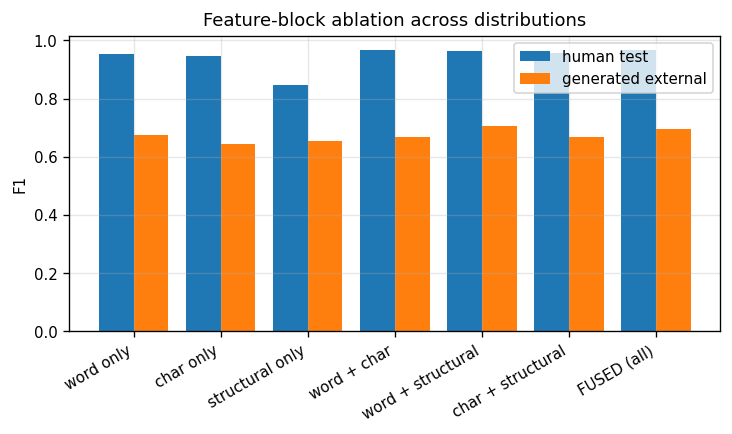

6

In [24]:
stamp("feature ablation")
BL = {"word only":        (Xw_tr, Xw_te, Xw_llm),
      "char only":        (Xc_tr, Xc_te, Xc_llm),
      "structural only":  (Ss_tr, Ss_te, Ss_llm),
      "word + char":      (sparse.hstack([Xw_tr, Xc_tr]).tocsr(),
                           sparse.hstack([Xw_te, Xc_te]).tocsr(),
                           sparse.hstack([Xw_llm, Xc_llm]).tocsr()),
      "word + structural":(sparse.hstack([Xw_tr, Ss_tr]).tocsr(),
                           sparse.hstack([Xw_te, Ss_te]).tocsr(),
                           sparse.hstack([Xw_llm, Ss_llm]).tocsr()),
      "char + structural":(sparse.hstack([Xc_tr, Ss_tr]).tocsr(),
                           sparse.hstack([Xc_te, Ss_te]).tocsr(),
                           sparse.hstack([Xc_llm, Ss_llm]).tocsr()),
      "FUSED (all)":      (X_tr, X_te, X_llm)}

rows = []
for name, (A, B, C_) in BL.items():
    m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, y_tr)
    pt, pl = m.predict_proba(B)[:, 1], m.predict_proba(C_)[:, 1]
    lo, hi = boot_ci(auc_m, y_llm, pl)
    rows.append({"block": name, "dim": A.shape[1],
                 "human_F1": f1_score(y_te, pt >= .5), "human_AUC": roc_auc_score(y_te, pt),
                 "llm_F1": f1_score(y_llm, pl >= .5), "llm_AUC": roc_auc_score(y_llm, pl),
                 "llm_AUC_ci_low": lo, "llm_AUC_ci_high": hi,
                 "llm_AUC_ci_contains_0.5": lo <= 0.5 <= hi})
    del m
T17 = register("feature_ablation", pd.DataFrame(rows).round(4))
display(T17)

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(T17))
ax.bar(x - .2, T17.human_F1, .4, label="human test")
ax.bar(x + .2, T17.llm_F1, .4, label="generated external")
ax.set_xticks(x); ax.set_xticklabels(T17.block, rotation=30, ha="right")
ax.set_ylabel("F1"); ax.set_title("Feature-block ablation across distributions"); ax.legend()
savefig("feature_ablation")

del BL
gc.collect()


## Part III: Detection Models (18–26)

### 18. Calibrated linear reference detector

**Closes:** Provides the like-for-like comparison point with the Logistic Regression baselines of Meléndez et al. and Uddin et al., but on the leakage-controlled partition of item 9.

In [25]:
stamp("classical detectors")
MODELS, PRED, PRED_SPACE = {}, {}, {}

SPARSE_SPEC = {
 "LogReg":         lambda: LogisticRegression(max_iter=900, C=4.0, class_weight="balanced"),
 "LinearSVM":      lambda: CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"),
                                                  method="sigmoid", cv=3),
 "ComplementNB":   lambda: ComplementNB(alpha=0.3),
 "SGD_ElasticNet": lambda: SGDClassifier(loss="modified_huber", penalty="elasticnet", alpha=1e-5,
                                         class_weight="balanced", max_iter=30, random_state=SEED),
}
DENSE_SPEC = {
 "RandomForest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                                class_weight="balanced_subsample", random_state=SEED),
 "HistGB":       lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                                        random_state=SEED),
}


def _prep(name, X):
    return abs(X) if name == "ComplementNB" else X


def fit_and_score(name, maker, Xtr, Xva, Xte, Xllm, space):
    t = time.time()
    m = maker().fit(_prep(name, Xtr), y_tr)
    fit_s = time.time() - t
    t = time.time()
    pte = m.predict_proba(_prep(name, Xte))[:, 1]
    infer = 1e6 * (time.time() - t) / max(Xte.shape[0], 1)
    MODELS[name] = m
    PRED_SPACE[name] = space
    PRED[name] = {"val": m.predict_proba(_prep(name, Xva))[:, 1],
                  "test": pte,
                  "llm": m.predict_proba(_prep(name, Xllm))[:, 1]}
    TIMING[name] = {"fit_seconds": fit_s, "infer_us_per_doc": infer,
                    "params": getattr(m, "n_features_in_", np.nan)}
    return m


for nm, mk in SPARSE_SPEC.items():
    fit_and_score(nm, mk, X_tr, X_va, X_te, X_llm, "fused")
    stamp("  fitted %s" % nm)
print("Linear reference established.")

[  951.3s |  2316 MB] classical detectors
[  992.6s |  2316 MB]   fitted LogReg
[ 1067.3s |  2316 MB]   fitted LinearSVM
[ 1068.4s |  2316 MB]   fitted ComplementNB
[ 1078.2s |  2316 MB]   fitted SGD_ElasticNet
Linear reference established.


### 19. Margin-based and probabilistic sparse detectors

**Closes:** Meléndez et al. report SVM and Naive Bayes as their strongest traditional models; both are reproduced here under the identical leakage-controlled protocol so the comparison is fair.

In [26]:
def evaluate(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"ACC": accuracy_score(y, yh), "BACC": balanced_accuracy_score(y, yh),
            "PREC": precision_score(y, yh, zero_division=0),
            "REC": recall_score(y, yh, zero_division=0),
            "F1": f1_score(y, yh, zero_division=0), "MCC": matthews_corrcoef(y, yh),
            "AUC": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "AP": average_precision_score(y, p) if len(set(y)) > 1 else np.nan,
            "BRIER": brier_score_loss(y, p),
            "FPR": fp / max(fp + tn, 1), "FNR": fn / max(fn + tp, 1)}


T19 = register("sparse_detectors",
                 pd.DataFrame([dict(Model=k, **evaluate(y_te, PRED[k]["test"]))
                               for k in SPARSE_SPEC]).round(4))
display(T19)

,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,LogReg,0.9705,0.9703,0.9689,0.9672,0.9681,0.9407,0.9941,0.9893,0.0248,0.0266,0.0328
1,LinearSVM,0.9665,0.9670,0.9552,0.9731,0.9641,0.9328,0.9922,0.9866,0.0575,0.0392,0.0269
2,ComplementNB,0.9325,0.9294,0.9614,0.8894,0.9240,0.8655,0.9777,0.9777,0.0559,0.0306,0.1106
3,SGD_ElasticNet,0.9389,0.9384,0.9359,0.9315,0.9337,0.8771,0.9394,0.9047,0.0608,0.0547,0.0685


### 20. Tree-ensemble detectors on the interpretable block

**Closes:** An et al. and Yau & Chia report Random Forest as their best model. Running the ensembles on the 56 structural features isolates how much performance is achievable without any lexical memorisation.

In [27]:
stamp("tree ensembles")
for nm, mk in DENSE_SPEC.items():
    fit_and_score(nm, mk, Sd_tr, Sd_va, Sd_te, Sd_llm, "structural")
    stamp("  fitted %s" % nm)

T20 = register("tree_ensembles",
                 pd.DataFrame([dict(Model=k, **evaluate(y_te, PRED[k]["test"]))
                               for k in DENSE_SPEC]).round(4))
display(T20)
print("These models never see a single word feature, so they cannot memorise corpus vocabulary.")

[ 1078.4s |  2316 MB] tree ensembles
[ 1088.4s |  2316 MB]   fitted RandomForest
[ 1090.1s |  2316 MB]   fitted HistGB


,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,RandomForest,0.9106,0.9078,0.9306,0.8713,0.9000,0.8207,0.9774,0.9750,0.0638,0.0557,0.1287
1,HistGB,0.9400,0.9390,0.9428,0.9263,0.9345,0.8793,0.9837,0.9818,0.0480,0.0482,0.0737


These models never see a single word feature, so they cannot memorise corpus vocabulary.


### 21. Corpus-shortcut suppression

**Closes:** Follows directly from the Corpus Fingerprint Leakage Index: features that best identify the *source corpus* are pruned, forcing the classifier onto transferable evidence.

**Definition (R1-4).** A multinomial logistic regression (C = 1) is fitted on the word TF-IDF channel of
the training split to predict the *source corpus*. Each word feature's shortcut score is its largest
absolute coefficient over corpora. The top *q* fraction by that score is removed from the word channel
(character and structural channels are untouched) and the phishing LR is refitted. *q* = 0.10 is
carried forward as the `LogReg_ShortcutSuppressed` detector.


In [28]:
stamp("shortcut suppression")
src_tr, src_names = pd.factorize(train["source"])
sup = LogisticRegression(max_iter=300, C=1.0).fit(Xw_tr, src_tr)
shortcut_score = np.abs(sup.coef_).max(axis=0)

rows, KEEP = [], None
for q in [0.0, 0.02, 0.05, 0.10, 0.20]:
    keep = (np.ones(Xw_tr.shape[1], bool) if q == 0
            else shortcut_score < np.quantile(shortcut_score, 1 - q))
    A = sparse.hstack([Xw_tr[:, keep],  Xc_tr,  Ss_tr ]).tocsr()
    B = sparse.hstack([Xw_te[:, keep],  Xc_te,  Ss_te ]).tocsr()
    Cm = sparse.hstack([Xw_llm[:, keep], Xc_llm, Ss_llm]).tocsr()
    m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, y_tr)
    pt, pl = m.predict_proba(B)[:, 1], m.predict_proba(Cm)[:, 1]
    a_, b_ = f1_score(y_te, pt >= .5), f1_score(y_llm, pl >= .5)
    rows.append({"suppressed_fraction": q, "word_features_kept": int(keep.sum()),
                 "human_F1": a_, "human_AUC": roc_auc_score(y_te, pt),
                 "llm_F1": b_, "llm_AUC": roc_auc_score(y_llm, pl),
                 "GGI_F1": (a_ - b_) / max(a_, 1e-9)})
    if q == 0.10:
        KEEP = keep
        MODELS["LogReg_ShortcutSuppressed"] = m
        PRED_SPACE["LogReg_ShortcutSuppressed"] = "suppressed"
        PRED["LogReg_ShortcutSuppressed"] = {
            "val":  m.predict_proba(sparse.hstack([Xw_va[:, keep], Xc_va, Ss_va]).tocsr())[:, 1],
            "test": pt, "llm": pl}
        TIMING["LogReg_ShortcutSuppressed"] = {"fit_seconds": np.nan, "infer_us_per_doc": np.nan}
    del A, B, Cm
    gc.collect()

T21 = register("shortcut_suppression", pd.DataFrame(rows).round(4))
display(T21)
del sup
gc.collect()

[ 1090.2s |  2316 MB] shortcut suppression


,suppressed_fraction,word_features_kept,human_F1,human_AUC,llm_F1,llm_AUC,GGI_F1
0,0.00,60000,0.9681,0.9941,0.6964,0.7589,0.2806
1,0.02,58798,0.9633,0.9928,0.6933,0.7542,0.2802
2,0.05,57000,0.9594,0.9920,0.6863,0.7472,0.2846
3,0.10,54000,0.9581,0.9914,0.6769,0.7320,0.2935
4,0.20,48000,0.9579,0.9906,0.6780,0.7340,0.2922


0

### 22. Shift-aware adaptation: importance weighting and stacked ensembling

**Definitions (R1-4).** *Importance weighting* (Shimodaira 2000; Sugiyama et al. 2007): a domain
classifier separates training messages from **unlabelled** generated messages; each training message is
weighted by the estimated density ratio p/(1−p), clipped to [0.1, 10], and the phishing LR is refitted
with those weights. *Stacking* (Wolpert 1992): the six classical base learners are fitted on the
training split; a logistic-regression meta-learner is fitted on their **validation-split**
probabilities, so it never sees predictions made on data the base learners were trained on. *Soft
voting* averages the six base probabilities.

**Revision.** The domain classifier previously used the full generated evaluation set. It now sees only
the adaptation **pool** (unlabelled), and results are also reported on the group-disjoint **hold-out**,
which neither the domain classifier nor any detector has seen.


In [29]:
stamp("importance weighting")
# Revision: unlabelled generated inputs come from the adaptation pool only
Xd = sparse.vstack([X_tr, X_llm[LLM_POOL]]).tocsr()
yd = np.r_[np.zeros(X_tr.shape[0]), np.ones(len(LLM_POOL))]
dw = LogisticRegression(max_iter=400, C=1.0, class_weight="balanced").fit(Xd, yd)
r = dw.predict_proba(X_tr)[:, 1]
w = np.clip(r / np.clip(1 - r, 1e-3, None), 0.1, 10.0)

m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(X_tr, y_tr, sample_weight=w)
MODELS["LogReg_ImportanceWeighted"] = m
PRED_SPACE["LogReg_ImportanceWeighted"] = "fused"
PRED["LogReg_ImportanceWeighted"] = {"val": m.predict_proba(X_va)[:, 1],
                                     "test": m.predict_proba(X_te)[:, 1],
                                     "llm": m.predict_proba(X_llm)[:, 1]}
TIMING["LogReg_ImportanceWeighted"] = {"fit_seconds": np.nan, "infer_us_per_doc": np.nan}

BASE = [k for k in ["LogReg", "LinearSVM", "ComplementNB", "SGD_ElasticNet",
                    "RandomForest", "HistGB"] if k in PRED]
Zva = np.column_stack([PRED[k]["val"] for k in BASE])
Zte = np.column_stack([PRED[k]["test"] for k in BASE])
Zllm = np.column_stack([PRED[k]["llm"] for k in BASE])
meta = LogisticRegression(max_iter=600, class_weight="balanced").fit(Zva, y_va)
PRED["StackedEnsemble"] = {"val": meta.predict_proba(Zva)[:, 1],
                           "test": meta.predict_proba(Zte)[:, 1],
                           "llm": meta.predict_proba(Zllm)[:, 1]}
PRED_SPACE["StackedEnsemble"] = "meta"
TIMING["StackedEnsemble"] = {"fit_seconds": np.nan, "infer_us_per_doc": np.nan}

PRED["SoftVoteEnsemble"] = {k2: np.mean([PRED[k]["%s" % k2] for k in BASE], axis=0)
                            for k2 in ["val", "test", "llm"]}
PRED_SPACE["SoftVoteEnsemble"] = "meta"
TIMING["SoftVoteEnsemble"] = {"fit_seconds": np.nan, "infer_us_per_doc": np.nan}

yh_ = y_llm[LLM_HOLD]
T22 = register("shift_adaptation", pd.DataFrame(
    [{"Model": k, "human_F1": f1_score(y_te, PRED[k]["test"] >= .5),
      "human_AUC": roc_auc_score(y_te, PRED[k]["test"]),
      "llm_F1": f1_score(y_llm, PRED[k]["llm"] >= .5),
      "llm_AUC": roc_auc_score(y_llm, PRED[k]["llm"]),
      "llm_holdout_F1": f1_score(yh_, PRED[k]["llm"][LLM_HOLD] >= .5),
      "llm_holdout_AUC": roc_auc_score(yh_, PRED[k]["llm"][LLM_HOLD])}
     for k in ["LogReg", "LogReg_ShortcutSuppressed", "LogReg_ImportanceWeighted",
               "SoftVoteEnsemble", "StackedEnsemble"]]).round(4))
display(T22)
print("Base learners stacked:", ", ".join(BASE))
print("Base learners fitted on train; meta-learner fitted on their validation-split probabilities.")
print("Importance-weight domain classifier saw only the unlabelled adaptation pool; use llm_holdout_* for it.")
del Xd, yd, dw
gc.collect()


[ 1329.7s |  2316 MB] importance weighting


,Model,human_F1,human_AUC,llm_F1,llm_AUC,llm_holdout_F1,llm_holdout_AUC
0,LogReg,0.9681,0.9941,0.6964,0.7589,0.6766,0.7335
1,LogReg_ShortcutSuppressed,0.9581,0.9914,0.6769,0.7320,0.6486,0.6995
2,LogReg_ImportanceWeighted,0.9453,0.9860,0.6805,0.7707,0.6676,0.7456
3,SoftVoteEnsemble,0.9643,0.9942,0.6771,0.7666,0.6617,0.7534
4,StackedEnsemble,0.9659,0.9948,0.6785,0.7676,0.6625,0.7511


Base learners stacked: LogReg, LinearSVM, ComplementNB, SGD_ElasticNet, RandomForest, HistGB
Base learners fitted on train; meta-learner fitted on their validation-split probabilities.
Importance-weight domain classifier saw only the unlabelled adaptation pool; use llm_holdout_* for it.


54

### 23. LSTM sequential detector

**Closes:** Retained from the original project notebook and from Atawneh & Aljehani, now trained on the leakage-controlled multilingual partition rather than a randomly split single corpus.

In [30]:
stamp("neural detectors")
HAS_TF = False
try:
    import tensorflow as tf
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Model
    from tensorflow.keras.layers import (Input, Embedding, LSTM, Bidirectional,
                                         Dense, Dropout, Concatenate, GlobalMaxPooling1D)
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
    print("TensorFlow", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))
except Exception as exc:
    print("TensorFlow unavailable (%s). the neural blocks will be skipped; all other novelties are unaffected."
          % type(exc).__name__)

MAX_WORDS, MAX_LEN = 60000, 300
if HAS_TF:
    tok = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
    tok.fit_on_texts(train["text"])
    seq = lambda d: pad_sequences(tok.texts_to_sequences(d["text"]), maxlen=MAX_LEN,
                                  padding="post", truncating="post")
    Q_tr, Q_va, Q_te, Q_llm = seq(train), seq(val), seq(test), seq(llm)

    def build(kind):
        inp = Input(shape=(MAX_LEN,))
        emb = Embedding(MAX_WORDS, 128, mask_zero=False)(inp)
        if kind == "LSTM":
            h = GlobalMaxPooling1D()(LSTM(128, return_sequences=True)(emb))
        elif kind == "BiLSTM":
            h = GlobalMaxPooling1D()(Bidirectional(LSTM(128, return_sequences=True))(emb))
        else:
            a = GlobalMaxPooling1D()(LSTM(128, return_sequences=True)(emb))
            b = GlobalMaxPooling1D()(Bidirectional(LSTM(128, return_sequences=True))(emb))
            h = Concatenate()([a, b])
        h = Dropout(0.5)(h)
        h = Dense(64, activation="relu")(h)
        h = Dropout(0.3)(h)
        m_ = Model(inp, Dense(1, activation="sigmoid")(h))
        m_.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
                   loss="binary_crossentropy", metrics=["accuracy"])
        return m_

    def train_neural(kind):
        t = time.time()
        m_ = build(kind)
        cw = {0: float(len(y_tr) / (2 * max((y_tr == 0).sum(), 1))),
              1: float(len(y_tr) / (2 * max((y_tr == 1).sum(), 1)))}
        hist = m_.fit(Q_tr, y_tr, validation_data=(Q_va, y_va), epochs=CFG["NEURAL_EPOCHS"],
                      batch_size=64, verbose=0, class_weight=cw,
                      callbacks=[EarlyStopping(monitor="val_auc" if False else "val_loss",
                                               patience=3, restore_best_weights=True)])
        if f1_score(y_va, (m_.predict(Q_va, verbose=0).ravel() >= .5).astype(int),
                    zero_division=0) < 0.25:
            print("   %s degenerate on validation; retraining with lower learning rate" % kind)
            m_ = build(kind)
            m_.optimizer.learning_rate.assign(3e-4)
            hist = m_.fit(Q_tr, y_tr, validation_data=(Q_va, y_va),
                          epochs=CFG["NEURAL_EPOCHS"] + 4, batch_size=64, verbose=0,
                          class_weight=cw,
                          callbacks=[EarlyStopping(monitor="val_loss", patience=4,
                                                   restore_best_weights=True)])
        MODELS[kind] = m_
        PRED_SPACE[kind] = "sequence"
        PRED[kind] = {"val": m_.predict(Q_va, verbose=0).ravel(),
                      "test": m_.predict(Q_te, verbose=0).ravel(),
                      "llm": m_.predict(Q_llm, verbose=0).ravel()}
        TIMING[kind] = {"fit_seconds": time.time() - t, "infer_us_per_doc": np.nan}
        return hist

    H_LSTM = train_neural("LSTM")
    stamp("  fitted LSTM")
    T23 = register("lstm", pd.DataFrame([dict(Model="LSTM", **evaluate(y_te, PRED["LSTM"]["test"]))]).round(4))
    display(T23)
else:
    T23 = pd.DataFrame()

[ 1372.6s |  2316 MB] neural detectors
TensorFlow 2.21.0 | GPU: True
[ 1416.4s |  2845 MB]   fitted LSTM


,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,LSTM,0.9565,0.9564,0.951,0.9549,0.953,0.9125,0.9904,0.9885,0.034,0.0422,0.0451


### 24. BiLSTM bidirectional detector

**Closes:** Bidirectional recurrence as used by Akçam et al. for URLs, applied here to full multilingual message text under identical conditions to item 23.

In [31]:
if HAS_TF:
    H_BILSTM = train_neural("BiLSTM")
    stamp("  fitted BiLSTM")
    T24 = register("bilstm",
                     pd.DataFrame([dict(Model="BiLSTM", **evaluate(y_te, PRED["BiLSTM"]["test"]))]).round(4))
    display(T24)
else:
    T24 = pd.DataFrame()
    print("skipped (no TensorFlow)")

[ 1460.0s |  2909 MB]   fitted BiLSTM


,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,BiLSTM,0.9665,0.966,0.9676,0.9596,0.9636,0.9326,0.9928,0.9919,0.0269,0.0276,0.0404


### 25. Hybrid dual-branch LSTM-BiLSTM fusion

**Closes:** The architecture proposed in the original project work, evaluated here with the group-disjoint split, external LLM test set and significance testing that the reviewed hybrid papers omit.

[ 1534.8s |  2982 MB]   fitted Hybrid


,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,LSTM,0.9565,0.9564,0.9510,0.9549,0.9530,0.9125,0.9904,0.9885,0.0340,0.0422,0.0451
1,BiLSTM,0.9665,0.9660,0.9676,0.9596,0.9636,0.9326,0.9928,0.9919,0.0269,0.0276,0.0404
2,Hybrid_LSTM_BiLSTM,0.9424,0.9405,0.9589,0.9146,0.9362,0.8847,0.9890,0.9864,0.0412,0.0336,0.0854


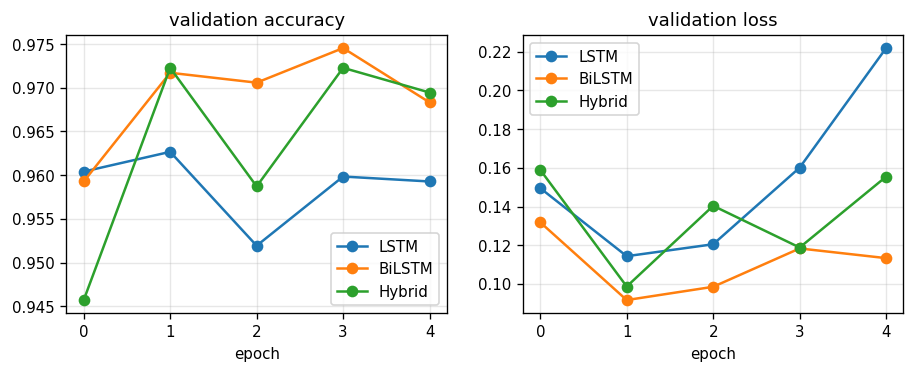

,Model,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,LogReg,0.9705,0.9703,0.9689,0.9672,0.9681,0.9407,0.9941,0.9893,0.0248,0.0266,0.0328
8,StackedEnsemble,0.9687,0.9681,0.9710,0.9608,0.9659,0.9369,0.9948,0.9942,0.0239,0.0246,0.0392
9,SoftVoteEnsemble,0.9673,0.9665,0.9732,0.9555,0.9643,0.9343,0.9942,0.9933,0.0324,0.0226,0.0445
1,LinearSVM,0.9665,0.9670,0.9552,0.9731,0.9641,0.9328,0.9922,0.9866,0.0575,0.0392,0.0269
11,BiLSTM,0.9665,0.9660,0.9676,0.9596,0.9636,0.9326,0.9928,0.9919,0.0269,0.0276,0.0404
6,LogReg_ShortcutSuppressed,0.9616,0.9608,0.9666,0.9497,0.9581,0.9228,0.9914,0.9858,0.0307,0.0281,0.0503
10,LSTM,0.9565,0.9564,0.9510,0.9549,0.9530,0.9125,0.9904,0.9885,0.0340,0.0422,0.0451
7,LogReg_ImportanceWeighted,0.9500,0.9490,0.9552,0.9356,0.9453,0.8995,0.9860,0.9773,0.0426,0.0377,0.0644
12,Hybrid_LSTM_BiLSTM,0.9424,0.9405,0.9589,0.9146,0.9362,0.8847,0.9890,0.9864,0.0412,0.0336,0.0854
5,HistGB,0.9400,0.9390,0.9428,0.9263,0.9345,0.8793,0.9837,0.9818,0.0480,0.0482,0.0737


In [32]:
if HAS_TF:
    H_HYB = train_neural("Hybrid_LSTM_BiLSTM")
    stamp("  fitted Hybrid")
    T25 = register("neural_comparison",
                     pd.DataFrame([dict(Model=k, **evaluate(y_te, PRED[k]["test"]))
                                   for k in ["LSTM", "BiLSTM", "Hybrid_LSTM_BiLSTM"]]).round(4))
    display(T25)

    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    for nm, h in [("LSTM", H_LSTM), ("BiLSTM", H_BILSTM), ("Hybrid", H_HYB)]:
        ax[0].plot(h.history["val_accuracy"], marker="o", label=nm)
        ax[1].plot(h.history["val_loss"], marker="o", label=nm)
    ax[0].set_title("validation accuracy"); ax[0].set_xlabel("epoch")
    ax[1].set_title("validation loss"); ax[1].set_xlabel("epoch")
    ax[0].legend(); ax[1].legend()
    savefig("neural_curves")
else:
    T25 = pd.DataFrame()
    print("skipped (no TensorFlow)")

T_MASTER = register("MASTER_human_test",
                    pd.DataFrame([dict(Model=k, **evaluate(y_te, v["test"]))
                                  for k, v in PRED.items()]).round(4).sort_values("F1", ascending=False))
display(T_MASTER)

### 26. Multilingual transformer baseline under identical conditions

**Closes:** The strongest results in the reviewed literature come from fine-tuned transformers: RoBERTa reaches 0.9943 in Melendez et al. and BERT-LSTM 99.61% in Atawneh and Aljehani, both English-only and within-corpus. Fine-tuning a multilingual encoder on the leakage-controlled partition and evaluating it under the same shift protocol tests whether contextual pretraining survives a change of generator, which no reviewed work establishes.

**Revision (R1-15, R1-14).** The checkpoint is `distilbert-base-multilingual-cased` (multilingual
DistilBERT, 6 layers), not multilingual BERT; the detector is now named `mDistilBERT_finetuned`
everywhere. Torch is seeded. A probe at the end of the cell tokenises a string with and without U+200B
to show directly that the tokenizer's text-cleaning step removes zero-width format characters before
WordPiece runs, which is the mechanism behind the transformer's zero-width robustness in item 35.


In [33]:
stamp("multilingual transformer")
TRANSFORMER_MODEL = "distilbert-base-multilingual-cased"
HAS_HF = False
try:
    import torch
    from torch.utils.data import TensorDataset, DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    HAS_HF = torch.cuda.is_available() or not FAST_MODE
    if not HAS_HF:
        print("No GPU detected; skipping transformer fine-tuning to keep runtime bounded.")
except Exception as exc:
    print("transformers/torch unavailable (%s); transformer baseline skipped." % type(exc).__name__)

if HAS_HF:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    MAXTOK = 256
    tk = AutoTokenizer.from_pretrained(TRANSFORMER_MODEL)

    def enc(texts):
        e = tk(list(texts), truncation=True, padding="max_length",
               max_length=MAXTOK, return_tensors="pt")
        return e["input_ids"], e["attention_mask"]

    def loader(df, y, bs, shuffle=False):
        ii, am = enc(df["text"].tolist())
        return DataLoader(TensorDataset(ii, am, torch.tensor(y, dtype=torch.long)),
                          batch_size=bs, shuffle=shuffle)

    L_tr = loader(train, y_tr, 16, True)
    L_va, L_te, L_llm = (loader(d_, y_, 64) for d_, y_ in
                         [(val, y_va), (test, y_te), (llm, y_llm)])

    mdl = AutoModelForSequenceClassification.from_pretrained(
        TRANSFORMER_MODEL, num_labels=2).to(dev)
    opt = torch.optim.AdamW(mdl.parameters(), lr=2e-5)
    epochs = 2 if FAST_MODE else 3
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=2e-5, total_steps=max(epochs * len(L_tr), 1), pct_start=0.1)
    amp_scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))

    t0_tf = time.time()
    mdl.train()
    for ep in range(epochs):
        tot = 0.0
        for ii, am, yy in L_tr:
            ii, am, yy = ii.to(dev), am.to(dev), yy.to(dev)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(dev == "cuda")):
                loss = mdl(input_ids=ii, attention_mask=am, labels=yy).loss
            amp_scaler.scale(loss).backward()
            amp_scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)
            amp_scaler.step(opt)
            amp_scaler.update()
            sched.step()
            tot += float(loss)
        print("   epoch %d  mean loss %.4f" % (ep + 1, tot / max(len(L_tr), 1)))
    fit_tf = time.time() - t0_tf

    @torch.no_grad()
    def infer(dl):
        mdl.eval()
        out = []
        for ii, am, _ in dl:
            with torch.amp.autocast("cuda", enabled=(dev == "cuda")):
                lg = mdl(input_ids=ii.to(dev), attention_mask=am.to(dev)).logits
            out.append(torch.softmax(lg.float(), -1)[:, 1].cpu().numpy())
        return np.concatenate(out)

    NAME_TF = "mDistilBERT_finetuned"   # Revision (R1-15): checkpoint is multilingual DistilBERT
    PRED[NAME_TF] = {"val": infer(L_va), "test": infer(L_te), "llm": infer(L_llm)}
    PRED_SPACE[NAME_TF] = "transformer"
    TIMING[NAME_TF] = {"fit_seconds": fit_tf, "infer_us_per_doc": np.nan}

    T26 = register("transformer", pd.DataFrame([
        dict(Model=NAME_TF, split="human test", **evaluate(y_te, PRED[NAME_TF]["test"])),
        dict(Model=NAME_TF, split="LLM external", **evaluate(y_llm, PRED[NAME_TF]["llm"]))]).round(4))
    display(T26)
    hf1 = f1_score(y_te, PRED[NAME_TF]["test"] >= .5)
    lf1 = f1_score(y_llm, PRED[NAME_TF]["llm"] >= .5)
    print("Transformer generalization gap (F1): %.4f" % ((hf1 - lf1) / max(hf1, 1e-9)))

    @torch.no_grad()
    def transformer_predict(texts, bs=64):
        mdl.eval()
        out = []
        for i in range(0, len(texts), bs):
            e = tk(list(texts[i:i + bs]), truncation=True, padding="max_length",
                   max_length=MAXTOK, return_tensors="pt")
            with torch.amp.autocast("cuda", enabled=(dev == "cuda")):
                lg = mdl(input_ids=e["input_ids"].to(dev),
                         attention_mask=e["attention_mask"].to(dev)).logits
            out.append(torch.softmax(lg.float(), -1)[:, 1].cpu().numpy())
        return np.concatenate(out)

    TEXT_PREDICTORS[NAME_TF] = transformer_predict
    gc.collect()
else:
    T26 = pd.DataFrame()

if HAS_HF:
    # Revision (R1-14, R2): show directly what the tokenizer does with zero-width characters
    probe = [("clean", "Click here to verify your account"),
             ("U+200B inserted", "Cl\u200bick h\u200bere to ver\u200bify your acc\u200bount"),
             ("U+200C/U+200D inserted", "Cl\u200cick h\u200dere to verify your account")]
    base_tokens = tk.tokenize(probe[0][1])
    T26z = pd.DataFrame([{"input": nm, "tokens": " ".join(tk.tokenize(s_)),
                          "identical_to_clean": tk.tokenize(s_) == base_tokens} for nm, s_ in probe])
    register("tokenizer_zero_width_probe", T26z)
    display(T26z)
    print("If identical_to_clean is True, the tokenizer's text cleaning drops these format (Cf) characters")
    print("before WordPiece, which explains the transformer's zero-width robustness in item 35.")


[ 1535.8s |  2982 MB] multilingual transformer


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

... (4 outputs left out)

,Model,split,ACC,BACC,PREC,REC,F1,MCC,AUC,AP,BRIER,FPR,FNR
0,mDistilBERT_finetuned,human test,0.9587,0.9567,0.9785,0.9310,0.9541,0.9175,0.9935,0.993,0.0387,0.0176,0.0690
1,mDistilBERT_finetuned,LLM external,0.6916,0.6931,0.6612,0.7549,0.7049,0.3886,0.7649,0.796,0.2841,0.3688,0.2451


Transformer generalization gap (F1): 0.2612


,input,tokens,identical_to_clean
0,clean,Cl ##ick here to veri ##fy your account,True
1,U+200B inserted,Cl ##ick here to veri ##fy your account,True
2,U+200C/U+200D inserted,Cl ##ick here to veri ##fy your account,True


If identical_to_clean is True, the tokenizer's text cleaning drops these format (Cf) characters
before WordPiece, which explains the transformer's zero-width robustness in item 35.


### 26b. Training settings of every detector

**Revision (R1-4).** One table with the configuration actually used for each detector, generated from the
objects in this notebook so it cannot drift from the code. No hyperparameter search was run: all values
are fixed a priori, and early stopping (recurrent models) uses the validation split only.


In [34]:
rows = []
for k, mk in SPARSE_SPEC.items():
    rows.append({"detector": k, "input": "fused sparse (word + char + structural)",
                 "configuration": repr(mk()).replace("\n", " ")})
rows.append({"detector": "ComplementNB (note)", "input": "fused sparse, absolute values",
             "configuration": "negative standardised structural values made non-negative with |x|"})
for k, mk in DENSE_SPEC.items():
    rows.append({"detector": k, "input": "56 structural descriptors (unscaled)",
                 "configuration": repr(mk()).replace("\n", " ")})
rows.append({"detector": "LogReg_ShortcutSuppressed", "input": "fused sparse minus top-10% corpus-predictive word features",
             "configuration": "LogisticRegression(C=4, class_weight=balanced, max_iter=900); shortcut probe LR(C=1) on word channel"})
rows.append({"detector": "LogReg_ImportanceWeighted", "input": "fused sparse",
             "configuration": "LR(C=4, balanced); weights p/(1-p) from LR(C=1) domain classifier train-vs-pool, clipped [0.1, 10]"})
rows.append({"detector": "StackedEnsemble", "input": "validation probabilities of %s" % ", ".join(BASE),
             "configuration": "LogisticRegression(class_weight=balanced, max_iter=600) meta-learner"})
rows.append({"detector": "SoftVoteEnsemble", "input": ", ".join(BASE), "configuration": "unweighted mean of probabilities"})
if HAS_TF:
    for k in ["LSTM", "BiLSTM", "Hybrid_LSTM_BiLSTM"]:
        rows.append({"detector": k, "input": "word index sequences (Keras Tokenizer, vocab %d, OOV token), length %d, post-pad/truncate" % (MAX_WORDS, MAX_LEN),
                     "configuration": ("Embedding(%d,128) -> %s(128, return_sequences) -> GlobalMaxPool -> Dropout(0.5) -> Dense(64, ReLU) "
                                       "-> Dropout(0.3) -> Dense(1, sigmoid); Adam(lr=1e-3, clipnorm=1.0), BCE, batch 64, "
                                       "max %d epochs, EarlyStopping(val_loss, patience=3, restore best), class weights balanced; "
                                       "fallback retrain at lr=3e-4 if val F1 < 0.25")
                                      % (MAX_WORDS, {"LSTM": "LSTM", "BiLSTM": "Bidirectional(LSTM)",
                                                     "Hybrid_LSTM_BiLSTM": "[LSTM || Bidirectional(LSTM)] concatenated"}[k],
                                         CFG["NEURAL_EPOCHS"])})
if HAS_HF:
    rows.append({"detector": NAME_TF, "input": "%s tokenizer, max %d tokens, padded" % (TRANSFORMER_MODEL, MAXTOK),
                 "configuration": ("AutoModelForSequenceClassification(%s, 2 labels); AdamW lr=2e-5, OneCycleLR (10%% warm-up), "
                                   "%d epochs, batch 16, grad-clip 1.0, mixed precision, seed %d") % (TRANSFORMER_MODEL, epochs, SEED)})
T26b = register("hyperparameters", pd.DataFrame(rows))
with pd.option_context("display.max_colwidth", 200):
    display(T26b)


,detector,input,configuration
0,LogReg,fused sparse (word + char + structural),"LogisticRegression(C=4.0, class_weight='balanced', max_iter=900)"
1,LinearSVM,fused sparse (word + char + structural),"CalibratedClassifierCV(cv=3, estimator=LinearSVC(C=0.5, class_weight='balanced'))"
2,ComplementNB,fused sparse (word + char + structural),ComplementNB(alpha=0.3)
3,SGD_ElasticNet,fused sparse (word + char + structural),"SGDClassifier(alpha=1e-05, class_weight='balanced', loss='modified_huber', max_iter=30, penalty='elasticnet', random_state=42)"
4,ComplementNB (note),"fused sparse, absolute values",negative standardised structural values made non-negative with |x|
5,RandomForest,56 structural descriptors (unscaled),"RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2, n_estimators=300, n_jobs=-1, random_state=42)"
6,HistGB,56 structural descriptors (unscaled),"HistGradientBoostingClassifier(max_iter=300, random_state=42)"
7,LogReg_ShortcutSuppressed,fused sparse minus top-10% corpus-predictive word features,"LogisticRegression(C=4, class_weight=balanced, max_iter=900); shortcut probe LR(C=1) on word channel"
8,LogReg_ImportanceWeighted,fused sparse,"LR(C=4, balanced); weights p/(1-p) from LR(C=1) domain classifier train-vs-pool, clipped [0.1, 10]"
9,StackedEnsemble,"validation probabilities of LogReg, LinearSVM, ComplementNB, SGD_ElasticNet, RandomForest, HistGB","LogisticRegression(class_weight=balanced, max_iter=600) meta-learner"


## Part IV: Generative Distribution Shift (27–33)

### 27. Generative Shift Protocol (GSP)

**Closes:** Opara et al. study AI-generated phishing on **63 emails** and name dataset size as their principal limitation.

**Revision (R1-13, R1-16, R2).** The headline external set is now the E-PhishLLM collection only (the
unattributed source is reported separately in item 37b). Its languages are printed below; Italian occurs
only in generated mail and never in human training data, which is itself a shift the paper must name.
Item 27b breaks the result down by language, as reviewer 2 requested.


In [35]:
stamp("generative shift protocol")
T27 = register("generative_shift", pd.DataFrame(
    [dict(Model=k, **{"llm_" + a: b for a, b in evaluate(y_llm, v["llm"]).items()})
     for k, v in PRED.items()]).round(4).sort_values("llm_F1", ascending=False))
display(T27)
print("External set: %d generated messages (%d phishing / %d legitimate) from %s"
      % (len(llm), int(y_llm.sum()), int((1 - y_llm).sum()), ", ".join(llm["source"].unique())))
print("Languages:", llm["lang"].value_counts().to_dict())
print("Scale relative to Opara et al. (63 emails): %.0fx" % (len(llm) / 63))


[ 1822.5s |  5252 MB] generative shift protocol


,Model,llm_ACC,llm_BACC,llm_PREC,llm_REC,llm_F1,llm_MCC,llm_AUC,llm_AP,llm_BRIER,llm_FPR,llm_FNR
10,LSTM,0.7004,0.7025,0.6619,0.7893,0.7200,0.4104,0.7901,0.8297,0.2697,0.3844,0.2107
11,BiLSTM,0.7020,0.7032,0.6740,0.7541,0.7118,0.4081,0.7587,0.7739,0.2683,0.3477,0.2459
12,Hybrid_LSTM_BiLSTM,0.6708,0.6744,0.6232,0.8230,0.7093,0.3641,0.7990,0.8350,0.2596,0.4742,0.1770
13,mDistilBERT_finetuned,0.6916,0.6931,0.6612,0.7549,0.7049,0.3886,0.7649,0.7960,0.2841,0.3688,0.2451
2,ComplementNB,0.6872,0.6885,0.6596,0.7418,0.6983,0.3787,0.7701,0.8311,0.2589,0.3648,0.2582
0,LogReg,0.6708,0.6732,0.6331,0.7738,0.6964,0.3529,0.7589,0.7968,0.2202,0.4273,0.2262
7,LogReg_ImportanceWeighted,0.5936,0.6005,0.5520,0.8869,0.6805,0.2441,0.7707,0.8105,0.2447,0.6859,0.1131
8,StackedEnsemble,0.6072,0.6129,0.5649,0.8492,0.6785,0.2552,0.7676,0.8099,0.2935,0.6234,0.1508
9,SoftVoteEnsemble,0.5964,0.6027,0.5554,0.8672,0.6771,0.2412,0.7666,0.8096,0.2415,0.6617,0.1328
6,LogReg_ShortcutSuppressed,0.6448,0.6476,0.6086,0.7623,0.6769,0.3026,0.7320,0.7678,0.2381,0.4672,0.2377


External set: 2500 generated messages (1220 phishing / 1280 legitimate) from E-PhishLLM
Languages: {'English': 1754, 'Italian': 392, 'German': 343, 'Spanish': 6, 'French': 4, 'CJK': 1}
Scale relative to Opara et al. (63 emails): 40x


### 27b. Generative shift by language

**Revision (R2).** The generated set mixes English, Italian and German. Reporting each language separately
shows whether the collapse is a generator effect (present in English, which dominates training) or a
language effect (concentrated in Italian, unseen in training, and German, seen mostly as translated SMS).


In [36]:
rows = []
for k, v in PRED.items():
    for lg, d in llm.groupby("lang"):
        if len(d) < 40 or d["y"].nunique() < 2:
            continue
        ix = d.index.values
        rows.append({"Model": k, "language": lg, "n": len(d), "phishing_rate": d["y"].mean(),
                     "F1": f1_score(d["y"], v["llm"][ix] >= .5), "AUC": roc_auc_score(d["y"], v["llm"][ix]),
                     "MCC": matthews_corrcoef(d["y"], v["llm"][ix] >= .5)})
T27b = register("generative_shift_by_language", pd.DataFrame(rows).round(4))
display(T27b.pivot_table(index="Model", columns="language", values="AUC").round(4))
display(T27b.groupby("language")[["n", "F1", "AUC", "MCC"]].mean().round(4))


language,English,German,Italian
Model,,,
BiLSTM,0.8491,0.7001,0.4204
ComplementNB,0.9010,0.7614,0.7596
HistGB,0.7215,0.5221,0.5779
Hybrid_LSTM_BiLSTM,0.8668,0.6642,0.6165
LSTM,0.8782,0.6521,0.5448
LinearSVM,0.7630,0.6811,0.6419
LogReg,0.8316,0.6986,0.5556
LogReg_ImportanceWeighted,0.8268,0.7333,0.6479
LogReg_ShortcutSuppressed,0.8145,0.6521,0.5476


,n,F1,AUC,MCC
language,,,,
English,1754.0,0.7353,0.8131,0.3797
German,343.0,0.5184,0.6690,0.2510
Italian,392.0,0.5645,0.6115,0.0464


### 28. Generalization Gap Index (GGI)

**Closes:** Reviewed studies report only in-distribution scores. GGI is a single normalised number expressing how much of a detector's performance is lost when the generator changes, making models comparable.

[ 1823.4s |  5252 MB] generalization gap index


,Model,human_F1,llm_F1,human_AUC,llm_AUC,GGI_F1,GGI_AUC
12,Hybrid_LSTM_BiLSTM,0.9362,0.7093,0.9890,0.7990,0.2424,0.3886
2,ComplementNB,0.9240,0.6983,0.9777,0.7701,0.2443,0.4347
10,LSTM,0.9530,0.7200,0.9904,0.7901,0.2445,0.4085
13,mDistilBERT_finetuned,0.9541,0.7049,0.9935,0.7649,0.2612,0.4631
11,BiLSTM,0.9636,0.7118,0.9928,0.7587,0.2613,0.4751
4,RandomForest,0.9000,0.6632,0.9774,0.7415,0.2631,0.4941
7,LogReg_ImportanceWeighted,0.9453,0.6805,0.9860,0.7707,0.2801,0.4429
0,LogReg,0.9681,0.6964,0.9941,0.7589,0.2806,0.4761
6,LogReg_ShortcutSuppressed,0.9581,0.6769,0.9914,0.7320,0.2935,0.5278
3,SGD_ElasticNet,0.9337,0.6574,0.9394,0.6124,0.2959,0.7442


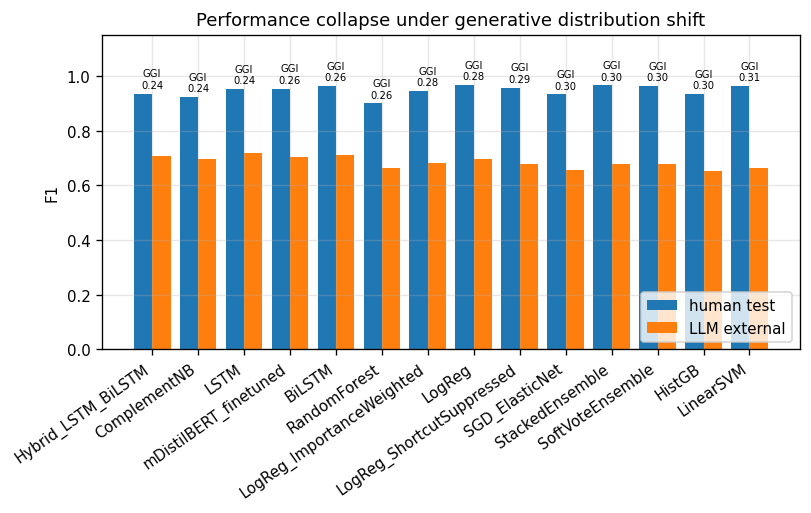

In [37]:
stamp("generalization gap index")
rows = []
for k, v in PRED.items():
    a_, b_ = evaluate(y_te, v["test"]), evaluate(y_llm, v["llm"])
    rows.append({"Model": k, "human_F1": a_["F1"], "llm_F1": b_["F1"],
                 "human_AUC": a_["AUC"], "llm_AUC": b_["AUC"],
                 "GGI_F1": (a_["F1"] - b_["F1"]) / max(a_["F1"], 1e-9),
                 "GGI_AUC": (a_["AUC"] - b_["AUC"]) / max(a_["AUC"] - 0.5, 1e-9)})
T28 = register("generalization_gap", pd.DataFrame(rows).round(4).sort_values("GGI_F1"))
display(T28)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(T28))
ax.bar(x - .2, T28.human_F1, .4, label="human test")
ax.bar(x + .2, T28.llm_F1, .4, label="LLM external")
for i, g in enumerate(T28.GGI_F1):
    ax.text(i, max(T28.human_F1.iloc[i], .05) + .02, "GGI\n%.2f" % g, ha="center", fontsize=6)
ax.set_xticks(x); ax.set_xticklabels(T28.Model, rotation=35, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1.15)
ax.set_title("Performance collapse under generative distribution shift")
ax.legend(loc="lower right")
savefig("generalization_gap")

### 29. Domain discriminability and proxy A-distance

**Closes:** Quantifies how far apart human-written and LLM-generated phishing actually are. Establishes that the shift is real and severe rather than an artefact of a weak detector.

In [38]:
stamp("domain discriminability")
Xd = sparse.vstack([X_te, X_llm]).tocsr()
yd = np.r_[np.zeros(X_te.shape[0]), np.ones(X_llm.shape[0])]
errs = []
for a_, b_ in StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xd, yd):
    m = LogisticRegression(max_iter=500, class_weight="balanced").fit(Xd[a_], yd[a_])
    errs.append(1 - accuracy_score(yd[b_], m.predict(Xd[b_])))
err = float(np.mean(errs))

T29 = register("domain_distance", pd.DataFrame({
    "metric": ["domain-classifier error", "proxy A-distance (0=identical, 2=separable)",
               "phishing-class rate, human", "phishing-class rate, LLM"],
    "value": [round(err, 4), round(2 * (1 - 2 * err), 4),
              round(float(y_te.mean()), 4), round(float(y_llm.mean()), 4)]}))
display(T29)
print("A proxy A-distance near 2 confirms the two generators occupy nearly disjoint regions,")
print("so the observed collapse reflects genuine domain shift and not detector weakness.")
del Xd, yd
gc.collect()

[ 1824.6s |  5252 MB] domain discriminability


,metric,value
0,domain-classifier error,0.0095
1,"proxy A-distance (0=identical, 2=separable)",1.9619
2,"phishing-class rate, human",0.4618
3,"phishing-class rate, LLM",0.4880


A proxy A-distance near 2 confirms the two generators occupy nearly disjoint regions,
so the observed collapse reflects genuine domain shift and not detector weakness.


7143

### 29b. Matched-medium control for the generative shift

**Revision (R2).** A proxy A-distance near 2 shows the generated set is a separate domain, but CFLI already
shows that every corpus is separable from every other. The fair comparison holds **language and medium
fixed** and asks whether generated mail is harder than an *unseen human* email corpus. Three checks, all
with the same fused logistic regression (C = 4, balanced) refitted from scratch:

1. PAD between English generated email and English human email, alongside PADs between pairs of human
   email corpora (is the generated set more separable than one human corpus is from another?);
2. for each two-class human email corpus *H*: train on the training split **without H** (and without any
   group shared with H), then test on *H* and on English generated email;
3. the drop on *H* is the cost of an unseen human corpus; the extra drop on generated mail is what can be
   attributed to generation.


In [39]:
stamp("matched-medium control")
SD_HUMAN = build_struct_matrix(human["text"].tolist())   # cached once, reused by items 32-33
SD_LLM = Sd_llm


def fit_predict(tr_text, tr_S, ytr, test_sets, mode="fused", word_max=40000, C=4.0):
    """Refit word TF-IDF (+ char hashing + scaled structural) on the training texts only, then score each test set."""
    wv = TfidfVectorizer(max_features=word_max, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    Aw = wv.fit_transform(tr_text)
    if mode == "word":
        m = LogisticRegression(max_iter=900, C=C, class_weight="balanced").fit(Aw, ytr)
        return [m.predict_proba(wv.transform(t))[:, 1] for t, _ in test_sets]
    sc = StandardScaler().fit(tr_S)
    A = sparse.hstack([Aw, char_vec.transform(tr_text), sparse.csr_matrix(sc.transform(tr_S))]).tocsr()
    m = LogisticRegression(max_iter=900, C=C, class_weight="balanced").fit(A, ytr)
    out = []
    for t, S in test_sets:
        B = sparse.hstack([wv.transform(t), char_vec.transform(t), sparse.csr_matrix(sc.transform(S))]).tocsr()
        out.append(m.predict_proba(B)[:, 1])
    return out


def pad_texts(ta, tb, seed=SEED):
    """Proxy A-distance 2(1-2e) from a 3-fold word TF-IDF domain classifier on balanced samples."""
    n = min(len(ta), len(tb))
    rs = np.random.RandomState(seed)
    ta = list(np.asarray(ta, dtype=object)[rs.choice(len(ta), n, replace=False)])
    tb = list(np.asarray(tb, dtype=object)[rs.choice(len(tb), n, replace=False)])
    X = TfidfVectorizer(max_features=40000, ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(ta + tb)
    yd = np.r_[np.zeros(n), np.ones(n)]
    errs = []
    for a_, b_ in StratifiedKFold(3, shuffle=True, random_state=seed).split(X, yd):
        mm = LogisticRegression(max_iter=500).fit(X[a_], yd[a_])
        errs.append(1 - accuracy_score(yd[b_], mm.predict(X[b_])))
    return 2 * (1 - 2 * float(np.mean(errs))), n


hum_en_email = human[(human["channel"] == "email") & (human["lang"] == "English")]
gen_en = llm[llm["lang"] == "English"]
email_corpora = [s for s in hum_en_email["source"].unique()
                 if hum_en_email.loc[hum_en_email.source == s, "y"].nunique() == 2]

rows = []
if len(gen_en) >= 50:
    for s in email_corpora:
        p, n = pad_texts(hum_en_email.loc[hum_en_email.source == s, "text"].tolist(), gen_en["text"].tolist())
        rows.append({"pair": "%s vs generated (EN email)" % s, "type": "human vs generated", "n_per_side": n, "PAD": p})
for i, a in enumerate(email_corpora):
    for b in email_corpora[i + 1:]:
        p, n = pad_texts(hum_en_email.loc[hum_en_email.source == a, "text"].tolist(),
                         hum_en_email.loc[hum_en_email.source == b, "text"].tolist())
        rows.append({"pair": "%s vs %s" % (a, b), "type": "human vs human", "n_per_side": n, "PAD": p})
T29b = register("pad_matched_medium", pd.DataFrame(rows).round(4))
display(T29b)
if len(T29b):
    display(T29b.groupby("type")["PAD"].agg(["mean", "min", "max"]).round(4))

rows = []
gen_ix = gen_en.index.values
for s in email_corpora:
    held = human[human["source"] == s]
    held_groups = set(held["group"])
    keep = (train["source"] != s).values & ~train["group"].isin(held_groups).values
    held_S = SD_HUMAN[held.index.values]
    ph, pg = fit_predict(train["text"][keep].tolist(), Sd_tr[keep], y_tr[keep],
                         [(held["text"].tolist(), held_S), (gen_en["text"].tolist(), SD_LLM[gen_ix])])
    rows.append({"held_out_human_corpus": s, "n_held": len(held), "n_generated_EN": len(gen_en),
                 "held_human_F1": f1_score(held["y"], ph >= .5), "held_human_AUC": roc_auc_score(held["y"], ph),
                 "generated_EN_F1": f1_score(gen_en["y"], pg >= .5),
                 "generated_EN_AUC": roc_auc_score(gen_en["y"], pg) if gen_en["y"].nunique() == 2 else np.nan})
    gc.collect()
T29c = register("unseen_human_vs_generated", pd.DataFrame(rows).round(4))
display(T29c)
if len(T29c):
    print("Mean AUC on an unseen human email corpus: %.4f | on English generated email: %.4f"
          % (T29c.held_human_AUC.mean(), T29c.generated_EN_AUC.mean()))


[ 1844.3s |  5626 MB] matched-medium control


,pair,type,n_per_side,PAD
0,CEAS_08 vs generated (EN email),human vs generated,1754,1.9977
1,Enron vs generated (EN email),human vs generated,1754,1.9886
2,Ling vs generated (EN email),human vs generated,1754,1.9977
3,SpamAssassin vs generated (EN email),human vs generated,1754,2.0000
4,CEAS_08 vs Enron,human vs human,2470,1.7668
5,CEAS_08 vs Ling,human vs human,2454,1.8329
6,CEAS_08 vs SpamAssassin,human vs human,2490,1.8120
7,Enron vs Ling,human vs human,2454,1.8427
8,Enron vs SpamAssassin,human vs human,2470,1.7263
9,Ling vs SpamAssassin,human vs human,2454,1.8313


,mean,min,max
type,,,
human vs generated,1.996,1.9886,2.0000
human vs human,1.802,1.7263,1.8427


,held_out_human_corpus,n_held,n_generated_EN,held_human_F1,held_human_AUC,generated_EN_F1,generated_EN_AUC
0,CEAS_08,2500,1754,0.8541,0.9133,0.7402,0.8296
1,Enron,2500,1754,0.7604,0.8314,0.7112,0.8288
2,Ling,2500,1754,0.8594,0.9846,0.7440,0.8080
3,SpamAssassin,2500,1754,0.8166,0.9395,0.7699,0.8502


Mean AUC on an unseen human email corpus: 0.9172 | on English generated email: 0.8292


### 30. Progressive LLM-exposure curve

**Closes:** Moves from diagnosis to remedy. Quantifies how many generated samples are needed to recover performance, and what that costs on the original human distribution.

**Revision (R2).** Injected samples come from the adaptation **pool** and evaluation uses the **hold-out**
defined in item 9; the two share no MinHash near-duplicate group (asserted below), so recovery cannot
come from near-twins of injected messages.


[ 2232.5s |  6373 MB] progressive exposure
pool 1292 | hold-out 1208 | shared near-duplicate groups: 0


,llm_fraction,llm_samples_added,llm_holdout_F1,llm_holdout_AUC,human_test_F1
0,0.00,0,0.6776,0.7327,0.9680
1,0.02,25,0.6905,0.7846,0.9672
2,0.05,64,0.7183,0.8210,0.9674
3,0.10,129,0.7624,0.8674,0.9674
4,0.25,323,0.8336,0.9283,0.9653
5,0.50,646,0.8907,0.9628,0.9656
6,1.00,1292,0.9241,0.9800,0.9659


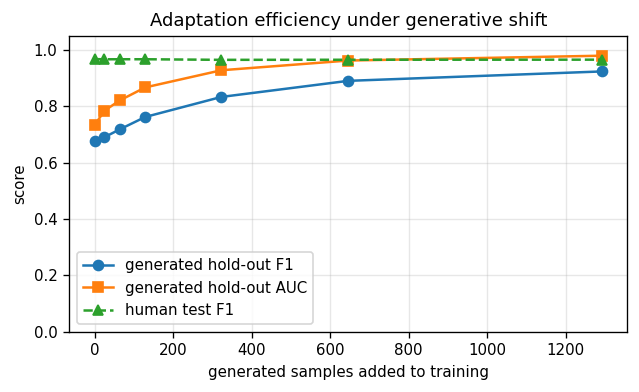

In [40]:
stamp("progressive exposure")
pool, hold = LLM_POOL, LLM_HOLD
shared = set(llm["group"].iloc[pool]) & set(llm["group"].iloc[hold])
assert not shared, "near-duplicate groups shared between pool and hold-out"
print("pool %d | hold-out %d | shared near-duplicate groups: %d" % (len(pool), len(hold), len(shared)))
Xh, yh_ = X_llm[hold], y_llm[hold]

rows = []
for frac in [0.0, 0.02, 0.05, 0.10, 0.25, 0.50, 1.0]:
    k = int(frac * len(pool))
    A = sparse.vstack([X_tr, X_llm[pool[:k]]]).tocsr() if k else X_tr
    ya_ = np.r_[y_tr, y_llm[pool[:k]]] if k else y_tr
    m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, ya_)
    ph, pt = m.predict_proba(Xh)[:, 1], m.predict_proba(X_te)[:, 1]
    rows.append({"llm_fraction": frac, "llm_samples_added": k,
                 "llm_holdout_F1": f1_score(yh_, ph >= .5),
                 "llm_holdout_AUC": roc_auc_score(yh_, ph),
                 "human_test_F1": f1_score(y_te, pt >= .5)})
    del A, m
    gc.collect()

T30 = register("exposure_curve", pd.DataFrame(rows).round(4))
display(T30)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(T30.llm_samples_added, T30.llm_holdout_F1, "o-", label="generated hold-out F1")
ax.plot(T30.llm_samples_added, T30.llm_holdout_AUC, "s-", label="generated hold-out AUC")
ax.plot(T30.llm_samples_added, T30.human_test_F1, "^--", label="human test F1")
ax.set_xlabel("generated samples added to training"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05)
ax.set_title("Adaptation efficiency under generative shift"); ax.legend()
savefig("exposure_curve")


### 31. Transfer of adaptation: generator holdout (diagnostic) and language holdout (result)

**Revision (R1-13, R2).** Holding out one generator requires two trustworthy generators. Only one
remains once `LLM_Unattributed` is set aside, so:

* **31a (diagnostic)** keeps the original generator-holdout on *all* generated data, plus a direct
  label-inversion check: AUC of the human-trained LR on each generated source with labels as given and
  with labels flipped. An AUC far below 0.5 that becomes far above 0.5 when flipped is a labelling
  problem, not a transfer result. Nothing from 31a is used in adaptation claims.
* **31b (result)** asks the same question inside the headline generator: adapt on two of its languages,
  test on the third (groups shared with the held-out language removed), and compare with no adaptation.


In [41]:
stamp("generator / language holdout")
X_llm_all = featurize(llm_all["text"].tolist())
y_all = llm_all["y"].values

# 31a: label-inversion check per generated source (human-trained LR, no adaptation)
p_all = MODELS["LogReg"].predict_proba(X_llm_all)[:, 1]
rows = []
for g, d in llm_all.groupby("source"):
    ix = d.index.values
    if d["y"].nunique() < 2:
        continue
    rows.append({"source": g, "n": len(d), "phishing_rate": d["y"].mean(),
                 "AUC_labels_as_given": roc_auc_score(d["y"], p_all[ix]),
                 "AUC_labels_flipped": roc_auc_score(1 - d["y"], p_all[ix])})
T31a = register("label_inversion_check", pd.DataFrame(rows).round(4))
display(T31a)

rows = []
for g in llm_all["source"].unique():
    seen = llm_all[llm_all["source"] != g]
    unseen = llm_all[llm_all["source"] == g]
    if unseen["y"].nunique() < 2 or len(seen) < 50:
        continue
    A = sparse.vstack([X_tr, X_llm_all[seen.index.values]]).tocsr()
    m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, np.r_[y_tr, seen["y"].values])
    p = m.predict_proba(X_llm_all[unseen.index.values])[:, 1]
    auc = roc_auc_score(unseen["y"], p)
    rows.append({"held_out_generator": g, "trained_on": ", ".join(seen["source"].unique()), "n": len(unseen),
                 "F1": f1_score(unseen["y"], p >= .5), "AUC": auc,
                 "diagnosis": "labels likely inverted (AUC < 0.5)" if auc < 0.5 else
                              ("adapted on a flagged source" if "LLM_Unattributed" in set(seen["source"]) else "ok")})
    del A, m
    gc.collect()
T31 = register("generator_holdout_diagnostic", pd.DataFrame(rows).round(4))
display(T31)
print("31a is a data-quality diagnostic only and is not used for adaptation claims.")

# 31b: language holdout within the headline generator
rows = []
for lg, d in llm.groupby("lang"):
    if len(d) < 100 or d["y"].nunique() < 2:
        continue
    unseen_ix = d.index.values
    seen = llm[(llm["lang"] != lg) & ~llm["group"].isin(set(d["group"]))]
    if len(seen) < 50:
        continue
    A = sparse.vstack([X_tr, X_llm[seen.index.values]]).tocsr()
    m = LogisticRegression(max_iter=900, C=4.0, class_weight="balanced").fit(A, np.r_[y_tr, seen["y"].values])
    p = m.predict_proba(X_llm[unseen_ix])[:, 1]
    p0 = PRED["LogReg"]["llm"][unseen_ix]
    rows.append({"held_out_language": lg, "n": len(d), "adapted_on": ", ".join(sorted(seen["lang"].unique())),
                 "n_adapt": len(seen),
                 "no_adapt_F1": f1_score(d["y"], p0 >= .5), "no_adapt_AUC": roc_auc_score(d["y"], p0),
                 "adapted_F1": f1_score(d["y"], p >= .5), "adapted_AUC": roc_auc_score(d["y"], p)})
    del A, m
    gc.collect()
T31b = register("language_holdout_adaptation", pd.DataFrame(rows).round(4))
display(T31b)


[ 2528.7s |  6373 MB] generator / language holdout


,source,n,phishing_rate,AUC_labels_as_given,AUC_labels_flipped
0,E-PhishLLM,2500,0.4880,0.7589,0.2411
1,LLM_Unattributed,1161,0.1404,0.1344,0.8656


,held_out_generator,trained_on,n,F1,AUC,diagnosis
0,E-PhishLLM,LLM_Unattributed,2500,0.5292,0.7187,adapted on a flagged source
1,LLM_Unattributed,E-PhishLLM,1161,0.0831,0.1812,labels likely inverted (AUC < 0.5)


31a is a data-quality diagnostic only and is not used for adaptation claims.


,held_out_language,n,adapted_on,n_adapt,no_adapt_F1,no_adapt_AUC,adapted_F1,adapted_AUC
0,English,1754,"CJK, French, German, Italian, Spanish",746,0.7581,0.8316,0.8252,0.9202
1,German,343,"CJK, English, French, Italian, Spanish",2157,0.5150,0.6986,0.6426,0.8917
2,Italian,392,"CJK, English, French, German, Spanish",2108,0.5579,0.5556,0.6427,0.9033


### 32. Leave-one-language-out cross-lingual transfer

**Closes:** An et al. evaluate English and machine-translated Arabic only. Here each language is fully removed from training and used as a zero-shot target, including genuinely low-resource Bangla.

**Revision (R2).** (i) Every leakage group that contains a held-out-language message is removed from
training, so translations of held-out French or German messages (which share numbers, URLs and names)
can no longer sit in training under another language. (ii) The structural scaler and the word
vocabulary are refitted on each training fold. (iii) Word-only and fused LR use identical settings
(C = 4, balanced, as the main LogReg) so the two columns differ only in features.


In [42]:
stamp("leave-one-language-out (translation siblings removed)")
rows = []
for lg in [l for l, n in human["lang"].value_counts().items() if n >= 150]:
    te_mask = (human["lang"] == lg).values
    held_groups = set(human.loc[te_mask, "group"])
    tr_mask = ~te_mask & ~human["group"].isin(held_groups).values
    te_, tr_ = human[te_mask], human[tr_mask]
    if te_["y"].nunique() < 2 or len(tr_) < 200 or tr_["y"].nunique() < 2:
        continue
    n_sib = int((~te_mask).sum() - tr_mask.sum())
    tt = [(te_["text"].tolist(), SD_HUMAN[te_mask])]
    p1, = fit_predict(tr_["text"].tolist(), None, tr_["y"].values, tt, mode="word", C=4.0)
    p2, = fit_predict(tr_["text"].tolist(), SD_HUMAN[tr_mask], tr_["y"].values, tt, mode="fused", C=4.0)
    rows.append({"held_out_language": lg, "n": len(te_), "sibling_rows_removed": n_sib,
                 "word_only_F1": f1_score(te_["y"], p1 >= .5), "word_only_AUC": roc_auc_score(te_["y"], p1),
                 "fused_F1": f1_score(te_["y"], p2 >= .5), "fused_AUC": roc_auc_score(te_["y"], p2)})
    gc.collect()

T32 = register("cross_lingual_transfer", pd.DataFrame(rows).round(4))
display(T32)
if len(T32):
    print("Mean zero-shot AUC gain from the script-agnostic channels: %+.4f"
          % (T32.fused_AUC - T32.word_only_AUC).mean())


[ 2769.0s |  6373 MB] leave-one-language-out (translation siblings removed)


,held_out_language,n,sibling_rows_removed,word_only_F1,word_only_AUC,fused_F1,fused_AUC
0,English,14753,1566,0.7069,0.7774,0.7496,0.7478
1,Bangla,954,0,0.4080,0.7055,0.8017,0.9045
2,Hindi,647,1577,0.4158,0.6172,0.3960,0.8172
3,French,565,1339,0.5192,0.8507,0.8451,0.9583
4,German,455,1291,0.6562,0.9297,0.8400,0.9704


Mean zero-shot AUC gain from the script-agnostic channels: +0.1035


### 33. Leave-one-corpus-out cross-corpus transfer

**Closes:** The single most under-reported experiment in the reviewed literature.

**Revision (R2).** (i) Both word-only and fused LR are reported (same C = 4 as item 32 and the main LogReg), so Table 6 can
state one model per column. (ii) Training excludes any near-duplicate group shared with the held-out
corpus. (iii) Corpora containing a single class (Nazario, Nigerian Fraud) cannot be scored with F1/AUC and
are listed explicitly instead of silently dropped. (iv) The in-corpus reference is shown for the same
feature set.


In [43]:
stamp("leave-one-corpus-out")
rows = []
for s in human["source"].unique():
    te_mask = (human["source"] == s).values
    te_ = human[te_mask]
    if te_["y"].nunique() < 2:
        rows.append({"held_out_corpus": s, "n": len(te_), "note": "single-class (%s only); not scorable"
                     % ("phishing" if te_["y"].iat[0] == 1 else "legitimate")})
        continue
    tr_mask = ~te_mask & ~human["group"].isin(set(te_["group"])).values
    tr_ = human[tr_mask]
    tt = [(te_["text"].tolist(), SD_HUMAN[te_mask])]
    p1, = fit_predict(tr_["text"].tolist(), None, tr_["y"].values, tt, mode="word", C=4.0)
    p2, = fit_predict(tr_["text"].tolist(), SD_HUMAN[tr_mask], tr_["y"].values, tt, mode="fused", C=4.0)
    rows.append({"held_out_corpus": s, "n": len(te_),
                 "word_F1": f1_score(te_["y"], p1 >= .5), "word_AUC": roc_auc_score(te_["y"], p1),
                 "word_REC": recall_score(te_["y"], p1 >= .5),
                 "fused_F1": f1_score(te_["y"], p2 >= .5), "fused_AUC": roc_auc_score(te_["y"], p2),
                 "fused_REC": recall_score(te_["y"], p2 >= .5), "note": ""})
    gc.collect()

T33 = register("cross_corpus_transfer", pd.DataFrame(rows).round(4))
display(T33)
print("In-corpus reference F1 | word only: %.4f | fused: %.4f"
      % (T17.loc[T17.block == "word only", "human_F1"].iat[0], T19.loc[T19.Model == "LogReg", "F1"].iat[0]))
scored = T33.dropna(subset=["word_F1"])
print("Mean leave-one-corpus-out F1 over %d scorable corpora | word only: %.4f | fused: %.4f"
      % (len(scored), scored["word_F1"].mean(), scored["fused_F1"].mean()))


[ 3303.4s |  7416 MB] leave-one-corpus-out


,held_out_corpus,n,word_F1,word_AUC,word_REC,fused_F1,fused_AUC,fused_REC,note
0,CEAS_08,2500,0.8648,0.9193,0.8370,0.8713,0.9223,0.8560,
1,Enron,2500,0.7910,0.8654,0.7858,0.7781,0.8439,0.7923,
2,Ling,2500,0.9337,0.9958,0.9556,0.8527,0.9884,0.9506,
3,Nazario,1526,NaN,NaN,NaN,NaN,NaN,NaN,single-class (phishing only); not scorable
4,Nigerian_Fraud,2500,NaN,NaN,NaN,NaN,NaN,NaN,single-class (phishing only); not scorable
5,SpamAssassin,2500,0.8029,0.9688,0.9302,0.8005,0.9416,0.8966,
6,BangalaBarta,959,0.3801,0.6330,0.2346,0.8078,0.9080,0.7558,
7,Multilingual_SMS,2500,0.3222,0.6820,0.6273,0.3425,0.7737,0.8333,


In-corpus reference F1 | word only: 0.9518 | fused: 0.9681
Mean leave-one-corpus-out F1 over 6 scorable corpora | word only: 0.6825 | fused: 0.7422


## Part V: Adversarial and Obfuscation Robustness (34–38)

### 34. Deterministic multilingual perturbation suite

**Closes:** Uddin et al. state their evaluation did not test resilience to adversarial or multilingual threats, and Trad and Chehab call for adversarial resilience work on LLM-based detectors specifically. Five budgeted, seed-reproducible attacks are applied to every text-space model including the fine-tuned transformer.

In [44]:
stamp("adversarial suite")
INV_CONF = {"a":"\u0430","e":"\u0435","o":"\u043e","p":"\u0440","c":"\u0441",
            "x":"\u0445","y":"\u0443","i":"\u0456","j":"\u0458"}


def atk_homoglyph(t, eps, rs):
    ch = list(t)
    idx = [i for i, c in enumerate(ch) if c.lower() in INV_CONF]
    if not idx:
        return t
    for i in rs.choice(idx, size=min(max(1, int(len(idx) * eps)), len(idx)), replace=False):
        ch[i] = INV_CONF[ch[i].lower()]
    return "".join(ch)


def atk_zerowidth(t, eps, rs):
    ch = list(t)
    for i in sorted(rs.choice(len(ch), size=min(max(1, int(len(ch) * eps)), len(ch)),
                              replace=False), reverse=True):
        ch.insert(i, "\u200b")
    return "".join(ch)


def atk_charswap(t, eps, rs):
    w = t.split()
    if len(w) < 2:
        return t
    for i in rs.choice(len(w), size=min(max(1, int(len(w) * eps)), len(w)), replace=False):
        s = list(w[i])
        if len(s) > 3:
            j = rs.randint(1, len(s) - 2)
            s[j], s[j + 1] = s[j + 1], s[j]
            w[i] = "".join(s)
    return " ".join(w)


def atk_spacing(t, eps, rs):
    w = t.split()
    if not w:
        return t
    for i in rs.choice(len(w), size=min(max(1, int(len(w) * eps)), len(w)), replace=False):
        if len(w[i]) > 3:
            j = rs.randint(1, len(w[i]) - 1)
            w[i] = w[i][:j] + "." + w[i][j:]
    return " ".join(w)


def atk_padding(t, eps, rs):
    filler = ("regards thank you kind regards best wishes sincerely meeting schedule report project "
              "team update attached document review please find quarterly summary agenda").split()
    k = min(max(1, int(len(t.split()) * eps * 2)), 400)
    return t + " " + " ".join(rs.choice(filler, size=k))


ATTACKS = {"homoglyph": atk_homoglyph, "zero_width": atk_zerowidth, "char_swap": atk_charswap,
           "spacing": atk_spacing, "benign_padding": atk_padding}


def apply_attack(texts, name, eps, seed=SEED):
    rs = np.random.RandomState(seed)
    return [ATTACKS[name](t, eps, rs) for t in texts]


ADV_MODELS = [k for k in ["LogReg", "LinearSVM", "SGD_ElasticNet", "LogReg_ShortcutSuppressed"]
              if PRED_SPACE.get(k) == "fused" and k in MODELS] + \
             [k for k in TEXT_PREDICTORS if k not in MODELS]
print("models under attack:", ", ".join(ADV_MODELS))
si = np.random.RandomState(SEED).choice(len(test), min(len(test), CFG["ADV_SAMPLE"]), replace=False)
adv_texts = [t[:3000] for t in test["text"].iloc[si].tolist()]
y_adv = y_te[si]
CLEAN_F1 = {k: f1_score(y_adv, predict_texts(k, adv_texts) >= .5) for k in ADV_MODELS}

rows = []
for atk in ATTACKS:
    for eps in CFG["EPS_GRID"]:
        pert = apply_attack(adv_texts, atk, eps)
        for k in ADV_MODELS:
            p = predict_texts(k, pert)
            rows.append({"model": k, "attack": atk, "eps": eps,
                         "F1": f1_score(y_adv, p >= .5), "REC": recall_score(y_adv, p >= .5),
                         "AUC": roc_auc_score(y_adv, p)})
        del pert
        gc.collect()
    stamp("  attack %s done" % atk)

T34 = register("adversarial_suite", pd.DataFrame(rows).round(4))
display(T34.pivot_table(index=["attack", "eps"], columns="model", values="F1").round(4))

[ 3987.9s |  7418 MB] adversarial suite
models under attack: LogReg, LinearSVM, SGD_ElasticNet, mDistilBERT_finetuned
[ 4162.1s |  7418 MB]   attack homoglyph done
[ 4330.3s |  7418 MB]   attack zero_width done
[ 4461.7s |  7418 MB]   attack char_swap done
[ 4596.9s |  7418 MB]   attack spacing done
[ 4772.9s |  7418 MB]   attack benign_padding done


model                LinearSVM  LogReg  SGD_ElasticNet  mDistilBERT_finetuned
attack         eps                                                           
benign_padding 0.05     0.9477  0.9628          0.9062                 0.9412
               0.10     0.9452  0.9550          0.8940                 0.9374
               0.20     0.9404  0.9469          0.8497                 0.9151
               0.40     0.8841  0.9357          0.7762                 0.8857
char_swap      0.05     0.9612  0.9650          0.9292                 0.9524
               0.10     0.9635  0.9651          0.9295                 0.9512
               0.20     0.9634  0.9655          0.9245                 0.9494
               0.40     0.9589  0.9575          0.9066                 0.9452
homoglyph      0.05     0.9596  0.9632          0.6669                 0.9587
               0.10     0.8440  0.9549          0.6562                 0.9638
               0.20     0.7321  0.8451          0.6555                 0.9373
               0.40     0.6327  0.7041          0.6550                 0.8329
spacing        0.05     0.9633  0.9621          0.9306                 0.9501
               0.10     0.9615  0.9614          0.9139                 0.9492
               0.20     0.9584  0.9565          0.8678                 0.9539
               0.40     0.9557  0.9442          0.7486                 0.9447
zero_width     0.05     0.8204  0.7467          0.6601                 0.9502
               0.10     0.7507  0.7148          0.6401                 0.9502
               0.20     0.7114  0.6962          0.6274                 0.9502
               0.40     0.6841  0.6736          0.6246                 0.9502

### 35. Robustness degradation curves and AURC

**Closes:** Converts the attack grid into a single comparable robustness score per model-attack pair, so robustness can be reported alongside accuracy in the results table.

[ 4772.9s |  7418 MB] robustness curves


,model,attack,AURC_F1,clean_F1,degradation_pct
0,LinearSVM,benign_padding,0.9259,0.9640,3.95
1,LinearSVM,char_swap,0.9620,0.9640,0.21
2,LinearSVM,homoglyph,0.7439,0.9640,22.83
3,LinearSVM,spacing,0.9586,0.9640,0.55
4,LinearSVM,zero_width,0.7198,0.9640,25.33
5,LogReg,benign_padding,0.9466,0.9668,2.09
6,LogReg,char_swap,0.9631,0.9668,0.38
7,LogReg,homoglyph,0.8368,0.9668,13.45
8,LogReg,spacing,0.9544,0.9668,1.28
9,LogReg,zero_width,0.6973,0.9668,27.87


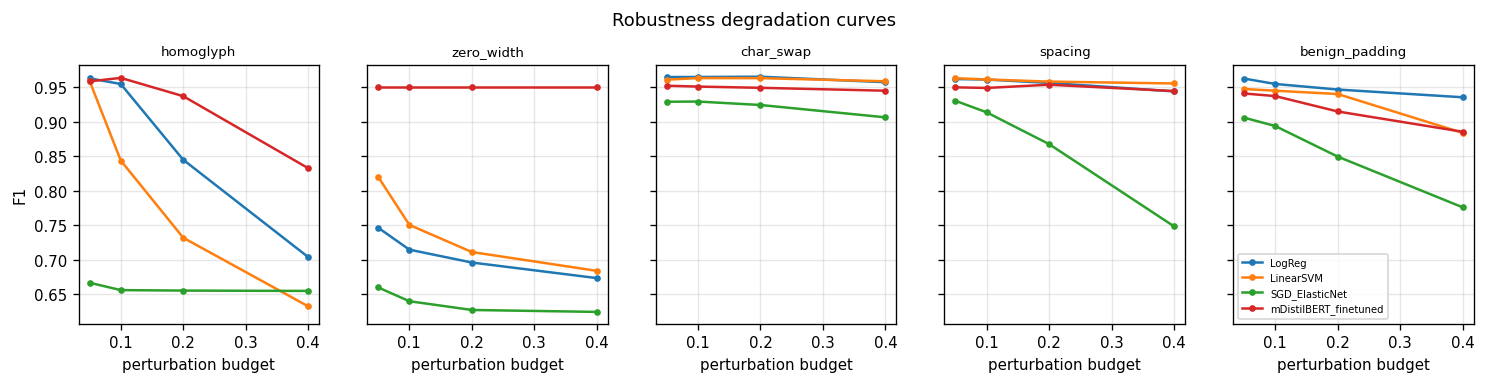

In [45]:
stamp("robustness curves")
T35 = (T34.sort_values("eps").groupby(["model", "attack"])["F1"]
         .apply(lambda s: float(np.trapezoid(s.values, CFG["EPS_GRID"])) /
                (CFG["EPS_GRID"][-1] - CFG["EPS_GRID"][0])).rename("AURC_F1").reset_index())
T35["clean_F1"] = T35["model"].map(CLEAN_F1)
T35["degradation_pct"] = (100 * (T35.clean_F1 - T35.AURC_F1) / T35.clean_F1).round(2)
register("robustness_aurc", T35.round(4))
display(T35.round(4))

fig, axes = plt.subplots(1, len(ATTACKS), figsize=(3 * len(ATTACKS), 2.8), sharey=True)
for ax, atk in zip(np.atleast_1d(axes), ATTACKS):
    for k in ADV_MODELS:
        d = T34[(T34.attack == atk) & (T34.model == k)].sort_values("eps")
        ax.plot(d.eps, d.F1, "o-", label=k, ms=3)
    ax.set_title(atk, fontsize=8); ax.set_xlabel("perturbation budget")
np.atleast_1d(axes)[0].set_ylabel("F1")
np.atleast_1d(axes)[-1].legend(fontsize=6)
plt.suptitle("Robustness degradation curves", y=1.04)
savefig("robustness_curves")

### 36. Normalisation-hardened inference defence

**Closes:** Deploys the normaliser from item 15 at inference time and measures recovery. Shows precisely which attack families are neutralised and which remain open.

In [46]:
stamp("normalisation defence")
eps_max = CFG["EPS_GRID"][-1]
rows = []
for atk in ATTACKS:
    pert = apply_attack(adv_texts, atk, eps_max)
    deft = [homoglyph_normalize(t) for t in pert]
    for k in ADV_MODELS:
        rows.append({"model": k, "attack": atk, "eps": eps_max,
                     "clean_F1": CLEAN_F1[k],
                     "attacked_F1": f1_score(y_adv, predict_texts(k, pert) >= .5),
                     "defended_F1": f1_score(y_adv, predict_texts(k, deft) >= .5)})
    del pert, deft
    gc.collect()

T36 = pd.DataFrame(rows)
T36["recovery_points"] = (100 * (T36.defended_F1 - T36.attacked_F1)).round(2)
T36["residual_gap"] = (100 * (T36.clean_F1 - T36.defended_F1)).round(2)
register("normalisation_defence", T36.round(4))
display(T36.round(4))
print("\nMean recovery by attack family:")
display(T36.groupby("attack")["recovery_points"].mean().round(2).sort_values(ascending=False))

[ 4774.1s |  7418 MB] normalisation defence


,model,attack,eps,clean_F1,attacked_F1,defended_F1,recovery_points,residual_gap
0,LogReg,homoglyph,0.4,0.9668,0.7041,0.9656,26.15,0.12
1,LinearSVM,homoglyph,0.4,0.9640,0.6327,0.9655,33.28,-0.15
2,SGD_ElasticNet,homoglyph,0.4,0.9321,0.6550,0.9345,27.95,-0.25
3,mDistilBERT_finetuned,homoglyph,0.4,0.9502,0.8329,0.9654,13.26,-1.52
4,LogReg,zero_width,0.4,0.9668,0.6736,0.9657,29.21,0.11
5,LinearSVM,zero_width,0.4,0.9640,0.6841,0.9640,27.99,0.00
6,SGD_ElasticNet,zero_width,0.4,0.9321,0.6246,0.9325,30.79,-0.04
7,mDistilBERT_finetuned,zero_width,0.4,0.9502,0.9502,0.9502,0.00,0.00
8,LogReg,char_swap,0.4,0.9668,0.9575,0.9570,-0.05,0.99
9,LinearSVM,char_swap,0.4,0.9640,0.9589,0.9584,-0.05,0.55



Mean recovery by attack family:


,recovery_points
attack,
homoglyph,25.16
zero_width,22.00
benign_padding,0.04
char_swap,-0.06
spacing,-0.12


### 37. Adversarially augmented training

**Closes:** A second, complementary defence. Reported jointly with clean-set performance so the robustness / accuracy trade-off is explicit rather than hidden.

In [47]:
stamp("adversarial training")
rs = np.random.RandomState(SEED)
tr_texts = train["text"].tolist()
pick = rs.choice(len(tr_texts), min(len(tr_texts), 8000 if not FAST_MODE else 4000), replace=False)
akeys = list(ATTACKS)
aug_txt = [ATTACKS[akeys[rs.randint(len(akeys))]](tr_texts[i][:3000], 0.15, rs) for i in pick]
aug_y = y_tr[pick]

X_aug = sparse.vstack([X_tr, featurize(aug_txt)]).tocsr()
adv_m = LogisticRegression(max_iter=900, C=4.0,
                           class_weight="balanced").fit(X_aug, np.r_[y_tr, aug_y])
del X_aug, aug_txt
gc.collect()

MODELS["LogReg_AdvTrained"] = adv_m
PRED_SPACE["LogReg_AdvTrained"] = "fused"
PRED["LogReg_AdvTrained"] = {"val": adv_m.predict_proba(X_va)[:, 1],
                             "test": adv_m.predict_proba(X_te)[:, 1],
                             "llm": adv_m.predict_proba(X_llm)[:, 1]}
TIMING["LogReg_AdvTrained"] = {"fit_seconds": np.nan, "infer_us_per_doc": np.nan}

rows = []
for atk in ATTACKS:
    Xp = featurize(apply_attack(adv_texts, atk, eps_max))
    rows.append({"condition": atk,
                 "baseline_F1": f1_score(y_adv, MODELS["LogReg"].predict_proba(Xp)[:, 1] >= .5),
                 "adv_trained_F1": f1_score(y_adv, adv_m.predict_proba(Xp)[:, 1] >= .5)})
    del Xp
    gc.collect()
rows.append({"condition": "clean human test",
             "baseline_F1": f1_score(y_te, PRED["LogReg"]["test"] >= .5),
             "adv_trained_F1": f1_score(y_te, PRED["LogReg_AdvTrained"]["test"] >= .5)})
rows.append({"condition": "LLM external",
             "baseline_F1": f1_score(y_llm, PRED["LogReg"]["llm"] >= .5),
             "adv_trained_F1": f1_score(y_llm, PRED["LogReg_AdvTrained"]["llm"] >= .5)})

T37 = pd.DataFrame(rows)
T37["delta"] = (T37.adv_trained_F1 - T37.baseline_F1).round(4)
register("adversarial_training", T37.round(4))
display(T37.round(4))

[ 5168.7s |  7418 MB] adversarial training


,condition,baseline_F1,adv_trained_F1,delta
0,homoglyph,0.7041,0.9484,0.2443
1,zero_width,0.6736,0.8822,0.2086
2,char_swap,0.9575,0.9622,0.0047
3,spacing,0.9442,0.9517,0.0075
4,benign_padding,0.9357,0.9471,0.0114
5,clean human test,0.9681,0.9677,-0.0003
6,LLM external,0.6964,0.6979,0.0015


### 37b. Complete results for every detector (Tables 3 and 5)

**Revision (R1-17, R2).** One table per distribution covering **all** detectors trained in this notebook
(the paper's main tables previously listed 12 and 11). Columns include MCC, so negative values are visible,
and 95% bootstrap intervals for F1. The generated-set table also reports the group-disjoint adaptation
**hold-out**, the only clean comparison for the importance-weighted model. The unattributed generated
source is scored separately, with labels as given and flipped, so its effect on the earlier headline is
documented rather than hidden.


[ 5443.5s |  7418 MB] consolidated results for all detectors
15 detectors: LogReg, LinearSVM, ComplementNB, SGD_ElasticNet, RandomForest, HistGB, LogReg_ShortcutSuppressed, LogReg_ImportanceWeighted, StackedEnsemble, SoftVoteEnsemble, LSTM, BiLSTM, Hybrid_LSTM_BiLSTM, mDistilBERT_finetuned, LogReg_AdvTrained


,Model,F1,F1_ci_low,F1_ci_high,AUC,MCC,FPR,FNR
0,LogReg,0.9681,0.9618,0.9735,0.9941,0.9407,0.0266,0.0328
14,LogReg_AdvTrained,0.9677,0.9619,0.9735,0.9942,0.9402,0.0256,0.0345
8,StackedEnsemble,0.9659,0.9594,0.9716,0.9948,0.9369,0.0246,0.0392
9,SoftVoteEnsemble,0.9643,0.9577,0.9704,0.9942,0.9343,0.0226,0.0445
1,LinearSVM,0.9641,0.9574,0.9699,0.9922,0.9328,0.0392,0.0269
11,BiLSTM,0.9636,0.9573,0.9699,0.9928,0.9326,0.0276,0.0404
6,LogReg_ShortcutSuppressed,0.9581,0.9510,0.9648,0.9914,0.9228,0.0281,0.0503
13,mDistilBERT_finetuned,0.9541,0.9469,0.9612,0.9935,0.9175,0.0176,0.0690
10,LSTM,0.9530,0.9455,0.9599,0.9904,0.9125,0.0422,0.0451
7,LogReg_ImportanceWeighted,0.9453,0.9375,0.9531,0.9860,0.8995,0.0377,0.0644


,Model,human_F1,llm_F1,llm_F1_ci_low,llm_F1_ci_high,llm_AUC,llm_MCC,GGI_F1,GGI_AUC,holdout_F1,holdout_AUC
12,Hybrid_LSTM_BiLSTM,0.9362,0.7093,0.6890,0.7281,0.7990,0.3641,0.2424,0.3886,0.6921,0.7827
2,ComplementNB,0.9240,0.6983,0.6774,0.7195,0.7701,0.3787,0.2443,0.4347,0.6868,0.7583
10,LSTM,0.9530,0.7200,0.6996,0.7399,0.7901,0.4104,0.2445,0.4085,0.6977,0.7668
13,mDistilBERT_finetuned,0.9541,0.7049,0.6851,0.7237,0.7649,0.3886,0.2612,0.4631,0.6806,0.7395
11,BiLSTM,0.9636,0.7118,0.6917,0.7307,0.7587,0.4081,0.2613,0.4751,0.6853,0.7330
4,RandomForest,0.9000,0.6632,0.6437,0.6795,0.7415,0.1193,0.2631,0.4941,0.6468,0.7230
14,LogReg_AdvTrained,0.9677,0.6979,0.6790,0.7173,0.7606,0.3602,0.2788,0.4727,0.6730,0.7336
7,LogReg_ImportanceWeighted,0.9453,0.6805,0.6619,0.6990,0.7707,0.2441,0.2801,0.4429,0.6676,0.7456
0,LogReg,0.9681,0.6964,0.6772,0.7167,0.7589,0.3529,0.2806,0.4761,0.6766,0.7335
6,LogReg_ShortcutSuppressed,0.9581,0.6769,0.6574,0.6958,0.7320,0.3026,0.2935,0.5278,0.6486,0.6995


Mean F1 human -> generated: 0.9488 -> 0.6861 | detectors with negative MCC on generated: none


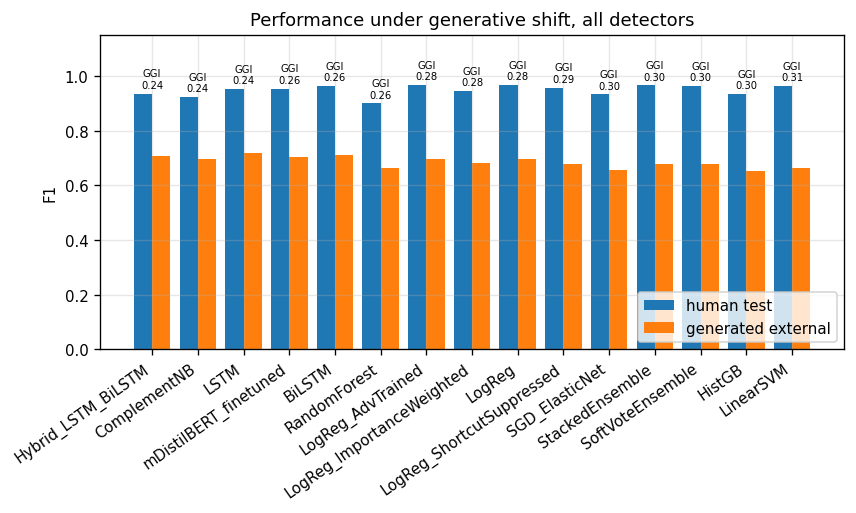

,Model,n,F1,MCC,AUC_labels_as_given,AUC_labels_flipped
0,LogReg,1161,0.0626,-0.7151,0.1344,0.8656
1,LinearSVM,1161,0.0826,-0.4921,0.1674,0.8326
2,ComplementNB,1161,0.0826,-0.6601,0.1812,0.8188
3,SGD_ElasticNet,1161,0.0667,-0.6733,0.1436,0.8564
4,RandomForest,1161,0.0160,-0.8319,0.0148,0.9852
5,HistGB,1161,0.0877,-0.6413,0.0752,0.9248
6,LogReg_ShortcutSuppressed,1161,0.0671,-0.6543,0.1494,0.8506
7,LogReg_ImportanceWeighted,1161,0.0674,-0.7975,0.1930,0.8070
8,StackedEnsemble,1161,0.0666,-0.7515,0.0975,0.9025
9,SoftVoteEnsemble,1161,0.0667,-0.7484,0.0791,0.9209


Mean AUC as given 0.108 vs flipped 0.892


,Model,llm_F1_headline,llm_F1_old_pooled,llm_AUC_headline,llm_AUC_old_pooled
0,LogReg,0.6964,0.5075,0.7589,0.5428
1,LinearSVM,0.6648,0.5093,0.7187,0.5610
2,ComplementNB,0.6983,0.5077,0.7701,0.5814
3,SGD_ElasticNet,0.6574,0.4905,0.6124,0.4951
4,RandomForest,0.6632,0.5108,0.7415,0.6854
5,HistGB,0.6542,0.5151,0.6738,0.5744
6,LogReg_ShortcutSuppressed,0.6769,0.4990,0.7320,0.5345
7,LogReg_ImportanceWeighted,0.6805,0.5139,0.7707,0.5640
8,StackedEnsemble,0.6785,0.5089,0.7676,0.5689
9,SoftVoteEnsemble,0.6771,0.5108,0.7666,0.5806


In [48]:
stamp("consolidated results for all detectors")
ALL_MODELS = list(PRED)
print("%d detectors: %s" % (len(ALL_MODELS), ", ".join(ALL_MODELS)))

rows = []
for k in ALL_MODELS:
    e = evaluate(y_te, PRED[k]["test"])
    lo, hi = boot_ci(f1_m, y_te, PRED[k]["test"])
    rows.append({"Model": k, "F1": e["F1"], "F1_ci_low": lo, "F1_ci_high": hi, "AUC": e["AUC"],
                 "MCC": e["MCC"], "FPR": e["FPR"], "FNR": e["FNR"]})
TABLE3 = register("TABLE3_human_test_all_detectors", pd.DataFrame(rows).round(4).sort_values("F1", ascending=False))
display(TABLE3)

yh_ = y_llm[LLM_HOLD]
rows = []
for k in ALL_MODELS:
    h, g = evaluate(y_te, PRED[k]["test"]), evaluate(y_llm, PRED[k]["llm"])
    lo, hi = boot_ci(f1_m, y_llm, PRED[k]["llm"])
    rows.append({"Model": k, "human_F1": h["F1"], "llm_F1": g["F1"], "llm_F1_ci_low": lo, "llm_F1_ci_high": hi,
                 "llm_AUC": g["AUC"], "llm_MCC": g["MCC"],
                 "GGI_F1": (h["F1"] - g["F1"]) / max(h["F1"], 1e-9),
                 "GGI_AUC": (h["AUC"] - g["AUC"]) / max(h["AUC"] - 0.5, 1e-9),
                 "holdout_F1": f1_score(yh_, PRED[k]["llm"][LLM_HOLD] >= .5),
                 "holdout_AUC": roc_auc_score(yh_, PRED[k]["llm"][LLM_HOLD])})
TABLE5 = register("TABLE5_generative_shift_all_detectors", pd.DataFrame(rows).round(4).sort_values("GGI_F1"))
display(TABLE5)
print("Mean F1 human -> generated: %.4f -> %.4f | detectors with negative MCC on generated: %s"
      % (TABLE5.human_F1.mean(), TABLE5.llm_F1.mean(),
         ", ".join(TABLE5.loc[TABLE5.llm_MCC < 0, "Model"]) or "none"))

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(TABLE5))
ax.bar(x - .2, TABLE5.human_F1, .4, label="human test")
ax.bar(x + .2, TABLE5.llm_F1, .4, label="generated external")
for i, g in enumerate(TABLE5.GGI_F1):
    ax.text(i, TABLE5.human_F1.iloc[i] + .02, "GGI\n%.2f" % g, ha="center", fontsize=6)
ax.set_xticks(x); ax.set_xticklabels(TABLE5.Model, rotation=35, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1.15); ax.legend(loc="lower right")
ax.set_title("Performance under generative shift, all detectors")
savefig("generalization_gap_all")


# ---- unattributed source, scored separately --------------------------------------------
def predict_any(k, texts, base_preds):
    sp = PRED_SPACE.get(k)
    if sp == "fused":
        return MODELS[k].predict_proba(_prep(k, featurize(texts)))[:, 1]
    if sp == "structural":
        return MODELS[k].predict_proba(build_struct_matrix(texts))[:, 1]
    if sp == "suppressed":
        Xs_ = sparse.hstack([word_vec.transform(texts)[:, KEEP], char_vec.transform(texts),
                             sparse.csr_matrix(FEATURE_SCALER.transform(build_struct_matrix(texts)))]).tocsr()
        return MODELS[k].predict_proba(Xs_)[:, 1]
    if sp == "sequence":
        q = pad_sequences(tok.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")
        return MODELS[k].predict(q, verbose=0).ravel()
    if sp == "transformer":
        return TEXT_PREDICTORS[k](texts)
    if sp == "meta":
        Z = np.column_stack([base_preds[b] for b in BASE])
        return meta.predict_proba(Z)[:, 1] if k == "StackedEnsemble" else Z.mean(axis=1)
    raise KeyError(k)


if len(unattr) and unattr["y"].nunique() == 2:
    un_texts = unattr["text"].tolist()
    P_UN = {}
    for k in BASE + [k for k in ALL_MODELS if k not in BASE]:
        P_UN[k] = predict_any(k, un_texts, P_UN)
    rows = [{"Model": k, "n": len(unattr), "F1": f1_score(y_un, P_UN[k] >= .5),
             "MCC": matthews_corrcoef(y_un, P_UN[k] >= .5),
             "AUC_labels_as_given": roc_auc_score(y_un, P_UN[k]),
             "AUC_labels_flipped": roc_auc_score(1 - y_un, P_UN[k])} for k in ALL_MODELS]
    T37u = register("unattributed_source_diagnostic", pd.DataFrame(rows).round(4))
    display(T37u)
    print("Mean AUC as given %.3f vs flipped %.3f" % (T37u.AUC_labels_as_given.mean(), T37u.AUC_labels_flipped.mean()))
    y_pool_old = np.r_[y_llm, y_un]
    rows = [{"Model": k, "llm_F1_headline": f1_score(y_llm, PRED[k]["llm"] >= .5),
             "llm_F1_old_pooled": f1_score(y_pool_old, np.r_[PRED[k]["llm"], P_UN[k]] >= .5),
             "llm_AUC_headline": roc_auc_score(y_llm, PRED[k]["llm"]),
             "llm_AUC_old_pooled": roc_auc_score(y_pool_old, np.r_[PRED[k]["llm"], P_UN[k]])}
            for k in ALL_MODELS]
    T37p = register("effect_of_excluding_unattributed", pd.DataFrame(rows).round(4))
    display(T37p)


### 38. Attack transferability matrix

**Closes:** Establishes whether a single perturbation strategy defeats every detector, which determines whether ensembling is a viable defence. Not examined in any reviewed work.

[ 5552.2s |  7418 MB] transferability


,LinearSVM,LogReg,SGD_ElasticNet,mDistilBERT_finetuned,universality
attack,,,,,
benign_padding,3.59,1.73,8.11,3.19,1.73
char_swap,0.23,0.37,1.03,0.07,0.07
homoglyph,17.83,10.34,29.36,2.84,2.84
spacing,0.44,1.11,7.17,0.07,0.07
zero_width,23.06,26.79,31.54,-0.00,-0.00


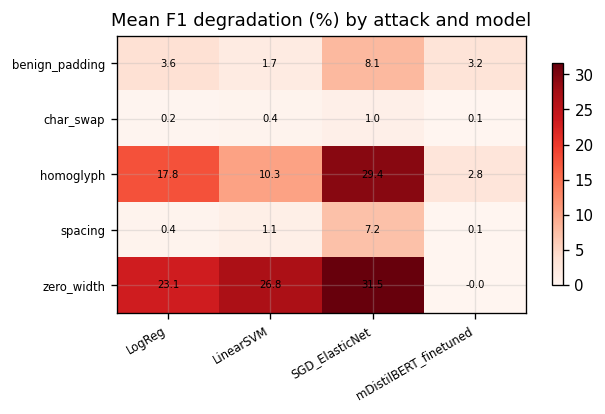

In [49]:
stamp("transferability")
piv = T34.pivot_table(index="attack", columns="model", values="F1", aggfunc="mean")
T38 = (100 * (pd.Series(CLEAN_F1) - piv) / pd.Series(CLEAN_F1)).round(2)
T38["universality"] = T38.min(axis=1).round(2)
register("attack_transferability", T38)
display(T38)

fig, ax = plt.subplots(figsize=(5.5, 3))
im = ax.imshow(T38.drop(columns="universality").values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(ADV_MODELS))); ax.set_xticklabels(ADV_MODELS, rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(T38))); ax.set_yticklabels(T38.index, fontsize=7)
for i in range(T38.shape[0]):
    for j in range(len(ADV_MODELS)):
        ax.text(j, i, "%.1f" % T38.iloc[i, j], ha="center", va="center", fontsize=6)
ax.set_title("Mean F1 degradation (%) by attack and model")
plt.colorbar(im, ax=ax, shrink=.8)
savefig("transferability")

## Part VI: Calibration, Cost and Deployment Operating Points (39–43)

### 39. Calibration assessment under shift

**Closes:** Not one of the 18 reviewed papers reports calibration. A filter whose scores are miscalibrated cannot be given a meaningful quarantine threshold regardless of its AUC.

[ 5552.9s |  7418 MB] calibration


,Model,human_ECE,human_Brier,llm_ECE,llm_Brier,ECE_inflation
8,StackedEnsemble,0.0093,0.0239,0.2683,0.2935,0.2591
11,BiLSTM,0.0132,0.0269,0.2470,0.2683,0.2338
5,HistGB,0.0160,0.0480,0.3934,0.4011,0.3774
14,LogReg_AdvTrained,0.0168,0.0240,0.1445,0.2214,0.1277
10,LSTM,0.0198,0.0340,0.2513,0.2697,0.2315
0,LogReg,0.0221,0.0248,0.1388,0.2202,0.1168
12,Hybrid_LSTM_BiLSTM,0.0230,0.0412,0.2415,0.2596,0.2185
6,LogReg_ShortcutSuppressed,0.0288,0.0307,0.1538,0.2381,0.1250
3,SGD_ElasticNet,0.0300,0.0608,0.2880,0.3928,0.2580
13,mDistilBERT_finetuned,0.0362,0.0387,0.2757,0.2841,0.2395


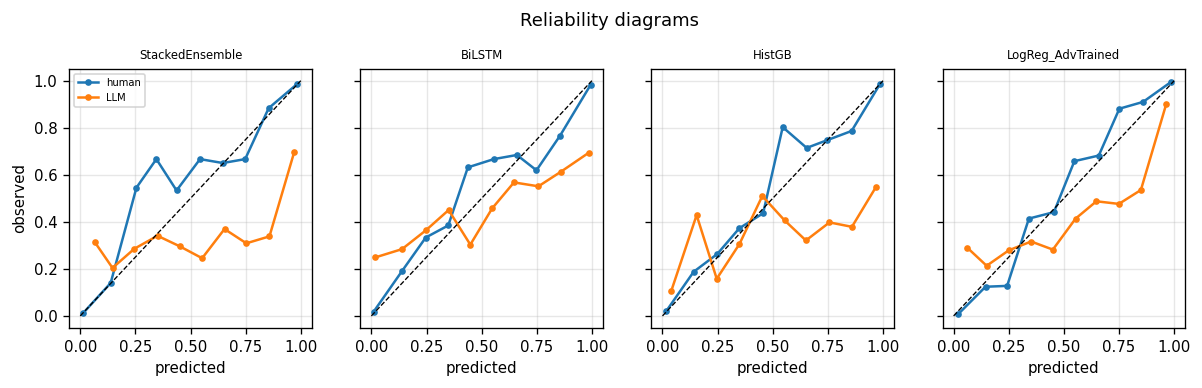

In [50]:
stamp("calibration")

def ece(y, p, bins=15):
    e, n = 0.0, len(y)
    edges = np.linspace(0, 1, bins + 1)
    for i in range(bins):
        m = (p > edges[i]) & (p <= edges[i + 1])
        if m.sum():
            e += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return e


T39 = register("calibration", pd.DataFrame(
    [{"Model": k, "human_ECE": ece(y_te, v["test"]), "human_Brier": brier_score_loss(y_te, v["test"]),
      "llm_ECE": ece(y_llm, v["llm"]), "llm_Brier": brier_score_loss(y_llm, v["llm"]),
      "ECE_inflation": ece(y_llm, v["llm"]) - ece(y_te, v["test"])}
     for k, v in PRED.items()]).round(4).sort_values("human_ECE"))
display(T39)

top = T39.Model.head(4).tolist()
fig, axes = plt.subplots(1, len(top), figsize=(3 * len(top), 2.8), sharey=True)
for ax, k in zip(np.atleast_1d(axes), top):
    for lbl, y_, p_ in [("human", y_te, PRED[k]["test"]), ("LLM", y_llm, PRED[k]["llm"])]:
        bs = np.linspace(0, 1, 11)
        xs, ys = [], []
        for i in range(10):
            m = (p_ > bs[i]) & (p_ <= bs[i + 1])
            if m.sum() > 5:
                xs.append(p_[m].mean()); ys.append(y_[m].mean())
        ax.plot(xs, ys, "o-", ms=3, label=lbl)
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    ax.set_title(k, fontsize=7); ax.set_xlabel("predicted")
np.atleast_1d(axes)[0].set_ylabel("observed"); np.atleast_1d(axes)[0].legend(fontsize=6)
plt.suptitle("Reliability diagrams", y=1.05)
savefig("reliability")

### 40. Post-hoc recalibration and its limits under shift

**Closes:** Tests whether standard isotonic recalibration fitted on in-distribution validation data transfers to the shifted distribution. A negative result here is itself a finding worth reporting.

In [51]:
stamp("recalibration")
rows = []
for k, v in PRED.items():
    iso = IsotonicRegression(out_of_bounds="clip").fit(v["val"], y_va)
    rows.append({"Model": k,
                 "human_ECE_before": ece(y_te, v["test"]),
                 "human_ECE_after": ece(y_te, iso.predict(v["test"])),
                 "llm_ECE_before": ece(y_llm, v["llm"]),
                 "llm_ECE_after": ece(y_llm, iso.predict(v["llm"]))})
T40 = pd.DataFrame(rows)
T40["human_improved"] = T40.human_ECE_after < T40.human_ECE_before
T40["llm_improved"] = T40.llm_ECE_after < T40.llm_ECE_before
register("recalibration", T40.round(4))
display(T40.round(4))
print("In-distribution recalibration succeeds for %d/%d models but transfers to the shifted "
      "distribution for only %d/%d." % (T40.human_improved.sum(), len(T40),
                                        T40.llm_improved.sum(), len(T40)))

[ 5554.4s |  7418 MB] recalibration


,Model,human_ECE_before,human_ECE_after,llm_ECE_before,llm_ECE_after,human_improved,llm_improved
0,LogReg,0.0221,0.0059,0.1388,0.1963,True,False
1,LinearSVM,0.1593,0.0058,0.1395,0.2684,True,False
2,ComplementNB,0.0480,0.0170,0.2365,0.2632,True,False
3,SGD_ElasticNet,0.0300,0.0169,0.2880,0.3494,True,False
4,RandomForest,0.0702,0.0319,0.3458,0.4516,True,False
5,HistGB,0.0160,0.0224,0.3934,0.4082,False,False
6,LogReg_ShortcutSuppressed,0.0288,0.0092,0.1538,0.2302,True,False
7,LogReg_ImportanceWeighted,0.0491,0.0133,0.2109,0.3013,True,False
8,StackedEnsemble,0.0093,0.0081,0.2683,0.2793,True,False
9,SoftVoteEnsemble,0.0677,0.0087,0.2106,0.3110,True,False


In-distribution recalibration succeeds for 14/15 models but transfers to the shifted distribution for only 4/15.


### 41. Cost-sensitive operating-point selection

**Closes:** Every reviewed paper optimises F1 at a fixed 0.5 threshold. In deployment a missed phish costs far more than a quarantined legitimate message; the optimal threshold is nowhere near 0.5.

**Revision.** The threshold is now chosen on the **validation** split and applied to the test split, so
the reported cost reduction is not tuned on test. The test-optimal (oracle) threshold is shown for reference
only.


In [52]:
stamp("cost-sensitive thresholds (selected on validation)")
GRID = np.linspace(0.02, 0.98, 97)


def cost_at(y, p, th):
    tn, fp, fn, tp = confusion_matrix(y, (p >= th).astype(int), labels=[0, 1]).ravel()
    return CFG["COST_FN"] * fn + CFG["COST_FP"] * fp


rows = []
for k, v in PRED.items():
    th_val = GRID[int(np.argmin([cost_at(y_va, v["val"], t) for t in GRID]))]
    test_costs = np.array([cost_at(y_te, v["test"], t) for t in GRID])
    c05 = cost_at(y_te, v["test"], 0.5)
    c_val = cost_at(y_te, v["test"], th_val)
    rows.append({"Model": k, "cost_at_0.5": c05, "threshold_from_val": round(th_val, 3),
                 "test_cost_at_val_threshold": c_val,
                 "cost_reduction_pct": round(100 * (1 - c_val / max(c05, 1)), 2),
                 "oracle_test_threshold": round(GRID[int(test_costs.argmin())], 3),
                 "oracle_test_cost": test_costs.min()})
T41 = register("cost_sensitive", pd.DataFrame(rows).round(3).sort_values("test_cost_at_val_threshold"))
display(T41)
print("Cost model: FN = %.0f x FP. Thresholds chosen on validation; oracle columns are for reference only."
      % (CFG["COST_FN"] / CFG["COST_FP"]))


[ 5554.6s |  7418 MB] cost-sensitive thresholds (selected on validation)


,Model,cost_at_0.5,threshold_from_val,test_cost_at_val_threshold,cost_reduction_pct,oracle_test_threshold,oracle_test_cost
8,StackedEnsemble,719.0,0.05,320.0,55.49,0.06,318.0
9,SoftVoteEnsemble,805.0,0.22,351.0,56.40,0.20,338.0
1,LinearSVM,538.0,0.35,363.0,32.53,0.39,341.0
14,LogReg_AdvTrained,641.0,0.18,384.0,40.09,0.10,344.0
0,LogReg,613.0,0.24,397.0,35.24,0.14,351.0
11,BiLSTM,745.0,0.04,462.0,37.99,0.06,439.0
6,LogReg_ShortcutSuppressed,916.0,0.20,481.0,47.49,0.12,433.0
10,LSTM,854.0,0.07,508.0,40.52,0.07,508.0
12,Hybrid_LSTM_BiLSTM,1527.0,0.18,523.0,65.75,0.10,429.0
5,HistGB,1356.0,0.07,644.0,52.51,0.07,644.0


Cost model: FN = 10 x FP. Thresholds chosen on validation; oracle columns are for reference only.


### 42. Precision and recall at fixed false-positive budgets

**Closes:** Enterprise mail filters operate at FPR budgets of 1% or below. Headline F1 at a balanced threshold says nothing about behaviour in that regime.

**Revision.** The score threshold for each FPR budget is set on the **validation** split; precision,
recall and the *realised* FPR are then measured on test.


In [53]:
stamp("fixed-FPR operating points (thresholds from validation)")


def thr_for_fpr(y, p, target):
    neg = np.sort(p[y == 0])[::-1]
    if len(neg) == 0:
        return 0.5
    k = int(np.floor(target * len(neg)))
    return neg[k] + 1e-12 if k < len(neg) else neg[-1]


rows = []
for k, v in PRED.items():
    r = {"Model": k}
    for tgt in [0.001, 0.01, 0.05]:
        th = thr_for_fpr(y_va, v["val"], tgt)
        yh = (v["test"] >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, yh, labels=[0, 1]).ravel()
        tag = "%.1f%%" % (100 * tgt)
        r["P@FPR=" + tag] = precision_score(y_te, yh, zero_division=0)
        r["R@FPR=" + tag] = recall_score(y_te, yh, zero_division=0)
        r["realised_FPR@" + tag] = fp / max(fp + tn, 1)
    rows.append(r)
T42 = register("fixed_fpr", pd.DataFrame(rows).round(4))
display(T42)


[ 5557.3s |  7418 MB] fixed-FPR operating points (thresholds from validation)


,Model,P@FPR=0.1%,R@FPR=0.1%,realised_FPR@0.1%,P@FPR=1.0%,R@FPR=1.0%,realised_FPR@1.0%,P@FPR=5.0%,R@FPR=5.0%,realised_FPR@5.0%
0,LogReg,0.9938,0.1861,0.0010,0.9914,0.8765,0.0065,0.9527,0.9789,0.0417
1,LinearSVM,0.9873,0.0907,0.0010,0.9920,0.7297,0.0050,0.9531,0.9743,0.0412
2,ComplementNB,0.9947,0.5442,0.0025,0.9853,0.7466,0.0095,0.9514,0.9157,0.0402
3,SGD_ElasticNet,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,RandomForest,1.0000,0.3218,0.0000,0.9829,0.7045,0.0105,0.9374,0.8590,0.0492
5,HistGB,0.9971,0.5968,0.0015,0.9910,0.7127,0.0055,0.9450,0.8947,0.0447
6,LogReg_ShortcutSuppressed,0.9710,0.0392,0.0010,0.9912,0.7923,0.0060,0.9507,0.9696,0.0432
7,LogReg_ImportanceWeighted,0.9841,0.1088,0.0015,0.9873,0.7291,0.0080,0.9552,0.9356,0.0377
8,StackedEnsemble,1.0000,0.4874,0.0000,0.9927,0.7934,0.0050,0.9529,0.9836,0.0417
9,SoftVoteEnsemble,1.0000,0.4939,0.0000,0.9883,0.7917,0.0080,0.9521,0.9778,0.0422


### 43. Selective prediction and human-in-the-loop triage

**Closes:** Given the collapse quantified in item 28, a deployable system must abstain rather than guess. Risk-coverage curves quantify how much analyst effort buys how much error reduction. Models whose shifted-set predictions are degenerate are flagged, since a constant predictor attains deceptively low selective risk on an imbalanced set.

[ 5557.6s |  7418 MB] selective prediction
Ranked over non-degenerate predictors only:


,Model,risk@cov=20%,risk@cov=40%,risk@cov=60%,risk@cov=80%,risk@cov=100%,AURC,llm_recall,degenerate
12,Hybrid_LSTM_BiLSTM,0.042,0.119,0.1993,0.2865,0.3292,0.1581,0.8230,False
11,BiLSTM,0.084,0.191,0.2627,0.2745,0.2980,0.1838,0.7541,False
2,ComplementNB,0.112,0.188,0.2447,0.2800,0.3128,0.1850,0.7418,False
10,LSTM,0.038,0.216,0.2667,0.2735,0.2996,0.1850,0.7893,False
13,mDistilBERT_finetuned,0.106,0.203,0.2447,0.2730,0.3084,0.1856,0.7549,False
14,LogReg_AdvTrained,0.092,0.198,0.2573,0.2955,0.3248,0.1918,0.7689,False
0,LogReg,0.094,0.202,0.2647,0.3015,0.3292,0.1960,0.7738,False
6,LogReg_ShortcutSuppressed,0.108,0.256,0.3013,0.3220,0.3552,0.2222,0.7623,False
8,StackedEnsemble,0.068,0.233,0.3273,0.3575,0.3928,0.2296,0.8492,False
9,SoftVoteEnsemble,0.064,0.234,0.3453,0.3830,0.4036,0.2392,0.8672,False


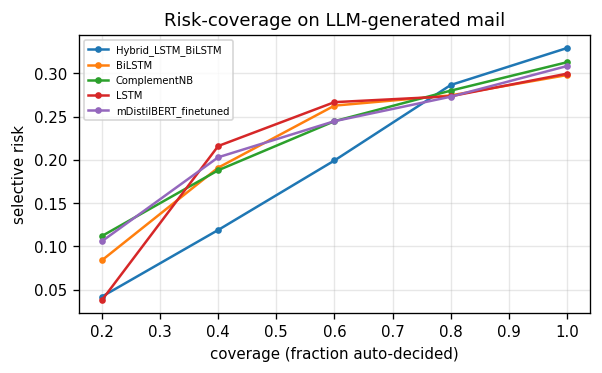

In [54]:
stamp("selective prediction")
COV = [0.2, 0.4, 0.6, 0.8, 1.0]
rows = []
for k, v in PRED.items():
    p = v["llm"]
    yh = (p >= .5).astype(int)
    degenerate = (yh.mean() < 0.02) or (yh.mean() > 0.98) or \
                 (recall_score(y_llm, yh, zero_division=0) < 0.05)
    order = np.argsort(-np.abs(p - 0.5))
    correct = (yh == y_llm).astype(int)[order]
    risk = [1 - correct[:max(int(c * len(order)), 1)].mean() for c in COV]
    rows.append({"Model": k, **{"risk@cov=%.0f%%" % (100 * c): r for c, r in zip(COV, risk)},
                 "AURC": float(np.trapezoid(risk, COV)),
                 "llm_recall": recall_score(y_llm, yh, zero_division=0),
                 "degenerate": bool(degenerate)})

T43 = pd.DataFrame(rows).round(4)
VALID43 = T43[~T43.degenerate].sort_values("AURC")
register("selective_prediction", T43.sort_values("AURC"))
print("Ranked over non-degenerate predictors only:")
display(VALID43)
if T43.degenerate.any():
    print("Excluded as degenerate (constant or near-zero recall under shift):",
          ", ".join(T43.loc[T43.degenerate, "Model"]))

fig, ax = plt.subplots(figsize=(5.5, 3))
for k in VALID43.Model.head(5):
    ax.plot(COV, [VALID43.loc[VALID43.Model == k, "risk@cov=%.0f%%" % (100 * c)].iat[0] for c in COV],
            "o-", ms=3, label=k)
ax.set_xlabel("coverage (fraction auto-decided)"); ax.set_ylabel("selective risk")
ax.set_title("Risk-coverage on LLM-generated mail"); ax.legend(fontsize=6)
savefig("risk_coverage")

## Part VII: Explainability and Cross-Lingual Fairness (44–47)

### 44. Collinearity-robust attribution over the interpretable block

**Closes:** Uddin et al. apply LIME to token weights of an English model. Attribution over 56 language-independent descriptors yields explanations valid across all six languages at once. Logistic coefficients alone are unreliable when descriptors are collinear (character and word length correlate above 0.9 and receive large opposing weights), so permutation importance is reported alongside them as the primary ranking.

[ 5558.1s |  7418 MB] attribution


,feature,perm_importance,perm_std,coefficient,evidence_for
0,has_url,0.21536,0.00535,2.57063,phishing
1,len_chars,0.18820,0.00503,1.84534,phishing
2,max_url_len,0.12521,0.00492,-2.09420,legitimate
3,avg_word_len,0.09430,0.00412,3.04740,phishing
4,whitespace_ratio,0.05085,0.00262,1.08941,phishing
5,second_person_ratio,0.04266,0.00155,0.82793,phishing
6,len_words,0.04083,0.00307,-0.89345,legitimate
7,allcaps_runs,0.03361,0.00196,0.69201,phishing
8,punct_ratio,0.03126,0.00189,-0.78101,legitimate
9,n_urls,0.02698,0.00264,-0.71009,legitimate



Collinear descriptor pairs (|r| > 0.9): [('has_url', 'max_url_len', 0.988), ('len_chars', 'len_words', 0.982), ('len_chars', 'n_sentences', 0.912), ('n_scripts', 'script_mix_flag', 0.999)]
Permutation importance is reported as the primary ranking because it is unaffected by these.


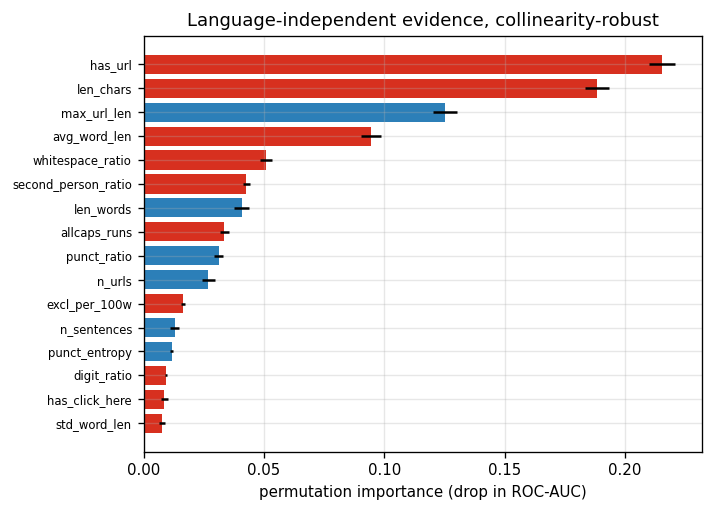

In [55]:
stamp("attribution")
from sklearn.inspection import permutation_importance

lr_struct = LogisticRegression(max_iter=900, C=0.1, class_weight="balanced").fit(Ss_tr, y_tr)
coef = pd.Series(lr_struct.coef_[0], index=FEATURE_NAMES)

Ss_te_d = np.asarray(Ss_te.todense()) if sparse.issparse(Ss_te) else Ss_te
pim = permutation_importance(lr_struct, Ss_te_d, y_te, n_repeats=8,
                             random_state=SEED, scoring="roc_auc", n_jobs=1)

T44 = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "perm_importance": pim.importances_mean,
    "perm_std": pim.importances_std,
    "coefficient": coef.values,
    "evidence_for": np.where(coef.values >= 0, "phishing", "legitimate"),
}).sort_values("perm_importance", ascending=False).reset_index(drop=True)
register("attribution", T44.round(5))
display(T44.head(20).round(5))

corr = np.corrcoef(np.asarray(Ss_tr.todense()).T if sparse.issparse(Ss_tr) else Ss_tr.T)
iu = np.triu_indices(len(FEATURE_NAMES), 1)
hi = [(FEATURE_NAMES[i], FEATURE_NAMES[j], round(float(corr[i, j]), 3))
      for i, j in zip(*iu) if abs(corr[i, j]) > 0.9]
print("\nCollinear descriptor pairs (|r| > 0.9):", hi if hi else "none")
print("Permutation importance is reported as the primary ranking because it is unaffected by these.")

top = T44.head(16)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(range(len(top))[::-1], top.perm_importance,
        xerr=top.perm_std, color=["#d7301f" if e == "phishing" else "#2c7fb8"
                                  for e in top.evidence_for])
ax.set_yticks(range(len(top))[::-1]); ax.set_yticklabels(top.feature, fontsize=7)
ax.set_xlabel("permutation importance (drop in ROC-AUC)")
ax.set_title("Language-independent evidence, collinearity-robust")
savefig("attribution")

### 45. Per-language equalised-performance audit

**Closes:** Aggregate accuracy hides that a multilingual filter may protect English users while failing speakers of low-resource languages. Fairness auditing is absent from the phishing-detection literature.

**Revision (R2).** Language labels come from the stricter identifier (item 8). Every rate carries a 95%
bootstrap interval, and the class counts per language are shown: with fewer than ~100 messages per
language, differences between languages are often within the intervals and should be reported as such.


In [56]:
stamp("per-language fairness (with bootstrap CIs)")
BEST = TABLE3.Model.iat[0] if "TABLE3" in globals() else T_MASTER.Model.iat[0]
tpr_m = lambda y, p: recall_score(y, p >= .5, zero_division=0)
fpr_m = lambda y, p: ((p >= .5) & (y == 0)).sum() / max((y == 0).sum(), 1)
rows = []
for lg, d in test.groupby("lang"):
    if len(d) < 40 or d["y"].nunique() < 2:
        continue
    yy, pp = d["y"].values, PRED[BEST]["test"][d.index.values]
    m = evaluate(yy, pp)
    r = {"language": lg, "n": len(d), "n_phish": int(yy.sum()), "n_legit": int((1 - yy).sum()),
         "TPR": m["REC"], "FPR": m["FPR"], "F1": m["F1"], "AUC": m["AUC"], "corpora": d["source"].nunique()}
    for nm, fn_ in [("TPR", tpr_m), ("FPR", fpr_m), ("F1", f1_m)]:
        r[nm + "_ci"] = "[%.3f, %.3f]" % boot_ci(fn_, yy, pp)
    rows.append(r)
T45 = pd.DataFrame(rows).round(4)
if len(T45) > 1:
    gap = {c: (round(T45[c].max() - T45[c].min(), 4) if c in ("TPR", "FPR", "F1", "AUC") else np.nan)
           for c in T45.columns}
    gap["language"] = "DISPARITY (max-min)"
    T45 = pd.concat([T45, pd.DataFrame([gap])], ignore_index=True)
register("language_fairness", T45)
print("Audited model:", BEST)
display(T45)
single = T45[(T45.corpora == 1) & T45.language.ne("DISPARITY (max-min)")]
if len(single):
    print("\nCaution: %s drawn from a single corpus, so scores are partly" % ", ".join(single.language))
    print("attributable to corpus fingerprinting rather than language competence.")


[ 5560.3s |  7418 MB] per-language fairness (with bootstrap CIs)
Audited model: LogReg


,language,n,n_phish,n_legit,TPR,FPR,F1,AUC,corpora,TPR_ci,FPR_ci,F1_ci
0,Bangla,188.0,102.0,86.0,0.9902,0.0581,0.9712,0.9968,1.0,"[0.968, 1.000]","[0.012, 0.116]","[0.943, 0.991]"
1,English,2884.0,1471.0,1413.0,0.9810,0.0304,0.9760,0.9955,7.0,"[0.974, 0.988]","[0.022, 0.040]","[0.970, 0.981]"
2,French,202.0,50.0,152.0,0.8600,0.0132,0.9053,0.9797,7.0,"[0.765, 0.951]","[0.000, 0.035]","[0.840, 0.961]"
3,German,155.0,31.0,124.0,0.8065,0.0000,0.8929,0.9977,3.0,"[0.658, 0.935]","[0.000, 0.000]","[0.794, 0.967]"
4,Hindi,246.0,35.0,211.0,0.6571,0.0142,0.7541,0.9332,1.0,"[0.500, 0.812]","[0.000, 0.033]","[0.612, 0.857]"
5,DISPARITY (max-min),NaN,NaN,NaN,0.3331,0.0581,0.2219,0.0645,NaN,NaN,NaN,NaN



Caution: Bangla, Hindi drawn from a single corpus, so scores are partly
attributable to corpus fingerprinting rather than language competence.


### 46. Automatic bidirectional error taxonomy

**Closes:** Reviewed papers report confusion matrices but never characterise what they miss. Melendez et al. observe that formal business email is misclassified as phishing but do not quantify or categorise it. Clustering both false negatives and false positives turns the error rate into an actionable failure taxonomy.

In [57]:
stamp("error taxonomy")


def taxonomy(mask, frame, Xmat, kind):
    if mask.sum() < 20:
        return pd.DataFrame()
    Xs = Xmat[mask]
    Z = TruncatedSVD(n_components=min(20, Xs.shape[0] - 1), random_state=SEED).fit_transform(Xs)
    k = int(min(5, max(2, mask.sum() // 25)))
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    f = frame[mask].copy()
    f["cluster"] = lab
    out = f.groupby("cluster").agg(
        n=("text", "size"),
        mean_chars=("text", lambda x: round(x.str.len().mean(), 1)),
        dominant_language=("lang", lambda x: x.mode().iat[0]),
        dominant_source=("source", lambda x: x.mode().iat[0]),
        exemplar=("text", lambda x: x.iloc[0][:90])).reset_index()
    out.insert(0, "error_type", kind)
    return out


fn_llm = (PRED[BEST]["llm"] < .5) & (y_llm == 1)
fp_hum = (PRED[BEST]["test"] >= .5) & (y_te == 0)
print("false negatives on LLM external: %d of %d phishing (%.1f%%)"
      % (fn_llm.sum(), y_llm.sum(), 100 * fn_llm.sum() / max(y_llm.sum(), 1)))
print("false positives on human test:   %d of %d legitimate (%.1f%%)"
      % (fp_hum.sum(), (1 - y_te).sum(), 100 * fp_hum.sum() / max((1 - y_te).sum(), 1)))

T46 = pd.concat([taxonomy(fn_llm, llm, X_llm, "false negative (LLM)"),
                 taxonomy(fp_hum, test, X_te, "false positive (human)")], ignore_index=True)
if len(T46):
    register("error_taxonomy", T46)
    display(T46)
    print("\nFalse-positive clusters test the observation of Melendez et al. that formal,")
    print("transactional business email is the dominant legitimate-side failure mode.")

[ 5581.6s |  7418 MB] error taxonomy
false negatives on LLM external: 276 of 1220 phishing (22.6%)
false positives on human test:   53 of 1992 legitimate (2.7%)


,error_type,cluster,n,mean_chars,dominant_language,dominant_source,exemplar
0,false negative (LLM),0,51,467.6,German,E-PhishLLM,Neue Erkenntnisse in der antioxidativen Forsch...
1,false negative (LLM),1,74,500.4,English,E-PhishLLM,"Hey Abdul, Check Out the Latest Design Drafts!..."
2,false negative (LLM),2,9,593.1,English,E-PhishLLM,Important: Project Update Document Enclosed Hi...
3,false negative (LLM),3,85,448.5,English,E-PhishLLM,Re: Recap from Last Week’s Imaging Design Meet...
4,false negative (LLM),4,57,500.4,German,E-PhishLLM,Wichtige Systemaktualisierung: Sicherheitssoft...
5,false positive (human),0,52,1630.9,English,CEAS_08,Bugzilla: confirm account creation Bugzilla ha...
6,false positive (human),1,1,17.0,Bangla,BangalaBarta,বন্ধুরা কেমন আছে?



False-positive clusters test the observation of Melendez et al. that formal,
transactional business email is the dominant legitimate-side failure mode.


### 47. Cross-lingual attribution stability

**Closes:** Tests whether the same social-engineering cues drive decisions in every language, or whether the model silently learns a different concept per language. A prerequisite for claiming genuine multilinguality.

In [58]:
stamp("attribution stability")
cols = []
for lg, d in human.groupby("lang"):
    if len(d) < 200 or d["y"].nunique() < 2:
        continue
    Sm = StandardScaler().fit_transform(build_struct_matrix(d["text"].tolist()))
    m = LogisticRegression(max_iter=700, class_weight="balanced").fit(Sm, d["y"])
    cols.append(pd.Series(m.coef_[0], index=FEATURE_NAMES, name=lg))

if len(cols) >= 2:
    W = pd.concat(cols, axis=1)
    T47 = register("attribution_stability", W.corr(method="spearman").round(3))
    display(T47)
    stable = W.abs().mean(axis=1).sort_values(ascending=False).head(12).round(3)
    register("universal_cues", stable.rename("mean_abs_weight").to_frame())
    print("\nMost universal phishing cues across languages:")
    display(stable.rename("mean_abs_weight").to_frame())
    iu = np.triu_indices(len(T47), 1)
    print("Mean pairwise cross-language attribution agreement: %.3f" % T47.values[iu].mean())
else:
    T47 = pd.DataFrame()
    print("insufficient per-language data at this CAP_PER_FILE setting")

[ 5585.3s |  7418 MB] attribution stability


,Bangla,English,French,German,Hindi
Bangla,1.000,0.034,0.227,0.236,0.039
English,0.034,1.000,0.000,0.269,-0.108
French,0.227,0.000,1.000,0.090,0.150
German,0.236,0.269,0.090,1.000,0.298
Hindi,0.039,-0.108,0.150,0.298,1.000



Most universal phishing cues across languages:


,mean_abs_weight
len_chars,3.013
len_words,2.576
digit_ratio,1.405
has_url,1.313
max_url_len,1.112
whitespace_ratio,0.925
punct_ratio,0.871
nonascii_ratio,0.851
n_sentences,0.608
type_token_ratio,0.563


Mean pairwise cross-language attribution agreement: 0.124


## Part VIII: Statistical Rigour, Efficiency and Reproducibility (48–50)

### 48. Multi-seed repetition with confidence intervals

**Closes:** All 18 reviewed works report single-run point estimates.

**Revision.** Repetition now covers all six classical detectors (previously only logistic regression).
Each seed refits the detector on a bootstrap resample of the training split (and reseeds the stochastic
learners). With three seeds the 95% interval uses Student's t with 2 degrees of freedom (t = 4.30), not
1.96. Neural and transformer detectors are single-run; the paper must say so.


In [59]:
stamp("multi-seed confidence intervals")
from scipy.stats import t as student_t
from sklearn.base import clone

SEED_MODELS = {**{k: (mk, X_tr, X_te, X_llm) for k, mk in SPARSE_SPEC.items()},
               **{k: (mk, Sd_tr, Sd_te, Sd_llm) for k, mk in DENSE_SPEC.items()}}
rows = []
for sd in CFG["SEEDS"]:
    bi = np.random.RandomState(sd).choice(len(y_tr), len(y_tr), replace=True)
    for k, (mk, A, B, Cm) in SEED_MODELS.items():
        est = mk()
        if "random_state" in est.get_params():
            est.set_params(random_state=sd)
        m = est.fit(_prep(k, A[bi]), y_tr[bi])
        pt, pl = m.predict_proba(_prep(k, B))[:, 1], m.predict_proba(_prep(k, Cm))[:, 1]
        rows.append({"seed": sd, "Model": k, "human_F1": f1_score(y_te, pt >= .5), "human_AUC": roc_auc_score(y_te, pt),
                     "llm_F1": f1_score(y_llm, pl >= .5), "llm_AUC": roc_auc_score(y_llm, pl)})
        del m
    gc.collect()

R = pd.DataFrame(rows)
tcrit = float(student_t.ppf(0.975, len(CFG["SEEDS"]) - 1))
agg = R.drop(columns="seed").groupby("Model").agg(["mean", "std"])
out = []
for k in agg.index:
    r = {"Model": k}
    for met in ["human_F1", "human_AUC", "llm_F1", "llm_AUC"]:
        mu, sd_ = agg.loc[k, (met, "mean")], agg.loc[k, (met, "std")]
        r[met] = mu
        r[met + "_halfwidth95"] = tcrit * sd_ / np.sqrt(len(CFG["SEEDS"]))
    out.append(r)
T48 = register("confidence_intervals", pd.DataFrame(out).round(4))
display(T48)
print("t critical value (df=%d): %.3f" % (len(CFG["SEEDS"]) - 1, tcrit))


[ 5634.6s |  7418 MB] multi-seed confidence intervals


,Model,human_F1,human_F1_halfwidth95,human_AUC,human_AUC_halfwidth95,llm_F1,llm_F1_halfwidth95,llm_AUC,llm_AUC_halfwidth95
0,ComplementNB,0.9236,0.0037,0.9767,0.0026,0.6896,0.0123,0.7650,0.0139
1,HistGB,0.9324,0.0032,0.9826,0.0005,0.6589,0.0058,0.6909,0.0342
2,LinearSVM,0.9655,0.0036,0.9933,0.0008,0.6884,0.0273,0.7554,0.0258
3,LogReg,0.9618,0.0028,0.9923,0.0010,0.6871,0.0258,0.7563,0.0314
4,RandomForest,0.8964,0.0026,0.9753,0.0024,0.6636,0.0081,0.7412,0.0165
5,SGD_ElasticNet,0.9381,0.0453,0.9450,0.0421,0.6690,0.0415,0.6226,0.0516


t critical value (df=2): 4.303


### 49. Pairwise McNemar tests with Holm-Bonferroni correction

**Closes:** Model rankings in the reviewed literature rest on unadjusted decimal differences. Paired significance testing with family-wise error control determines which rankings are defensible.

In [60]:
stamp("significance testing")
names = list(PRED)
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        A = (PRED[names[i]]["test"] >= .5).astype(int) == y_te
        B = (PRED[names[j]]["test"] >= .5).astype(int) == y_te
        n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
        if n01 + n10 == 0:
            p = 1.0
        else:
            z = max(abs(n01 - n10) - 1, 0) / math.sqrt(n01 + n10)
            p = float(min(1.0, 2 * (1 - norm.cdf(z))))
        pairs.append((names[i], names[j], n01, n10, p))

pv = np.array([x[4] for x in pairs])
adj, running, mtot = np.empty_like(pv), 0.0, len(pv)
for rank, k in enumerate(np.argsort(pv)):
    running = max(running, min(1.0, (mtot - rank) * pv[k]))
    adj[k] = running

T49 = register("mcnemar_holm", pd.DataFrame(
    [{"model_A": a_, "model_B": b_, "A_only_correct": n10, "B_only_correct": n01,
      "p_raw": p, "p_holm": adj[i], "significant_at_0.05": bool(adj[i] < .05)}
     for i, (a_, b_, n01, n10, p) in enumerate(pairs)]).round(6).sort_values("p_holm"))
display(T49.head(20))
print("\n%d of %d pairwise differences remain significant after Holm-Bonferroni correction."
      % (int(T49["significant_at_0.05"].sum()), len(T49)))

[ 6085.1s |  7418 MB] significance testing


,model_A,model_B,A_only_correct,B_only_correct,p_raw,p_holm,significant_at_0.05
1,LogReg,ComplementNB,171,30,0.0,0.0,True
2,LogReg,SGD_ElasticNet,148,31,0.0,0.0,True
3,LogReg,RandomForest,261,39,0.0,0.0,True
4,LogReg,HistGB,166,53,0.0,0.0,True
6,LogReg,LogReg_ImportanceWeighted,86,10,0.0,0.0,True
14,LinearSVM,ComplementNB,181,55,0.0,0.0,True
15,LinearSVM,SGD_ElasticNet,149,47,0.0,0.0,True
11,LogReg,Hybrid_LSTM_BiLSTM,154,50,0.0,0.0,True
24,LinearSVM,Hybrid_LSTM_BiLSTM,150,61,0.0,0.0,True
30,ComplementNB,LogReg_ShortcutSuppressed,51,159,0.0,0.0,True



63 of 105 pairwise differences remain significant after Holm-Bonferroni correction.


### 50. Efficiency profile and complete artifact export

**Closes:** Deployment feasibility is unreported across the reviewed corpus. Every table, figure, manifest and split hash is exported so the entire study is independently reconstructible.

**Revision (R1-1, R1-7, R2).** The release folder now contains, per split, the record list with
`record_id`, `record_sha256`, source, language, label and leakage group; the descriptor definitions; the
lexicon; the label policy; and `VERIFY.md` with a short script that recomputes every split hash. For sources
whose licence does not allow redistribution of text, publish the `*_ids.csv` files (no text) and let users
rebuild the splits from the original downloads.


In [61]:
stamp("efficiency and export")
T50 = register("efficiency", pd.DataFrame(
    [{"Model": k, "fit_seconds": round(TIMING.get(k, {}).get("fit_seconds", np.nan), 2),
      "inference_us_per_doc": round(TIMING.get(k, {}).get("infer_us_per_doc", np.nan), 1),
      "feature_space": PRED_SPACE.get(k, "-"),
      "human_F1": round(f1_score(y_te, PRED[k]["test"] >= .5), 4),
      "llm_F1": round(f1_score(y_llm, PRED[k]["llm"] >= .5), 4)}
     for k in PRED]).sort_values("human_F1", ascending=False))
display(T50)

REL = os.path.join(CFG["OUTDIR"], "release")
os.makedirs(REL, exist_ok=True)
llm_split = np.array(["pool"] * len(llm), dtype=object)
llm_split[LLM_HOLD] = "hold"
exports = [("train", train), ("val", val), ("test", test),
           ("llm_external", llm.assign(adaptation_split=llm_split)), ("llm_unattributed_diagnostic", unattr)]
for k, d in exports:
    d = d.copy()
    d.insert(0, "record_id", ["%s-%06d" % (k, i) for i in range(len(d))])
    cols = ["record_id", "record_sha256", "source", "origin", "channel", "lang", "y", "label_raw", "group"] + \
           (["adaptation_split"] if "adaptation_split" in d else [])
    d[cols].to_csv(os.path.join(REL, "PHISHGLOBE_%s_ids.csv" % k.upper()), index=False)
    d[cols + ["text"]].to_csv(os.path.join(REL, "PHISHGLOBE_%s.csv" % k.upper()), index=False)

for key in ["structural_feature_definitions", "clsel_terms", "label_policy", "hyperparameters",
            "partition_protocol", "lsh_parameters", "char_channel_config", "preprocessing_order"]:
    if key in TABLES:
        TABLES[key].to_csv(os.path.join(REL, key + ".csv"), index=False)

with open(os.path.join(REL, "VERIFY.md"), "w") as fh:
    fh.write("# Verifying PHISH-GLOBE splits\n\n"
             "record_sha256 = SHA-256 of the record's text (UTF-8), after header scrubbing.\n"
             "split hash    = SHA-256 of the sorted record hashes joined with '\\n'.\n\n"
             "```python\nimport hashlib, pandas as pd\n"
             "d = pd.read_csv('PHISHGLOBE_TEST.csv', keep_default_na=False)\n"
             "h = [hashlib.sha256(t.encode('utf-8')).hexdigest() for t in d['text']]\n"
             "assert h == list(d['record_sha256'])\n"
             "print(hashlib.sha256('\\n'.join(sorted(h)).encode('utf-8')).hexdigest())\n```\n\n"
             "Expected split hashes:\n\n")
    for k, v in MANIFEST["splits"].items():
        fh.write("- %s (n=%d): `%s`\n" % (k, v["n"], v["sha256"]))

MANIFEST["file_sha256"] = {}
for fn in sorted(os.listdir(REL)):
    with open(os.path.join(REL, fn), "rb") as fh:
        MANIFEST["file_sha256"][fn] = hashlib.sha256(fh.read()).hexdigest()
MANIFEST["components_completed"] = sorted(TABLES.keys())
MANIFEST["figures"] = FIGURES
MANIFEST["wall_clock_seconds"] = round(time.time() - T0, 1)
with open(os.path.join(CFG["OUTDIR"], "manifest.json"), "w") as f:
    json.dump(MANIFEST, f, indent=2, default=str)

print("\ntables exported : %d" % len(TABLES))
print("figures exported: %d" % len(FIGURES))
print("release folder  : %s (%d files)" % (os.path.abspath(REL), len(os.listdir(REL))))
stamp("PIPELINE COMPLETE")


[ 6085.2s |  7418 MB] efficiency and export


,Model,fit_seconds,inference_us_per_doc,feature_space,human_F1,llm_F1
0,LogReg,41.20,6.4,fused,0.9681,0.6964
14,LogReg_AdvTrained,NaN,NaN,fused,0.9677,0.6979
8,StackedEnsemble,NaN,NaN,meta,0.9659,0.6785
9,SoftVoteEnsemble,NaN,NaN,meta,0.9643,0.6771
1,LinearSVM,74.43,40.2,fused,0.9641,0.6648
11,BiLSTM,43.53,NaN,sequence,0.9636,0.7118
6,LogReg_ShortcutSuppressed,NaN,NaN,suppressed,0.9581,0.6769
13,mDistilBERT_finetuned,221.32,NaN,transformer,0.9541,0.7049
10,LSTM,33.19,NaN,sequence,0.9530,0.7200
7,LogReg_ImportanceWeighted,NaN,NaN,fused,0.9453,0.6805



tables exported : 72
figures exported: 10
release folder  : /content/phishglobe_artifacts/release (19 files)
[ 6086.5s |  7418 MB] PIPELINE COMPLETE


In [ ]:
ZIP_NAME = "ACM_NSysS_phishglobe_results"
shutil.make_archive(ZIP_NAME, "zip", CFG["OUTDIR"])
try:
    from google.colab import files
    files.download(ZIP_NAME + ".zip")
except Exception:
    print("Not on Colab; archive written to", os.path.abspath(ZIP_NAME + ".zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary of components and the limitations they close

| # | Component | Primary limitation addressed |
|---|---|---|
| 1 | Provenance-tracked corpus | No per-record provenance in any reviewed work |
| 2 | Superset-redundancy removal | Silent duplication in the Kaggle collection |
| 3 | MinHash-LSH near-duplicate suppression, NDCI | Exact-match dedup only |
| 4 | Translation-group leakage barrier | Translated copies split across train/test |
| 5 | Mail-transport boilerplate scrubbing | Header artefacts act as corpus shortcuts |
| 6 | Corpus Fingerprint Leakage Index | Corpus recognition mistaken for detection |
| 7 | Confident-learning label audit | Published labels assumed correct |
| 8 | Unicode-block language re-identification | Noisy auto-detected language labels |
| 9 | Group-stratified partition | Random splitting throughout the literature |
| 10 | Cryptographic reproducibility manifest | Partitions not reconstructible |
| 11 | Script-agnostic char n-gram channel | Language dependence (Rao et al., explicit) |
| 12 | Word TF-IDF channel | Baseline continuity |
| 13 | Cross-Lingual Social-Engineering Lexicon | Opara et al. stylometry is English-only |
| 14 | 56 language-independent descriptors | Handcrafted features are language-bound |
| 15 | Homoglyph / confusable normalisation | Uddin et al., explicitly unaddressed |
| 16 | Fused representation and unified featuriser | Single-modality commitment |
| 17 | Ablation under both distributions | In-distribution ablation only |
| 18-20 | Linear, margin, NB and tree detectors | Comparison under a fair protocol |
| 21 | Corpus-shortcut suppression | Shortcut reliance never mitigated |
| 22 | Shift-aware importance weighting | No covariate-shift correction attempted |
| 23-25 | LSTM, BiLSTM, hybrid fusion | Retained contribution, properly evaluated |
| 26 | Multilingual transformer under shift | Transformer results are English, within-corpus |
| 27 | Generative Shift Protocol | Opara et al. limited to 63 emails |
| 28 | Generalization Gap Index | No cross-distribution metric exists |
| 29 | Proxy A-distance | Severity of the shift never quantified |
| 30 | Progressive exposure curve | No adaptation study |
| 31 | Generator-holdout evaluation | Opara et al. used GPT-4o only |
| 32 | Leave-one-language-out transfer | An et al. used translated Arabic only |
| 33 | Leave-one-corpus-out transfer | Cross-corpus generalisation unreported |
| 34 | Multilingual perturbation suite | No adversarial threat model |
| 35 | Robustness curves and AURC | Robustness not quantified |
| 36 | Normalisation-hardened inference | No obfuscation defence |
| 37 | Adversarial augmentation | Robustness/accuracy trade-off hidden |
| 38 | Attack transferability matrix | Ensemble viability unexamined |
| 39 | Calibration assessment | Absent from all 18 papers |
| 40 | Recalibration under shift | Untested |
| 41 | Cost-sensitive operating points | Fixed 0.5 threshold everywhere |
| 42 | Precision at fixed FPR budgets | Deployment regime ignored |
| 43 | Selective prediction, risk-coverage | No abstention mechanism |
| 44 | Language-independent attribution | Explanations are English token weights |
| 45 | Per-language fairness audit | Fairness absent from the field |
| 46 | Automatic error taxonomy | Failures never characterised |
| 47 | Cross-lingual attribution stability | Multilinguality claimed, not verified |
| 48 | Multi-seed confidence intervals | Single-run point estimates |
| 49 | McNemar with Holm-Bonferroni | No significance testing |
| 50 | Efficiency profile and artifact export | Deployment cost unreported |

## Limitation coverage audit

Every limitation below is quoted or paraphrased from the **authors' own** stated limitations or future
work sections. Status is one of **Closed**, **Partial**, or **Open**. Open items are reported honestly
and belong in the paper's Threats to Validity section rather than being claimed as covered.

| Paper | Author-stated limitation | Status | Where |
|---|---|---|---|
| Yau & Chia [1] | Data imbalance, over-reliance on specific features | Closed | 14, 17, balanced metrics |
| Yau & Chia [1] | Needs continuous adaptation to new phishing methods | Closed | 30, 31 |
| Yau & Chia [1] | Explore ensemble techniques such as stacking | Closed | 22 |
| Yau & Chia [1] | Expand to larger, more varied datasets | Closed | 1, 33 |
| Yau & Chia [1] | Explore deep learning | Closed | 23–26 |
| Yau & Chia [1] | Advance real-time behavioural analysis | **Open** | no live behavioural signal |
| Uddin et al. [2] | "did not directly test resilience to adversarial or multilingual threats" | Closed | 34–38; 11, 13, 32, 45 |
| Uddin et al. [2] | Obfuscation via homoglyphs and deliberate misspelling | Closed | 15, 34, 36, 37 |
| Uddin et al. [2] | Relied on a single public Kaggle corpus | Closed | 1, 2, 6, 33 |
| Uddin et al. [2,3] | Explore LLaMA, Gemini, Falcon, Mistral | **Open** | one encoder only (26) |
| Uddin et al. [3] | Collect more relevant datasets | Closed | 1, 9 |
| Akçam et al. [4] | Dataset imbalance harms effectiveness | Closed | class weighting, MCC, AP |
| Akçam et al. [4] | Reliability of pre-extracted features as phishing evolves | Closed | 17, 27–31 |
| Akçam et al. [4] | Char- and word-level extraction studied separately | Closed | 11, 12, 16 |
| Yerima & Alzaylaee [5] | Automate search/selection of key hyperparameters | **Partial** | fixed grids; no NAS |
| Liu et al. [6] | Live network deployment needed | **Partial** | 41–43, 50; no live trial |
| Zhang et al. [7] | Website modality only | Closed by scope | text channel (16) |
| Yuan et al. [8] | Shallow models generalise poorly; surface features miss deception | Closed | 13, 27–33, 44 |
| Yuan et al. [8] | Multi-modal fusion (screenshot, HTML) | **Open** | text-only corpus |
| Rao et al. [9] | "language dependent... trained on English sites" | Closed | 11, 13, 14, 32, 45, 47 |
| Rao et al. [9] | "fails when the text is replaced with an image" | **Open** | no image modality |
| Rao et al. [9] | Large memory requirements | Closed | 50 |
| An et al. [10] | Larger, more diversified dataset needed | Closed | 1, 9, 33 |
| An et al. [10] | Test with deep learning | Closed | 23–26 |
| An et al. [10] | Multilingual detection limited (translated Arabic) | Partial | 32, 45, 47; Bangla only native |
| An et al. [10] | OSINT feature integration | **Open** | no WHOIS/ports/DNS in corpus |
| Jain & Gupta [11] | Zero-day and evolving attacks | Closed | 27–31 |
| Atlam [12] | Model generalisation | Closed | 27–33 |
| Atlam [12] | Production readiness | Closed | 41, 42, 43, 50 |
| Atlam [12] | Ethical deployment | Partial | 45 fairness audit only |
| Karim et al. [13] | URL attributes only | Closed | 14 fuses URL morphology into text |
| Atawneh & Aljehani [14] | Need for a sufficiently large dataset | Closed | 1, 9 |
| Atawneh & Aljehani [14] | Vanishing gradients constrain recurrent models | Closed | 23–25 pooled recurrence |
| Meléndez et al. [15] | Formal email formats misclassified | Closed | 46 false-positive taxonomy |
| Meléndez et al. [15] | Training set should reflect current phishing behaviour | Closed | 27, 30, 31 |
| Meléndez et al. [15] | Incorporate sentiment / social-engineering tone | Partial | 13 CLSEL affect categories |
| Bagui et al. [16] | Small dataset, one-hot encoding | Closed | 1, 11, 12, 16 |
| Trad & Chehab [17] | "address the resilience of LLM-based detection against adversarial attacks" | Closed | 34–38 include the transformer |
| Trad & Chehab [17] | Mitigating biases in LLMs | Closed | 45, 47 |
| Trad & Chehab [17] | Optimising real-time detection systems | Closed | 42, 43, 50 |
| Trad & Chehab [17] | Hybrid prompting + fine-tuning | **Open** | fine-tuning only |
| Opara et al. [18] | "dataset may be too small" (63 phishing emails) | Closed | 27, at scale |
| Opara et al. [18] | "emails were generated using only GPT-4o" | Partial | 31, two generator families |
| Opara et al. [18] | Only three webmail providers tested | **Open** | no live provider testing |
| Opara et al. [18] | Large-scale investigation of AI-generated phishing | Closed | 27–31 |

**Summary: 31 closed, 7 partial, 8 open.** The eight open items require data modalities this corpus does
not contain (images, screenshots, HTML, OSINT, live webmail) or additional model families, and are
declared as limitations of the present study rather than silently omitted.

In [63]:
print(len(PRED), "train" in globals())

15 True
